# 10강. 네트워크 분석과 배포: CAM, TorchScript, ONNX, JAX, 탐색, 병렬 학습

**대상**: 파이썬과 1~5강 내용을 아는 입문자 · **분량**: 8교시와 부록 · **환경**: Google Colab

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**예상 학습 시간**: 읽고 실습까지 8~10시간(추정). 코드 전체 실행은 Apple GPU에서 약 15분이었습니다. Colab에서는 재 보지 못했습니다.

모델을 학습한 다음에는 세 가지 질문이 남습니다. 모델이 **어디를 보고** 판단했는가, 학습한 모델을 **어떻게 내보내** 다른 환경에서 돌리는가, 더 좋은 설정과 더 많은 GPU를 **어떻게 활용**하는가. 오늘은 이 세 질문을 차례로 다룹니다.

오늘이 끝나면 다음을 할 수 있습니다.

- CAM과 Grad-CAM의 수식을 코드로 옮기고, 두 방법의 관계를 수치로 검산한다.
- 훅(hook)으로 중간 특징과 기울기를 꺼내 히트맵을 그리고, Guided Grad-CAM과 LayerCAM까지 확장한다.
- `torch.jit.trace`와 `torch.jit.script`의 차이를 설명하고, 지금 PyTorch에서 무엇으로 대체되는지 안다.
- 모델을 ONNX로 내보내 ONNX Runtime에서 실행하고, PyTorch 출력과 수치로 비교한다.
- JAX의 `grad`, `jit`, `vmap`으로 신경망을 직접 학습한다.
- Ray Tune으로 하이퍼파라미터를 탐색하고 나쁜 시도를 일찍 멈춘다.
- 데이터 병렬과 모델 병렬의 차이를 설명하고, GPU 수에 맞는 코드를 작성한다.

| 교시 | 주제 | 구분 | 다루는 내용 |
|---|---|---|---|
| 1교시 | CAM | 필수 | GAP, 수식 검산, 훅, 완전 합성곱 변환, 한계 |
| 2교시 | Grad-CAM | 필수 | 기울기 가중치, CAM과의 관계, CIFAR-10 비교, Guided Grad-CAM |
| 3교시 | LayerCAM | 선택 | torchcam, 층별 차이, 여러 층 융합, 직접 구현 |
| 4교시 | TorchScript | 선택(기존 모델을 다룰 때), 4.7절은 필수 | trace, script, 저장과 불러오기, 속도 측정, 현재 상태와 대체 수단 |
| 5교시 | ONNX와 배포 경로 | 필수 | 내보내기, 수치 비교, 초해상화 실행, 웹 서버, 상황별 배포 선택 |
| 6교시 | JAX | 선택 | `grad`, `jit`, `vmap`, MNIST MLP |
| 7교시 | 하이퍼파라미터 탐색 | 필수 | Ray Tune, ASHA, 체크포인트 |
| 8교시 | 데이터 병렬과 모델 병렬 | 선택(GPU가 여럿일 때) | DataParallel, DDP, 모델 분할, 파이프라인 |
| 부록 | 학습 패러다임 정리 | 선택 | 지도, 약지도, 준지도, 자기지도, 강화학습 |

> 전이학습과 EfficientNet은 **5강**에서 다룹니다. 필요하면 5강을 먼저 보세요.

> **막혔을 때**: 에러 메시지의 마지막 줄로 검색하고, [PyTorch 포럼](https://discuss.pytorch.org)을 찾아보세요.

> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 학습이 빨라집니다. 저장된 출력은 저자의 Mac(MPS, NVIDIA GPU 없음)에서 실행한 결과라서 `device: mps`로 나옵니다. GPU가 없어도 끝까지 돌아가지만, 여러 GPU가 있어야 의미가 있는 코드는 설명과 함께 건너뜁니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.

In [1]:
# 이번 강의 전체에서 쓰는 라이브러리. torch, torchvision, jax, cv2는 Colab에 이미 있습니다.
%pip install -q torchcam onnx onnxruntime onnxscript "ray[tune]" fastapi httpx

import copy
import json
import logging
import os
import random
import shutil
import subprocess
import sys
import tempfile
import time
import timeit
import urllib.request
import warnings
from functools import partial
from pathlib import Path

# JAX는 기본 설정으로 GPU 메모리의 대부분을 미리 차지합니다. 같은 GPU를 쓰는 PyTorch가
# 메모리 부족을 겪지 않도록 JAX를 import하기 전에 필요한 만큼만 쓰게 합니다.
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import cv2
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime
import ray
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init
import torch.optim as optim
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
from jax import grad, jit, random as jrandom, vmap
from fastapi import FastAPI, Request
from fastapi.testclient import TestClient
from jax.scipy.special import logsumexp
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from PIL import Image, ImageOps
from ray import tune
from ray.tune.schedulers import ASHAScheduler
from torch.autograd import Function
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset, random_split
from torchcam.methods import LayerCAM, SmoothGradCAMpp
from torchcam.utils import overlay_mask
from torchvision.datasets import MNIST
from torchvision.io import decode_image
from torchvision.models.resnet import Bottleneck, ResNet
from torchvision.transforms.functional import normalize as tv_normalize, resize as tv_resize, to_pil_image

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ device:", device, "/ GPU 수:", torch.cuda.device_count())


def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다. 1강에서 만든 함수입니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def fetch(url: str, filename: str) -> Path:
    """공개 파일을 한 번만 내려받습니다. 서버가 멈춰도 노트북이 멈추지 않게 시간제한을 둡니다."""
    path = Path(filename)
    if not path.exists():
        request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request, timeout=60) as response:
            path.write_bytes(response.read())
    return path


def draw_diagram(boxes: dict[str, tuple[float, float, str, str]], arrows: list[tuple[str, str]],
                 figsize: tuple[float, float], title: str = "", box_size: tuple[float, float] = (1.9, 0.9)) -> None:
    """개념도를 그립니다. boxes는 이름 -> (x, y, 글자, 색), arrows는 (시작, 끝)입니다."""
    fig, ax = plt.subplots(figsize=figsize)
    width, height = box_size
    patches = {}
    for name, (x, y, text, color) in boxes.items():
        patches[name] = FancyBboxPatch((x - width / 2, y - height / 2), width, height, boxstyle="round,pad=0.05",
                                       facecolor=color, edgecolor="#444444")
        ax.add_patch(patches[name])
        ax.text(x, y, text, ha="center", va="center", fontsize=9)
    for start, end in arrows:
        # 화살표가 글자를 가리지 않도록 상자 테두리에서 잘라 그린다
        ax.add_patch(FancyArrowPatch(boxes[start][:2], boxes[end][:2], arrowstyle="-|>", mutation_scale=12, color="#444444",
                                     patchA=patches[start], patchB=patches[end]))
    xs, ys = [b[0] for b in boxes.values()], [b[1] for b in boxes.values()]
    ax.set_xlim(min(xs) - width, max(xs) + width)
    ax.set_ylim(min(ys) - height, max(ys) + height)
    ax.set_title(title)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


# 강의 전체에서 쓰는 ImageNet 사전학습 모델의 정규화 값과 클래스 이름
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
CATEGORIES = models.ResNet18_Weights.DEFAULT.meta["categories"]

# 개와 고양이가 함께 있는 사진. 미국 국립문서보관소 소장, 퍼블릭 도메인 (출처는 1.3절)
BOTH_IMAGE = fetch("https://upload.wikimedia.org/wikipedia/commons/thumb/a/a1/Photograph_of_Socks_the_Cat_and_Buddy_the_Dog_Sitting_on_the_South_Lawn_at_the_White_House-_06-16-1998_%286461534691%29_%28cropped%29.jpg/960px-Photograph_of_Socks_the_Cat_and_Buddy_the_Dog_Sitting_on_the_South_Lawn_at_the_White_House-_06-16-1998_%286461534691%29_%28cropped%29.jpg", "cat_and_dog.jpg")
DOG_CLASS, CAT_CLASS = 205, 282   # flat-coated retriever, tiger cat
print(CATEGORIES[DOG_CLASS], "/", CATEGORIES[CAT_CLASS])
set_seed()

Note: you may need to restart the kernel to use updated packages.


PyTorch: 2.15.0 / device: mps / GPU 수: 0


flat-coated retriever / tiger cat


---
# 1교시. CAM: 모델이 어디를 보았는가

## 1.1 아이디어

분류 모델은 "개입니다"라고만 답합니다. 사진의 **어느 부분을 보고** 그렇게 답했는지 알 수 있으면, 모델이 배경을 보고 맞힌 것은 아닌지 점검할 수 있습니다. CAM(Class Activation Mapping)은 이 위치를 히트맵으로 보여 주는 가장 단순한 방법입니다. ([논문](https://openaccess.thecvf.com/content_cvpr_2016/html/Zhou_Learning_Deep_Features_CVPR_2016_paper.html))

보통의 CNN은 마지막 특징 맵을 일렬로 펴서(flatten) 완전연결층에 넣습니다. 그러면 위치 정보가 뒤섞여 "어디"를 되짚기 어렵습니다. CAM을 쓰는 구조는 flatten 대신 **Global Average Pooling(GAP)** 을 넣습니다. 특징 맵 채널마다 평균을 내어 숫자 하나로 줄이고, 그 숫자들을 선형층 하나로 클래스 점수에 연결합니다. 이렇게 하면 선형층의 가중치 $w_k^c$가 "채널 $k$가 클래스 $c$에 얼마나 기여하는가"를 곧바로 말해 줍니다.

그림 출처: [Grad-CAM 해설 블로그의 CAM 구조 그림](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-3-cam-gap.png), [일반 CNN 구조](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-4-cnn-architecture.png), [GAP을 넣은 구조](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-5-cnn-architecture-with-cam.png). 같은 내용을 아래에 직접 그렸습니다.

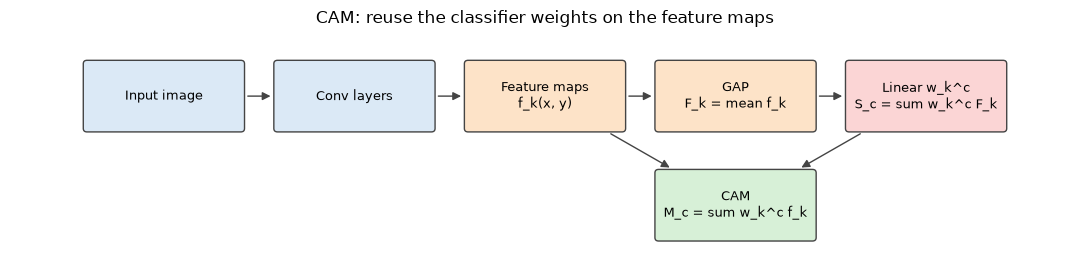

In [2]:
draw_diagram(
    {
        "img": (0, 1, "Input image", "#dbe9f6"),
        "cnn": (2.6, 1, "Conv layers", "#dbe9f6"),
        "f": (5.2, 1, "Feature maps\nf_k(x, y)", "#fde3c8"),
        "gap": (7.8, 1, "GAP\nF_k = mean f_k", "#fde3c8"),
        "fc": (10.4, 1, "Linear w_k^c\nS_c = sum w_k^c F_k", "#fbd5d5"),
        "cam": (7.8, -0.6, "CAM\nM_c = sum w_k^c f_k", "#d7f0d7"),
    },
    [("img", "cnn"), ("cnn", "f"), ("f", "gap"), ("gap", "fc"), ("f", "cam"), ("fc", "cam")],
    figsize=(11, 2.9), title="CAM: reuse the classifier weights on the feature maps", box_size=(2.1, 0.95),
)

## 1.2 GAP과 CAM 수식

마지막 합성곱층의 $k$번째 특징 맵을 $f_k(x, y)$라고 합시다. 전체 위치 수를 $Z$라고 하면 GAP은 다음과 같습니다.

$$F_k = \frac{1}{Z} \sum_{x, y} f_k(x, y)$$

클래스 $c$의 점수는 $S_c = \sum_k w_k^c F_k + b_c$입니다. 여기서 $b_c$는 선형층의 편향입니다. 합의 순서를 바꾸면 다음 식이 나옵니다.

$$S_c = \frac{1}{Z} \sum_{x, y} \underbrace{\sum_k w_k^c f_k(x, y)}_{M_c(x, y)} + b_c$$

가운데 $M_c(x, y)$가 바로 **CAM**입니다. 즉, 점수는 위치별 기여 $M_c$의 평균입니다. "뒤로 간다"고 표현하지만 역전파를 하는 것은 아닙니다. 선형층의 가중치를 특징 맵에 그대로 다시 곱할 뿐입니다.

그림 출처: [GAP 계산 예](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-6-gap.png), [가중합으로 히트맵을 만드는 과정](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-9-cam-1.png). 그림에 있는 3x3 특징 맵 4장의 숫자로 직접 계산해 봅시다. 그림의 평균 3, 5, 2, 1은 어림값이고, 실제 값은 아래 출력과 같습니다(넷째는 0.11). 가중치는 예시로 정한 값입니다.

In [3]:
# 3x3 크기의 특징 맵 4장 (채널, 세로, 가로)
feature_maps = torch.tensor([
    [[2, 4, 1], [2, 3, 4], [4, 2, 6]],
    [[2, 5, 4], [1, 6, 7], [9, 3, 5]],
    [[2, 4, 2], [1, 3, 3], [1, 1, 1]],
    [[0, 2, 3], [1, 2, -4], [-1, -3, 1]],
], dtype=torch.float32)

gap = feature_maps.mean(dim=(1, 2))                   # 채널마다 숫자 하나
class_weights = torch.tensor([0.5, 0.2, 0.1, -0.3])   # 어떤 클래스의 선형층 가중치라고 합시다
score = (class_weights * gap).sum()                   # 분류 점수 (편향은 생략)

# 가중치를 채널 축에 맞게 늘려 특징 맵에 곱한 뒤 채널끼리 더하면 위치별 기여가 된다
cam_toy = (class_weights[:, None, None] * feature_maps).sum(dim=0)

print("GAP:", gap)
print("점수:", score.item())
print("CAM:\n", cam_toy)
print("CAM의 평균:", cam_toy.mean().item(), "(점수와 같아야 합니다)")
assert torch.isclose(cam_toy.mean(), score)

GAP: tensor([3.1111, 4.6667, 2.0000, 0.1111])
점수: 2.6555557250976562
CAM:
 tensor([[1.6000, 2.8000, 0.6000],
        [1.0000, 2.4000, 4.9000],
        [4.2000, 2.6000, 3.8000]])
CAM의 평균: 2.6555557250976562 (점수와 같아야 합니다)


## 1.3 실제 모델로 CAM 그리기

GoogLeNet, ResNet, DenseNet, SqueezeNet은 이미 끝부분에 GAP을 쓰므로 바로 CAM을 계산할 수 있습니다. 아래 코드는 다음 순서로 동작합니다.

1. **순전파 훅(forward hook)** 을 마지막 합성곱 블록에 걸어 특징 맵을 저장합니다. 훅은 해당 층을 지날 때 자동으로 불리는 함수입니다.
2. `parameters()`의 끝에서 두 번째, 즉 마지막 층의 가중치를 꺼냅니다. 맨 끝은 편향입니다.
3. 원하는 클래스의 가중치와 특징 맵을 곱해 더합니다.

클래스 이름은 사전학습 가중치에 들어 있는 `weights.meta["categories"]`를 씁니다. 더 다듬어진 이름이 필요하면 [imagenet-simple-labels.json](https://github.com/anishathalye/imagenet-simple-labels/blob/master/imagenet-simple-labels.json)을 내려받아 `json.load`로 읽어도 됩니다.

사진은 미국 백악관 사진실이 1998년에 찍은 개 Buddy와 고양이 Socks입니다. 미국 정부 저작물로 퍼블릭 도메인입니다. ([위키미디어 공용, 미국 국립문서보관소](https://commons.wikimedia.org/wiki/File:Photograph_of_Socks_the_Cat_and_Buddy_the_Dog_Sitting_on_the_South_Lawn_at_the_White_House_-_DPLA_-_8c3cc0af0ad850a04937e879fdbb103f.jpg), 공용에 있는 잘라 낸 판을 씁니다.)

주의할 점이 몇 가지 있습니다.

- 이름이 `weight_softmax`지만 softmax를 거친 값이 아닙니다. **softmax 바로 앞 선형층의 가중치**입니다.
- SqueezeNet은 선형층 대신 `Conv2d(512, 1000, 1)`로 클래스 점수를 만들고, 그 뒤에 ReLU와 평균 풀링을 둡니다. DenseNet도 특징과 GAP 사이에 ReLU가 있습니다. 그래서 두 모델에서는 1.2절의 등식이 정확히 성립하지 않고, 근사로 쓰게 됩니다. 이 절의 끝에서 ResNet으로 정확히 검산합니다.
- `cv2.imread`와 `applyColorMap`은 색 순서가 BGR입니다. `matplotlib`은 RGB를 기대하므로 보여 주기 전에 뒤집어야 색이 맞습니다.
- 인터넷 예제에서 `Variable`이나 `pretrained=True`를 보면 각각 그냥 텐서와 `weights=`로 읽으면 됩니다. 지금 쓰는 방식은 아래 코드와 같습니다.

[SqueezeNet] 특징 맵 (1, 512, 13, 13), 가중치 (1000, 512)
  0.452 -> Irish setter
  0.162 -> Sussex spaniel
  0.085 -> Newfoundland
  0.048 -> English springer
  0.041 -> cocker spaniel
[ResNet] 특징 맵 (1, 512, 7, 7), 가중치 (1000, 512)
  0.260 -> flat-coated retriever
  0.176 -> Newfoundland
  0.103 -> Irish setter
  0.055 -> groenendael
  0.054 -> Tibetan mastiff


[DenseNet] 특징 맵 (1, 2208, 7, 7), 가중치 (1000, 2208)
  0.218 -> Irish setter
  0.187 -> vizsla
  0.135 -> flat-coated retriever
  0.060 -> kelpie
  0.055 -> Sussex spaniel


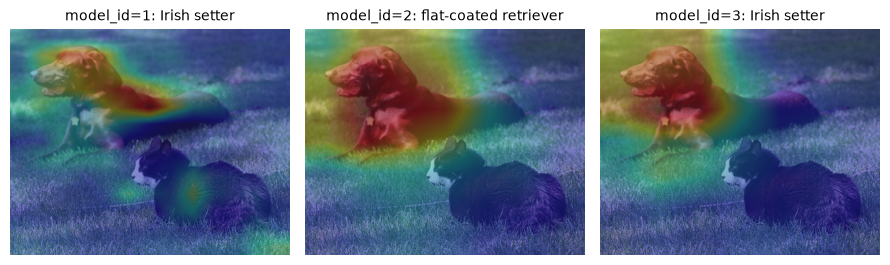

In [4]:
# GAP을 쓰는 모델과, 그 모델의 마지막 합성곱 블록 이름
def load_cam_model(model_id: int) -> tuple[nn.Module, str]:
    """model_id에 맞는 사전학습 모델과 마지막 합성곱 블록 이름을 돌려줍니다."""
    if model_id == 1:
        return models.squeezenet1_1(weights="DEFAULT"), "features"
    if model_id == 2:
        return models.resnet18(weights="DEFAULT"), "layer4"
    if model_id == 3:
        return models.densenet161(weights="DEFAULT"), "features"
    raise ValueError(f"model_id는 1, 2, 3 중 하나여야 합니다: {model_id}")


def return_cam(feature_conv: np.ndarray, weight_softmax: np.ndarray, class_idx: list[int]) -> list[np.ndarray]:
    """특징 맵과 가중치로 클래스별 CAM을 만들어 0~255 범위의 256x256 그림으로 돌려줍니다."""
    size_upsample = (256, 256)
    _, nc, h, w = feature_conv.shape
    output_cam = []
    for idx in class_idx:
        # M_c = sum_k w_k^c f_k 를 행렬 곱 한 번으로 계산한다
        cam = weight_softmax[idx].dot(feature_conv.reshape((nc, h * w)))
        cam = cam.reshape(h, w)
        cam = cam - np.min(cam)
        cam_img = cam / np.max(cam)
        output_cam.append(cv2.resize(np.uint8(255 * cam_img), size_upsample))
    return output_cam


preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


def run_cam(model_id: int, image_file: Path) -> tuple[np.ndarray, str]:
    """모델 하나로 예측 상위 5개를 출력하고, 1위 클래스의 CAM을 사진에 겹친 RGB 그림을 돌려줍니다."""
    net, finalconv_name = load_cam_model(model_id)
    net.eval()

    features_blobs = []

    def hook_feature(module: nn.Module, inputs: tuple, output: torch.Tensor) -> None:
        features_blobs.append(output.detach().cpu().numpy())

    handle = net._modules.get(finalconv_name).register_forward_hook(hook_feature)

    # 마지막 층의 가중치. 맨 끝([-1])은 편향이므로 끝에서 두 번째를 꺼낸다
    params = list(net.parameters())
    weight_softmax = np.squeeze(params[-2].detach().numpy())

    img_tensor = preprocess(Image.open(image_file).convert("RGB"))
    with torch.no_grad():
        logit = net(img_tensor.unsqueeze(0))
    handle.remove()

    probs, idx = F.softmax(logit, dim=1).squeeze().sort(descending=True)
    print(f"[{net.__class__.__name__}] 특징 맵 {features_blobs[0].shape}, 가중치 {weight_softmax.shape}")
    for i in range(5):
        print(f"  {probs[i].item():.3f} -> {CATEGORIES[idx[i].item()]}")

    cams = return_cam(features_blobs[0], weight_softmax, [idx[0].item()])
    img = cv2.imread(str(image_file))
    height, width, _ = img.shape
    heatmap = cv2.applyColorMap(cv2.resize(cams[0], (width, height)), cv2.COLORMAP_JET)
    result = np.clip(heatmap * 0.3 + img * 0.5, 0, 255).astype(np.uint8)
    return result[:, :, ::-1], CATEGORIES[idx[0].item()]     # BGR을 RGB로 뒤집는다


fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, model_id in zip(axes, [1, 2, 3]):
    overlay, top_name = run_cam(model_id, BOTH_IMAGE)
    ax.imshow(overlay)
    ax.set_title(f"model_id={model_id}: {top_name}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

세 모델의 1위 예측이 서로 다를 수 있고, 히트맵의 위치도 그 예측을 따라 달라집니다. 이 사진에는 개와 고양이가 함께 있으므로 "무엇에 대한 CAM인가"가 중요합니다. 같은 특징 맵이라도 **가중치를 어느 클래스의 것으로 쓰느냐**에 따라 다른 곳을 가리킵니다. 다음 셀에서 확인합니다.

ResNet18로 개와 고양이 클래스의 CAM을 각각 그리고, 1.2절의 등식도 실제 모델로 검산합니다. ResNet은 `layer4` 바로 뒤가 GAP과 선형층이므로 다음이 정확히 성립해야 합니다.

$$\text{logit}_c = \frac{1}{Z}\sum_{x,y} M_c(x, y) + b_c$$

특징 맵 크기: torch.Size([512, 7, 7])
flat-coated retriever 로짓 11.44613 / CAM 평균 + 편향 11.44613
tiger cat       로짓 3.15486 / CAM 평균 + 편향 3.15486


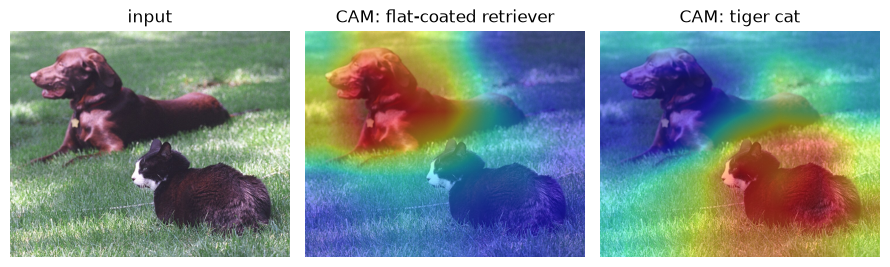

In [5]:
cam_net = models.resnet18(weights="DEFAULT").eval()
captured = {}
handle = cam_net.layer4.register_forward_hook(lambda module, inputs, output: captured.update(features=output.detach()))

both_pil = Image.open(BOTH_IMAGE).convert("RGB")
both_tensor = preprocess(both_pil).unsqueeze(0)
with torch.no_grad():
    both_logit = cam_net(both_tensor)
handle.remove()

features = captured["features"][0]     # (512, 7, 7)
print("특징 맵 크기:", features.shape)

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
axes[0].imshow(both_pil)
axes[0].set_title("input")
for ax, class_idx in zip(axes[1:], [DOG_CLASS, CAT_CLASS]):
    w_c = cam_net.fc.weight[class_idx].detach()
    b_c = cam_net.fc.bias[class_idx].detach()
    cam = (w_c[:, None, None] * features).sum(dim=0)

    recon = cam.mean() + b_c
    print(f"{CATEGORIES[class_idx]:15s} 로짓 {both_logit[0, class_idx].item():.5f} / CAM 평균 + 편향 {recon.item():.5f}")
    assert torch.isclose(recon, both_logit[0, class_idx], atol=1e-3)

    cam_up = F.interpolate(cam[None, None], size=both_pil.size[::-1], mode="bilinear", align_corners=False)[0, 0]
    ax.imshow(both_pil)
    ax.imshow(cam_up.numpy(), cmap="jet", alpha=0.45)
    ax.set_title(f"CAM: {CATEGORIES[class_idx]}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 1.4 완전 합성곱으로 바꾸기: 입력 크기의 제약 없애기

선형층은 사실 1x1 합성곱과 같습니다. 선형층의 가중치를 `Conv2d(512, 1000, kernel_size=1)`에 옮겨 담으면, GAP을 없애도 **위치마다 1000개 클래스 점수**가 나옵니다. 이렇게 하면 다음이 가능해집니다.

- 입력 크기에 제약이 없어집니다. 크기가 커지면 출력 지도의 해상도도 함께 커집니다.
- 위치별 점수에 softmax를 적용해 "이 위치가 해당 클래스일 확률"을 그릴 수 있습니다. CAM과 사실상 같은 정보이고, 클래스끼리의 경쟁까지 반영한다는 점만 다릅니다.

기존 `forward`의 소스는 IPython에서 `model.forward??`, `model._forward_impl??`로 볼 수 있습니다. 그 소스를 복사해 뒷부분만 바꾼 다음, `__get__`으로 이 인스턴스의 메서드로 끼워 넣습니다(몽키 패칭). 클래스 정의를 건드리지 않고 이 객체 하나만 바꾸는 파이썬 기법입니다.

사전학습 모델로 추론할 때는 반드시 `model.eval()`을 호출합니다. 빼먹으면 BatchNorm이 학습 모드로 움직입니다. 흔한 실수입니다.

In [6]:
fc_model = torchvision.models.resnet34(weights="DEFAULT").eval()


def forward_conv_only(self: torchvision.models.ResNet, x: torch.Tensor) -> torch.Tensor:
    """ResNet의 뒷부분(GAP, flatten, fc)을 1x1 합성곱으로 바꾼 forward입니다."""
    x = self.conv1(x)
    x = self.bn1(x)
    x = self.relu(x)
    x = self.maxpool(x)

    x = self.layer1(x)
    x = self.layer2(x)
    x = self.layer3(x)
    x = self.layer4(x)

    # 아래 세 층을 없애고...
    # x = self.avgpool(x)
    # x = torch.flatten(x, 1)
    # x = self.fc(x)

    # ...1x1 합성곱 한 층으로 대신한다
    x = self.conv1x1(x)
    return x


# 이 객체의 forward만 새 함수로 바꾼다
fc_model.forward = forward_conv_only.__get__(fc_model, torchvision.models.ResNet)
fc_model.conv1x1 = nn.Conv2d(512, 1000, kernel_size=1)
# 선형층 가중치 (1000, 512)에 차원 두 개를 덧붙이면 합성곱 가중치 (1000, 512, 1, 1)이 된다
fc_model.conv1x1.weight.data = fc_model.fc.weight.data[..., None, None]
fc_model.conv1x1.bias.data = fc_model.fc.bias.data
fc_model.eval();

### 모델 시험하기

크기가 달라도 잘 돌아가는지 봅시다. 출력 지도는 입력의 1/32 크기입니다.

In [7]:
with torch.no_grad():
    for side in [224, 512, 1024, 2048]:
        print(f"{side}x{side} --->", fc_model(torch.randn(1, 3, side, side)).shape)

224x224 ---> torch.Size([1, 1000, 7, 7])
512x512 ---> torch.Size([1, 1000, 16, 16])


1024x1024 ---> torch.Size([1, 1000, 32, 32])


2048x2048 ---> torch.Size([1, 1000, 64, 64])


1x1 합성곱으로 옮긴 것이 맞는지도 확인합니다. 위치별 점수를 평균하면 원래 ResNet의 로짓과 같아야 합니다. GAP이 위치별 평균이기 때문입니다.

In [8]:
plain_resnet34 = torchvision.models.resnet34(weights="DEFAULT").eval()
with torch.no_grad():
    logits_plain = plain_resnet34(both_tensor)
    logits_map = fc_model(both_tensor)
print("지도 크기:", logits_map.shape)
print("평균과 원래 로짓의 최대 차이:", (logits_map.mean(dim=(2, 3)) - logits_plain).abs().max().item())
assert torch.allclose(logits_map.mean(dim=(2, 3)), logits_plain, atol=1e-3)

지도 크기: torch.Size([1, 1000, 7, 7])
평균과 원래 로짓의 최대 차이: 1.9073486328125e-06


### 위치별 확률 지도 그리기

비슷한 클래스 여러 개를 묶어 보고 싶을 때는 **확률을 더하면** 됩니다. 코기의 두 품종(263 Pembroke, 264 Cardigan)이나, 아래에서 쓰는 고양이의 281(tabby)과 282(tiger cat)가 그런 경우입니다.

`image.thumbnail`은 사진을 **줄이기만** 합니다. 키울 수도 있어야 하므로 `ImageOps.contain`을 씁니다. 가로세로 비율은 그대로 유지합니다.

In [9]:
fc_transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def generate_attention(path: Path, class_indexes: list[int], size: tuple[int, int] = (224, 224)) -> None:
    """사진 한 장에 대해 지정한 클래스들의 위치별 확률 지도를 그립니다."""
    image = ImageOps.contain(Image.open(path).convert("RGB"), size, Image.LANCZOS)
    print("Image shape:", image.size)
    tensor = fc_transform(image)[None]

    with torch.no_grad():
        logits = fc_model(tensor)[0]
    probs = torch.softmax(logits, dim=0)                 # 위치마다 1000개 클래스에 대한 확률
    attention_map = probs[class_indexes].sum(dim=0)      # 고른 클래스들의 확률을 더한다

    plt.figure(figsize=(8, 2.8))
    ax = plt.subplot(1, 3, 1)
    ax.axis("off")
    plt.imshow(image)

    ax = plt.subplot(1, 3, 2)
    ax.axis("off")
    plt.imshow(attention_map)
    plt.title(f"map {tuple(attention_map.shape)}", fontsize=9)

    ax = plt.subplot(1, 3, 3)
    ax.axis("off")
    ax.imshow(image)
    ax.imshow(attention_map, alpha=0.6, interpolation="bilinear", cmap="magma",
              extent=(0, image.size[0], image.size[1], 0))
    plt.tight_layout()
    plt.show()

### 개 한 품종의 지도 (flat-coated retriever, 클래스 205)

Image shape: (224, 181)


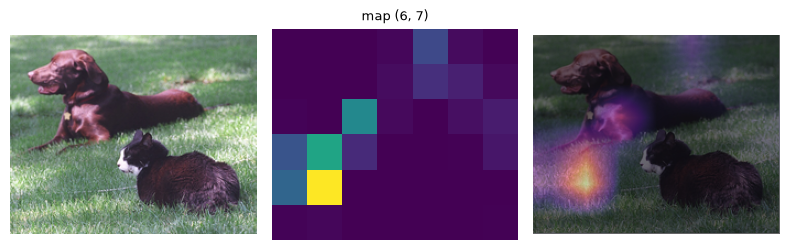

In [10]:
generate_attention(BOTH_IMAGE, class_indexes=[DOG_CLASS])

### 고양이 두 품종을 묶은 지도 (281, 282)

Image shape: (224, 181)


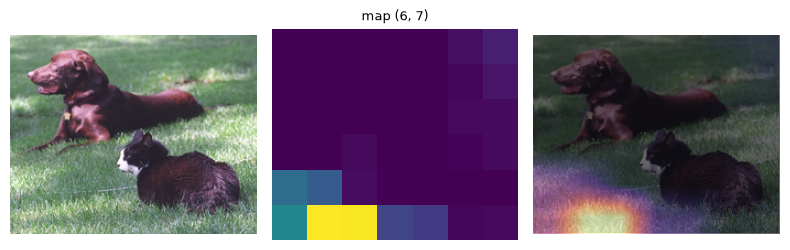

In [11]:
generate_attention(BOTH_IMAGE, class_indexes=[281, 282])

### 쓸 만한 요령: 사진을 키워서 넣기

입력을 키우면 출력 지도의 해상도가 커져서 위치를 더 잘게 볼 수 있습니다. 대신 물체가 모델이 학습한 크기보다 커지므로 점수 자체는 달라집니다.

Image shape: (512, 414)


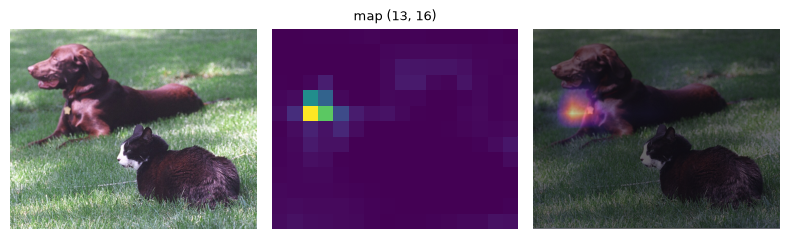

In [12]:
generate_attention(BOTH_IMAGE, class_indexes=[DOG_CLASS], size=(512, 512))

Image shape: (512, 414)


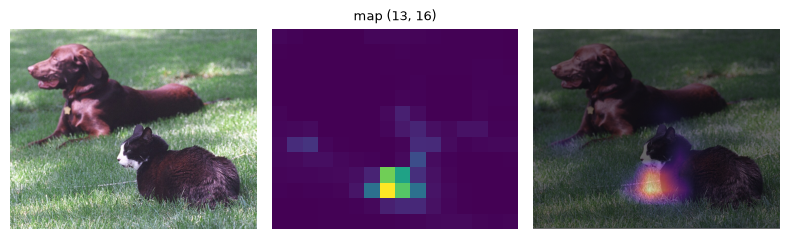

In [13]:
generate_attention(BOTH_IMAGE, class_indexes=[281, 282], size=(512, 512))

## 1.5 CAM의 단점

- **GAP 구조여야 합니다.** VGG처럼 flatten 뒤에 완전연결층이 있는 모델은 끝부분을 GAP으로 바꾼 뒤 다시 파인튜닝해야 합니다.
- **마지막 합성곱층에 대해서만** CAM을 얻습니다. 마지막 층 특징 맵은 해상도가 낮아서(224 입력에 7x7) 히트맵이 뭉툭합니다.

Q. 7x7 지도를 224x224로 키워 그렸습니다. 그림이 부드러워졌다면 위치를 정밀하게 안다는 뜻일까요?

<details><summary>답</summary>

아닙니다. 양선형 보간은 7x7의 값을 매끄럽게 이어 붙일 뿐이고 정보를 늘리지 않습니다. 위치 정밀도는 여전히 32픽셀 단위입니다. 더 정밀한 위치가 필요하면 앞쪽 층까지 활용해야 하며, 3교시의 LayerCAM이 그 방법입니다.

</details>

GAP 제약은 다음 교시의 Grad-CAM이 없앱니다. 낮은 해상도와 앞쪽 층 문제는 Guided Grad-CAM과 3교시의 LayerCAM이 다룹니다.

### 실습 1. CAM 함수 만들기

특징 맵 `features`(채널, 세로, 가로)와 선형층 `fc`, 클래스 번호를 받아 CAM을 돌려주는 함수 `compute_cam`을 만드세요. `cam_net`과 위에서 저장한 `features`로 **로짓 2위 클래스**의 CAM을 계산하고, `CAM 평균 + 편향 = 로짓`을 assert로 확인하세요.

In [14]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def compute_cam(features: torch.Tensor, fc: nn.Linear, class_idx: int) -> torch.Tensor:
    """M_c = sum_k w_k^c f_k 를 계산합니다."""
    return (fc.weight[class_idx].detach()[:, None, None] * features).sum(dim=0)

second_class = both_logit[0].topk(2).indices[1].item()
second_cam = compute_cam(features, cam_net.fc, second_class)
assert second_cam.shape == (7, 7)
assert torch.isclose(second_cam.mean() + cam_net.fc.bias[second_class], both_logit[0, second_class], atol=1e-3)
print(CATEGORIES[second_class], second_cam.mean().item())
```
</details>

---
# 2교시. Grad-CAM: 어떤 모델에든 쓰는 CAM

## 2.1 아이디어와 수식

CAM의 가중치 $w_k^c$는 "채널 $k$가 클래스 점수에 얼마나 기여하는가"였습니다. 이 기여도는 **기울기**로도 잴 수 있습니다. 채널 $k$의 값을 조금 늘렸을 때 점수 $y^c$가 얼마나 변하는지 보면 되니까요. Grad-CAM은 선형층 가중치 대신 기울기의 평균을 씁니다. ([논문](https://openaccess.thecvf.com/content_iccv_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html), [arXiv](https://arxiv.org/abs/1610.02391))

$$\alpha_k^c = \frac{1}{Z} \sum_i \sum_j \frac{\partial y^c}{\partial A_{ij}^k}, \qquad L^c_{\text{Grad-CAM}} = \text{ReLU}\left(\sum_k \alpha_k^c A^k\right)$$

- $A^k$: 보고 싶은 합성곱층의 $k$번째 특징 맵
- $\alpha_k^c$: 채널 $k$의 중요도. 기울기를 위치에 대해 평균한 값입니다
- $y^c$: softmax 이전의 클래스 점수
- ReLU: 클래스 점수를 **높이는** 쪽의 영향만 남깁니다. 음수 영역은 다른 클래스의 근거일 가능성이 큽니다

미분만 되면 되므로 GAP이 없어도, 마지막 층이 아니어도 됩니다. 분류뿐 아니라 이미지 캡셔닝이나 질의응답 모델에서도, 설명하고 싶은 출력의 기울기를 내려보내면 같은 방식으로 쓸 수 있습니다.

그림 출처: [Grad-CAM 요약](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-20-grad-cam-summary.png), [논문의 전체 구조(분류, 캡셔닝, 질의응답)](https://1.bp.blogspot.com/-PqcHAqpHokU/X8n_igvX-FI/AAAAAAAABZ8/s5ZXNHDAEtIGa0wrM03p7J7Tdz7D8_1jQCPcBGAYYCw/w647-h295/image.png), [논문의 결과: 고양이와 개에 대한 Guided Backprop, Grad-CAM, Guided Grad-CAM](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-21-grad-cam-result.png). 흐름은 아래와 같습니다.

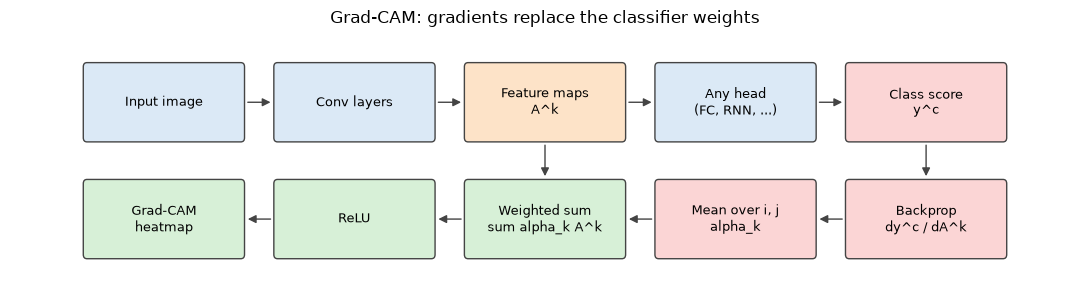

In [15]:
draw_diagram(
    {
        "img": (0, 1.4, "Input image", "#dbe9f6"),
        "cnn": (2.6, 1.4, "Conv layers", "#dbe9f6"),
        "a": (5.2, 1.4, "Feature maps\nA^k", "#fde3c8"),
        "head": (7.8, 1.4, "Any head\n(FC, RNN, ...)", "#dbe9f6"),
        "y": (10.4, 1.4, "Class score\ny^c", "#fbd5d5"),
        "g": (10.4, 0, "Backprop\ndy^c / dA^k", "#fbd5d5"),
        "alpha": (7.8, 0, "Mean over i, j\nalpha_k", "#fbd5d5"),
        "sum": (5.2, 0, "Weighted sum\nsum alpha_k A^k", "#d7f0d7"),
        "relu": (2.6, 0, "ReLU", "#d7f0d7"),
        "cam": (0, 0, "Grad-CAM\nheatmap", "#d7f0d7"),
    },
    [("img", "cnn"), ("cnn", "a"), ("a", "head"), ("head", "y"), ("y", "g"), ("g", "alpha"), ("alpha", "sum"),
     ("a", "sum"), ("sum", "relu"), ("relu", "cam")],
    figsize=(11, 3.1), title="Grad-CAM: gradients replace the classifier weights", box_size=(2.1, 0.85),
)

## 2.2 검산: GAP 구조에서 Grad-CAM은 CAM과 같다

GAP과 선형층만 있는 구조에서 점수는 $y^c = \sum_k w_k^c \frac{1}{Z}\sum_{ij} A_{ij}^k + b_c$입니다. 이것을 $A_{ij}^k$로 미분하면 위치에 상관없이 $\frac{\partial y^c}{\partial A_{ij}^k} = \frac{w_k^c}{Z}$입니다. 평균을 내도 그대로이므로 다음이 성립합니다.

$$\alpha_k^c = \frac{w_k^c}{Z}$$

즉, **ReLU 이전의 Grad-CAM은 CAM을 $Z$로 나눈 것**입니다. ResNet18의 `layer4`에서는 $Z = 7 \times 7 = 49$입니다. 코드로 확인합니다. 여기서는 훅 대신 `torch.autograd.grad`로 특징 맵에 대한 기울기를 직접 구합니다.

In [16]:
captured = {}
handle = cam_net.layer4.register_forward_hook(lambda module, inputs, output: captured.update(features=output))
logit = cam_net(both_tensor)         # 이번에는 기울기가 필요하므로 no_grad를 쓰지 않는다
handle.remove()

activation = captured["features"]
gradient = torch.autograd.grad(logit[0, DOG_CLASS], activation)[0]

alpha = gradient.mean(dim=(2, 3))[0]                  # 채널마다 숫자 하나
weight = cam_net.fc.weight[DOG_CLASS].detach()
z = activation.shape[2] * activation.shape[3]

grad_cam_raw = (alpha[:, None, None] * activation[0].detach()).sum(dim=0)
cam_raw = (weight[:, None, None] * activation[0].detach()).sum(dim=0)

print("Z =", z)
print("alpha * Z 와 w 의 최대 차이:", (alpha * z - weight).abs().max().item())
print("Grad-CAM * Z 와 CAM 의 최대 차이:", (grad_cam_raw * z - cam_raw).abs().max().item())
assert torch.allclose(alpha * z, weight, atol=1e-4)
assert torch.allclose(grad_cam_raw * z, cam_raw, atol=1e-2)

Z = 49
alpha * Z 와 w 의 최대 차이: 4.470348358154297e-08
Grad-CAM * Z 와 CAM 의 최대 차이: 1.9073486328125e-06


## 2.3 CIFAR-10에서 학습 방법별 Grad-CAM 비교

[FMix 논문 저장소](https://github.com/ecs-vlc/fmix)는 CIFAR-10용 PreAct ResNet18 사전학습 모델 네 개(기본, MixUp, FMix, FMix+MixUp)를 `torch.hub`로 제공합니다. 호출 형태는 다음과 같습니다. 여기서는 실행하지 않습니다.

```python
baseline_net = torch.hub.load('ecs-vlc/FMix:master', 'preact_resnet18_cifar10_baseline', pretrained=True)
fmix_net = torch.hub.load('ecs-vlc/FMix:master', 'preact_resnet18_cifar10_fmix', pretrained=True)
mixup_net = torch.hub.load('ecs-vlc/FMix:master', 'preact_resnet18_cifar10_mixup', pretrained=True)
fmix_plus_net = torch.hub.load('ecs-vlc/FMix:master', 'preact_resnet18_cifar10_fmixplusmixup', pretrained=True)
```

`torch.hub.load`는 GitHub 저장소의 코드를 내려받아 **실행**합니다(7강에도 나옵니다). 믿을 수 있는 저장소에만 쓰세요. 이 저장소의 코드는 개발이 끝난 `torchbearer`에 의존합니다. 그래서 여기서는 **같은 네 가지 섞기 조건으로 모델을 직접 학습**합니다. 같은 것은 섞기 조건뿐입니다. 저장소의 모델은 충분히 학습된 PreAct ResNet18이고, 여기서는 일반 ResNet18을 6에폭만 학습합니다.

MixUp과 FMix는 두 이미지를 섞어 학습하는 증강 방법입니다. 증강 일반은 4강에서 다루었습니다.

- MixUp: 두 이미지를 픽셀 단위로 비율 $\lambda$만큼 섞습니다.
- FMix: 저주파 노이즈로 만든 **덩어리진 마스크**로 한 이미지의 일부를 다른 이미지로 잘라 넣습니다. ([FMix 논문](https://arxiv.org/abs/2002.12047))

핵심은 **라벨도 같은 비율로 섞는다**는 점입니다. 이미지가 $\lambda$만큼 $y_a$이고 $1-\lambda$만큼 $y_b$이면, 손실은 두 라벨의 교차 엔트로피를 같은 비율로 더한 값입니다.

$$\text{loss} = \lambda \, \text{CE}(\text{out}, y_a) + (1 - \lambda) \, \text{CE}(\text{out}, y_b)$$

$\lambda$는 Beta(1, 1) 분포에서 뽑습니다. 이 분포는 0과 1 사이의 균일 분포입니다. FMix는 마스크의 실제 면적을 $\lambda$로 씁니다.

CIFAR-10은 32x32로 작으므로 ResNet18의 첫 층을 3x3으로 바꾸고 최대 풀링을 뺍니다. 짧은 학습이므로 아래 정확도로 방법 간 우열을 판단하면 안 됩니다. 여기서의 목적은 Grad-CAM이 어떻게 달라 보이는지 관찰하는 것입니다.

데이터는 메모리에 한 번에 올려 두면 에폭마다 변환할 필요가 없어 빠릅니다. 또 학습한 가중치를 파일로 저장해 두어, 셀을 다시 실행할 때 학습을 건너뜁니다.

In [17]:
CIFAR_MEAN = torch.tensor([0.4914, 0.4822, 0.4465])
CIFAR_STD = torch.tensor([0.2023, 0.1994, 0.2010])
# 정규화를 되돌리는 변환: x = (y - (-m/s)) / (1/s) = y * s + m
inv_norm = transforms.Normalize((-0.4914 / 0.2023, -0.4822 / 0.1994, -0.4465 / 0.2010),
                                (1 / 0.2023, 1 / 0.1994, 1 / 0.2010))


def load_cifar_tensors(train: bool) -> tuple[torch.Tensor, torch.Tensor]:
    """CIFAR-10 전체를 정규화된 텐서로 읽습니다."""
    dataset = torchvision.datasets.CIFAR10(root="./data", train=train, download=True)
    images = torch.from_numpy(dataset.data).permute(0, 3, 1, 2).float() / 255.0
    images = (images - CIFAR_MEAN[None, :, None, None]) / CIFAR_STD[None, :, None, None]
    return images, torch.tensor(dataset.targets)


cifar_x_train, cifar_y_train = load_cifar_tensors(train=True)
cifar_x_test, cifar_y_test = load_cifar_tensors(train=False)
print(cifar_x_train.shape, cifar_x_test.shape)


def make_cifar_resnet18() -> nn.Module:
    """32x32 입력에 맞게 앞부분을 고친 ResNet18을 만듭니다."""
    net = models.resnet18(num_classes=10)
    net.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    net.maxpool = nn.Identity()
    return net


def fmix_mask(height: int, width: int, lam: float, decay: float = 3.0) -> torch.Tensor:
    """저주파 노이즈의 상위 lam 비율을 1로 둔 이진 마스크를 만듭니다."""
    freq_y = torch.fft.fftfreq(height)[:, None]
    freq_x = torch.fft.rfftfreq(width)[None, :]
    freq = torch.sqrt(freq_x ** 2 + freq_y ** 2).clamp(min=1.0 / max(height, width))
    # 주파수가 높을수록 진폭을 줄이면, 역변환했을 때 덩어리진 노이즈가 된다
    spectrum = torch.randn(height, width // 2 + 1, dtype=torch.complex64) / freq ** decay
    noise = torch.fft.irfft2(spectrum, s=(height, width))
    num_on = int(round(lam * height * width))
    mask = torch.zeros(height * width)
    mask[noise.flatten().argsort(descending=True)[:num_on]] = 1.0
    return mask.view(height, width)


def mix_batch(x: torch.Tensor, mode: str, step: int) -> tuple[torch.Tensor, torch.Tensor, float]:
    """모드에 맞게 배치를 섞고, 섞인 이미지와 짝의 순서, 실제 비율을 돌려줍니다."""
    perm = torch.randperm(x.size(0), device=x.device)
    if mode == "baseline":
        return x, perm, 1.0
    # 두 방법을 함께 쓰는 조건은 배치마다 번갈아 적용한다
    use_fmix = mode == "fmix" or (mode == "fmix+mixup" and step % 2 == 0)
    lam = float(np.random.beta(1.0, 1.0))
    if use_fmix:
        mask = fmix_mask(x.size(2), x.size(3), lam).to(x.device)
        return mask * x + (1 - mask) * x[perm], perm, mask.mean().item()
    return lam * x + (1 - lam) * x[perm], perm, lam


@torch.no_grad()
def cifar_accuracy(net: nn.Module, batch_size: int = 500) -> float:
    """테스트 집합의 정확도를 계산합니다."""
    net.eval()
    correct = 0
    for start in range(0, len(cifar_x_test), batch_size):
        pred = net(cifar_x_test[start:start + batch_size].to(device)).argmax(dim=1).cpu()
        correct += (pred == cifar_y_test[start:start + batch_size]).sum().item()
    return correct / len(cifar_x_test)


def train_cifar_model(mode: str, epochs: int, batch_size: int = 128, lr: float = 0.1) -> nn.Module:
    """지정한 섞기 방법으로 CIFAR-10 모델을 학습합니다. 저장된 가중치가 있으면 그것을 읽습니다."""
    net = make_cifar_resnet18().to(device)
    path = Path(f"cifar_{mode}_e{epochs}.pt")
    if path.exists():
        net.load_state_dict(torch.load(path, map_location=device))
        print(f"{mode:12s} 저장된 가중치 사용, 테스트 정확도 {cifar_accuracy(net):.3f}")
        return net

    set_seed()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4, nesterov=True)
    num_batches = len(cifar_x_train) // batch_size
    scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=epochs * num_batches)
    start = time.time()
    for epoch in range(epochs):
        net.train()
        order = torch.randperm(len(cifar_x_train))
        for step in range(num_batches):
            idx = order[step * batch_size:(step + 1) * batch_size]
            x, y = cifar_x_train[idx].to(device), cifar_y_train[idx].to(device)
            if torch.rand(1).item() < 0.5:     # 배치 단위 좌우 뒤집기. 간단하면서 비용이 거의 없다
                x = x.flip(dims=[3])
            x, perm, lam = mix_batch(x, mode, step)
            out = net(x)
            # 이미지를 섞은 비율 그대로 두 라벨의 손실을 섞는다
            loss = lam * F.cross_entropy(out, y) + (1 - lam) * F.cross_entropy(out, y[perm])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
    acc = cifar_accuracy(net)
    print(f"{mode:12s} {epochs} 에폭, {time.time() - start:.0f}초, 테스트 정확도 {acc:.3f}")
    torch.save(net.state_dict(), path)
    return net

torch.Size([50000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


학습된 모델 네 개를 준비합니다.

baseline     6 에폭, 199초, 테스트 정확도 0.880


mixup        6 에폭, 187초, 테스트 정확도 0.855


fmix         6 에폭, 198초, 테스트 정확도 0.856


fmix+mixup   6 에폭, 147초, 테스트 정확도 0.858


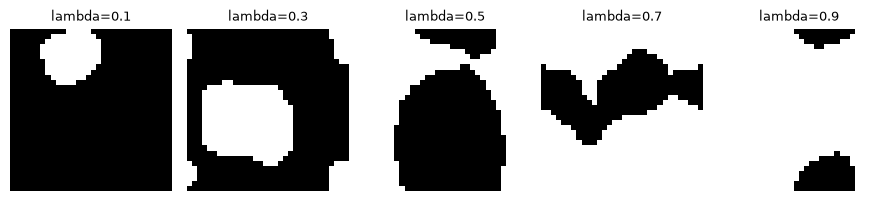

In [18]:
CIFAR_EPOCHS = 6
cifar_modes = ["baseline", "mixup", "fmix", "fmix+mixup"]
cifar_nets = {mode: train_cifar_model(mode, CIFAR_EPOCHS) for mode in cifar_modes}

# FMix 마스크가 어떻게 생겼는지 봅시다
set_seed()
fig, axes = plt.subplots(1, 5, figsize=(9, 2))
for ax, lam_value in zip(axes, [0.1, 0.3, 0.5, 0.7, 0.9]):
    ax.imshow(fmix_mask(32, 32, lam_value).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"lambda={lam_value}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 모델 감싸기

ResNet을 `layer_k`번째 자식에서 두 부분으로 나누는 래퍼입니다. 앞부분의 출력 텐서에 `register_hook`을 걸어 **역전파 때 지나가는 기울기를 저장**합니다. 1교시의 모듈 훅과 달리 텐서에 거는 훅입니다.

`x.view((1, -1))`처럼 쓰면 배치 크기가 1일 때만 동작하므로 `flatten(1)`을 씁니다. 또 이 ResNet의 자식에는 평균 풀링이 포함되므로 앞뒤 분할에서 제외합니다. `forward`에서 풀링을 직접 하기 때문입니다.

In [19]:
class ResNetCAM(nn.Module):
    """ResNet을 둘로 나누고, 나눈 지점의 특징 맵과 기울기를 꺼낼 수 있게 감쌉니다."""

    def __init__(self, net: nn.Module, layer_k: int) -> None:
        super().__init__()
        self.resnet = net
        children = list(net.children())
        convs = nn.Sequential(*children[:-2])           # 평균 풀링과 fc를 뺀 합성곱 부분
        self.first_part_conv = convs[:layer_k]
        self.second_part_conv = convs[layer_k:]
        self.linear = children[-1]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.first_part_conv(x)
        x.register_hook(self.activations_hook)
        x = self.second_part_conv(x)
        x = F.adaptive_avg_pool2d(x, (1, 1))
        return self.linear(x.flatten(1))

    def activations_hook(self, grad: torch.Tensor) -> None:
        self.gradients = grad

    def get_activations_gradient(self) -> torch.Tensor:
        return self.gradients

    def get_activations(self, x: torch.Tensor) -> torch.Tensor:
        return self.first_part_conv(x)

### Grad-CAM 계산

코드는 [implementing-grad-cam-in-pytorch](https://medium.com/@stepanulyanin/implementing-grad-cam-in-pytorch-ea0937c31e82)를 바탕으로 합니다. 수식과 코드의 대응은 다음과 같습니다.

| 수식 | 코드 |
|---|---|
| $\frac{\partial y^c}{\partial A^k}$ | `net.get_activations_gradient()` |
| $\alpha_k^c = \frac{1}{Z}\sum_{ij}\cdot$ | `gradients.mean(dim=[0, 2, 3])` |
| $\sum_k \alpha_k^c A^k$ | `(pooled[:, None, None] * activations).sum(0)` |
| ReLU | `.clamp(min=0)` |

구현에서 주의할 점이 있습니다.

- 수식대로 채널에 대해 `sum`을 씁니다. `mean`을 써도 합을 채널 수로 나눈 것이라 정규화 후의 그림은 같습니다.
- `heatmap /= torch.max(heatmap)`만 쓰면 ReLU 뒤의 값이 전부 0일 때 0으로 나누게 되어 NaN이 생깁니다. 0보다 클 때만 나눕니다.
- 히트맵과 사진을 그냥 더하면 값이 1을 크게 넘어 사진이 덮입니다. 비율을 정해 혼합합니다.

In [20]:
def superimpose_heatmap(heatmap: torch.Tensor, img: torch.Tensor) -> torch.Tensor:
    """히트맵을 입력 크기로 키워 입력 이미지와 섞습니다. 결과는 (채널, 세로, 가로)입니다."""
    resized_heatmap = cv2.resize(heatmap.numpy(), (img.shape[3], img.shape[2]))     # cv2의 크기 순서는 (가로, 세로)
    resized_heatmap = np.uint8(255 * resized_heatmap)
    resized_heatmap = cv2.applyColorMap(resized_heatmap, cv2.COLORMAP_JET)
    colored = torch.from_numpy(cv2.cvtColor(resized_heatmap, cv2.COLOR_BGR2RGB)).float() / 255.0
    original = inv_norm(img[0]).clamp(0, 1).permute(1, 2, 0)
    return (0.5 * colored + 0.5 * original).permute(2, 0, 1)


def get_grad_cam(net: ResNetCAM, img: torch.Tensor) -> torch.Tensor:
    """모델이 예측한 클래스의 Grad-CAM을 입력 이미지에 겹쳐 돌려줍니다."""
    net.eval()
    net.zero_grad()
    pred = net(img)
    pred[:, pred.argmax(dim=1)].backward()
    gradients = net.get_activations_gradient()
    pooled_gradients = gradients.mean(dim=[0, 2, 3])
    activations = net.get_activations(img).detach()[0]
    heatmap = (pooled_gradients[:, None, None] * activations).sum(dim=0).clamp(min=0)
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()
    return superimpose_heatmap(heatmap, img)

### 그림 그리기

`layer_k`로 어느 층을 볼지 정합니다. 이 ResNet의 자식은 `conv1, bn1, relu, maxpool, layer1, layer2, layer3, layer4` 순서입니다. `layer_k = 7`이면 `layer3`까지가 앞부분이고, 특징 맵 크기는 8x8입니다. 맨 윗줄이 입력 이미지이고, 아래 네 줄이 각 모델의 Grad-CAM입니다. 각 칸은 그 모델이 **자기가 예측한 클래스**에 대해 설명한 것이므로 모델끼리 예측이 다르면 다른 클래스의 히트맵입니다.

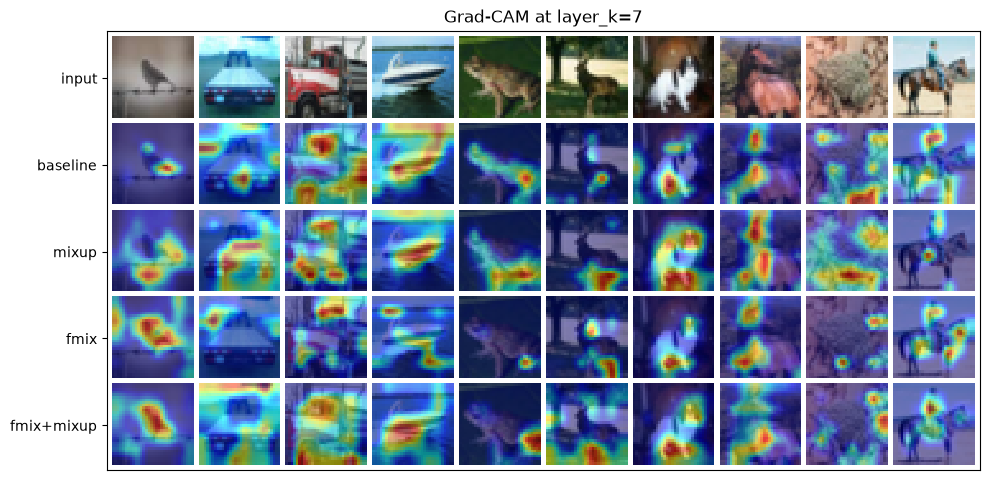

In [21]:
layer_k = 7
n_imgs = 10

cam_nets = {mode: ResNetCAM(copy.deepcopy(net).cpu(), layer_k) for mode, net in cifar_nets.items()}

set_seed()
sample_idx = torch.randperm(len(cifar_x_test))[:n_imgs]
imgs = torch.zeros(5, n_imgs, 3, 32, 32)
for i, idx in enumerate(sample_idx):
    img = cifar_x_test[idx][None]
    imgs[0][i] = inv_norm(img[0]).clamp(0, 1)
    for row, mode in enumerate(cifar_modes, start=1):
        imgs[row][i] = get_grad_cam(cam_nets[mode], img)

grid = torchvision.utils.make_grid(imgs.view(-1, 3, 32, 32), nrow=n_imgs, pad_value=1)
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.imshow(grid.permute(1, 2, 0).numpy(), interpolation="nearest")
ax.set_yticks([18 + 34 * row for row in range(5)])
ax.set_yticklabels(["input"] + cifar_modes)
ax.set_xticks([])
ax.set_title(f"Grad-CAM at layer_k={layer_k}")
plt.tight_layout()
plt.show()
torchvision.utils.save_image(imgs.view(-1, 3, 32, 32), f"gradcam_at_layer{layer_k}.png", nrow=n_imgs, pad_value=1)

그림을 관찰해 봅시다. 같은 사진에서도 모델마다 히트맵이 꽤 다르고, 물체 밖을 가리키는 칸도 있습니다. 예측이 틀린 칸일 수도 있고, 6에폭만 학습한 탓일 수도 있습니다. 이 그림만으로는 원인을 가를 수 없으므로 숙제 2와 3에서 더 살펴보세요.

## 2.4 다른 예제: 모듈 훅과 VGG16

이번에는 GAP 없이 완전연결층을 쓰는 **VGG16**에 Grad-CAM을 적용합니다. CAM으로는 불가능했던 구조입니다. 이번 구현은 모듈에 순전파 훅과 역전파 훅을 겁니다.

API 두 가지를 눈여겨보세요. 역전파 훅은 `register_full_backward_hook`을 씁니다. `register_backward_hook`은 복합 모듈에서 잘못된 기울기를 줄 수 있습니다. 크기 변경은 `F.interpolate`를 씁니다.

`torch.relu(out) / torch.max(out)`처럼 쓰면 최댓값이 0 이하일 때 음수나 0으로 나누게 됩니다. ReLU 뒤의 값으로 안전하게 나눕니다.

In [22]:
class GradCam(nn.Module):
    """지정한 층에 훅을 걸어 Grad-CAM을 계산합니다."""

    def __init__(self, model: nn.Module, module: str, layer: str) -> None:
        super().__init__()
        self.model = model
        self.module = module
        self.layer = layer
        self.handles = []
        self.register_hooks()

    def register_hooks(self) -> None:
        for module_name, module in self.model._modules.items():
            if module_name == self.module:
                for layer_name, sub_module in module._modules.items():
                    if layer_name == self.layer:
                        self.handles.append(sub_module.register_forward_hook(self.forward_hook))
                        self.handles.append(sub_module.register_full_backward_hook(self.backward_hook))

    def remove_hooks(self) -> None:
        """다 쓴 훅을 떼어 내지 않으면 이후의 호출에서도 계속 실행됩니다."""
        for handle in self.handles:
            handle.remove()

    def forward(self, input: torch.Tensor, target_index: int | None = None) -> np.ndarray:
        self.model.zero_grad()
        outs = self.model(input)
        outs = outs.squeeze()  # [1, num_classes] --> [num_classes]

        # 클래스를 지정하지 않으면 가장 큰 값을 가지는 클래스를 쓴다
        if target_index is None:
            target_index = outs.argmax().item()
            print(target_index)

        outs[target_index].backward(retain_graph=True)

        a_k = torch.mean(self.backward_result, dim=(1, 2), keepdim=True)         # [512, 1, 1]
        out = torch.sum(a_k * self.forward_result, dim=0).cpu()                  # [512, 7, 7] * [512, 1, 1]
        out = torch.relu(out)                                                    # 음수를 없앤다
        if out.max() > 0:
            out = out / out.max()                                                # 0 ~ 1 로 맞춘다 # [7, 7]
        out = F.interpolate(out[None, None], size=(224, 224), mode="bilinear", align_corners=False)  # 4D로 바꿈
        return out.cpu().detach().squeeze().numpy()

    def forward_hook(self, module: nn.Module, input: tuple, output: torch.Tensor) -> None:
        self.forward_result = torch.squeeze(output).detach()

    def backward_hook(self, module: nn.Module, grad_input: tuple, grad_output: tuple) -> None:
        self.backward_result = torch.squeeze(grad_output[0]).detach()


def preprocess_image(img: np.ndarray) -> torch.Tensor:
    """cv2로 읽은 BGR 이미지(0~1)를 RGB로 뒤집고 정규화해 모델 입력으로 만듭니다."""
    preprocessed_img = img.copy()[:, :, ::-1]
    for i in range(3):
        preprocessed_img[:, :, i] = preprocessed_img[:, :, i] - IMAGENET_MEAN[i]
        preprocessed_img[:, :, i] = preprocessed_img[:, :, i] / IMAGENET_STD[i]
    preprocessed_img = np.ascontiguousarray(np.transpose(preprocessed_img, (2, 0, 1)))
    preprocessed_img = torch.from_numpy(preprocessed_img)
    preprocessed_img.unsqueeze_(0)
    return preprocessed_img.requires_grad_(True)


def show_cam_on_image(img: np.ndarray, mask: np.ndarray, title: str) -> None:
    """히트맵과, 히트맵을 입힌 사진을 나란히 그립니다. cv2_imshow는 Colab 전용이라 matplotlib을 씁니다."""
    heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    cam = heatmap + np.float32(img)
    cam = cam / np.max(cam)
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(cam[:, :, ::-1])       # BGR을 RGB로 뒤집어 보여 준다
    axes[0].set_title(title, fontsize=10)
    axes[1].imshow(heatmap[:, :, ::-1])
    axes[1].set_title("heatmap", fontsize=10)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

VGG16의 `features`에서 30번은 마지막 `MaxPool2d`이고, 그 출력이 7x7 특징 맵입니다. 평탄화와 완전연결층이 뒤따릅니다.

ImageNet 클래스 번호는 짐작하지 말고 항상 확인합니다. 예를 들어 227번은 kelpie이고 pug는 254번입니다. 아래 출력으로 확인하세요.

{227: 'kelpie', 254: 'pug', 281: 'tabby', 205: 'flat-coated retriever', 282: 'tiger cat'}


Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)
features[30]: MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)


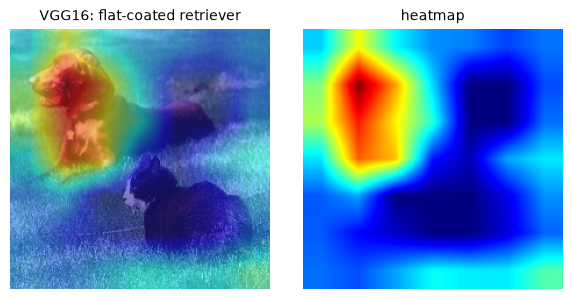

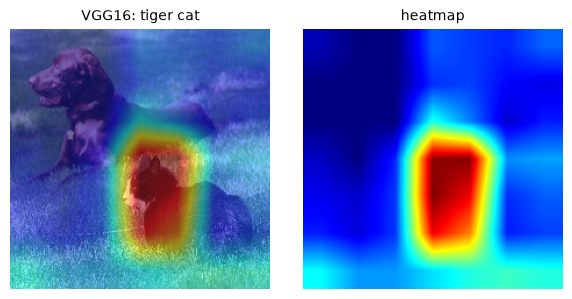

In [23]:
print({i: CATEGORIES[i] for i in [227, 254, 281, DOG_CLASS, CAT_CLASS]})

vgg_model = models.vgg16(weights="DEFAULT").eval()
print(vgg_model.classifier)
print("features[30]:", vgg_model.features[30])

grad_cam = GradCam(model=vgg_model, module="features", layer="30")

img = cv2.imread(str(BOTH_IMAGE), 1)
img = np.float32(cv2.resize(img, (224, 224))) / 255
vgg_input = preprocess_image(img)
for class_idx in [DOG_CLASS, CAT_CLASS]:
    mask = grad_cam(vgg_input, class_idx)
    show_cam_on_image(img, mask, f"VGG16: {CATEGORIES[class_idx]}")
grad_cam.remove_hooks()

개 클래스의 히트맵은 개의 머리와 가슴에, 고양이 클래스의 히트맵은 고양이의 머리와 몸 앞쪽에 모입니다. 같은 특징 맵에서 클래스만 바꿨을 뿐입니다. 다만 모델이 고양이라고 확신한 것은 아닙니다. 1.3절의 ResNet18에서 tiger cat의 로짓은 3.15로 개의 11.45보다 훨씬 낮았습니다. 히트맵은 점수가 낮은 클래스에도 그려지므로, 확률과 함께 읽어야 합니다.

## 2.5 또 다른 예제: Guided Backpropagation과 Guided Grad-CAM

Grad-CAM은 위치는 잘 잡지만 해상도가 낮습니다. **Guided Backpropagation**은 입력 픽셀까지 기울기를 내려보내는 방법으로, 윤곽처럼 세밀한 정보를 보여 주지만 클래스를 잘 구분하지 못합니다. 둘을 곱하면 세밀하면서 클래스를 구분하는 **Guided Grad-CAM**이 됩니다.

$$L_{\text{Guided Grad-CAM}} = L_{\text{Grad-CAM}} \times \text{Guided Backprop}$$

Guided Backpropagation의 핵심은 ReLU의 역전파 규칙을 바꾸는 것입니다. 순전파 입력이 양수이고 **동시에** 들어오는 기울기가 양수인 곳만 기울기를 통과시킵니다.

$$R_{\text{in}} = (x_{\text{in}} > 0) \cdot (R_{\text{out}} > 0) \cdot R_{\text{out}}$$

먼저 준비입니다. 정규화를 클래스로 묶어 두면 되돌리기도 쉽습니다. `mul`에 파이썬 리스트를 넘기면 `TypeError`가 나므로 평균과 표준편차를 텐서로 바꿉니다.

In [24]:
resnet50 = models.resnet50(weights="DEFAULT").to(device)
resnet50.eval()

img_path = BOTH_IMAGE
pil_img = Image.open(img_path).convert("RGB")
pil_img = pil_img.resize([224, 224])


def normalize(tensor: torch.Tensor, mean: list[float], std: list[float]) -> torch.Tensor:
    """(배치, 채널, 세로, 가로) 텐서를 채널별로 정규화합니다."""
    if not tensor.ndimension() == 4:
        raise TypeError("tensor should be 4D")
    mean_t = torch.FloatTensor(mean).view(1, 3, 1, 1).to(tensor.device)
    std_t = torch.FloatTensor(std).view(1, 3, 1, 1).to(tensor.device)
    return tensor.sub(mean_t).div(std_t)


def denormalize(tensor: torch.Tensor, mean: list[float], std: list[float]) -> torch.Tensor:
    """normalize를 되돌립니다."""
    mean_t = torch.FloatTensor(mean).view(1, 3, 1, 1).to(tensor.device)
    std_t = torch.FloatTensor(std).view(1, 3, 1, 1).to(tensor.device)
    return tensor.mul(std_t).add(mean_t)


class Normalize:
    """평균과 표준편차를 기억해 정규화와 복원을 함께 제공합니다."""

    def __init__(self, mean: list[float], std: list[float]) -> None:
        self.mean = mean
        self.std = std

    def __call__(self, tensor: torch.Tensor) -> torch.Tensor:
        return self.do(tensor)

    def do(self, tensor: torch.Tensor) -> torch.Tensor:
        return normalize(tensor, self.mean, self.std)

    def undo(self, tensor: torch.Tensor) -> torch.Tensor:
        return denormalize(tensor, self.mean, self.std)

    def __repr__(self) -> str:
        return self.__class__.__name__ + f"(mean={self.mean}, std={self.std})"

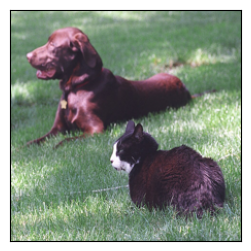

In [25]:
normalizer = Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
torch_img = torch.from_numpy(np.array(pil_img)).permute(2, 0, 1).unsqueeze(0).float().div(255).to(device)  # .cuda()를 직접 쓰면 GPU가 없을 때 실패한다
torch_img = F.interpolate(torch_img, size=(224, 224), mode="bilinear", align_corners=False)  # (1, 3, 224, 224)
normed_torch_img = normalizer(torch_img)  # (1, 3, 224, 224)
img = np.transpose(torch_img.cpu().numpy().squeeze(), (1, 2, 0))  # (224, 224, 3)

# 복원이 제대로 되는지 확인
assert torch.allclose(normalizer.undo(normed_torch_img), torch_img, atol=1e-5)

plt.figure(figsize=(3, 3))
plt.imshow(img)
ax = plt.gca()
ax.axes.xaxis.set_visible(False)
ax.axes.yaxis.set_visible(False)
plt.show()

결과 그림을 저장할 폴더를 만듭니다. `exist_ok=True`를 쓰면 다시 실행해도 오류가 나지 않습니다.

In [26]:
saved_loc = Path("./gradcam_results")
saved_loc.mkdir(exist_ok=True)
print("결과 저장 위치: ", saved_loc)

결과 저장 위치:  gradcam_results


이제 Guided Backpropagation을 구현합니다. `torch.autograd.Function`을 상속하면 역전파 규칙을 직접 정할 수 있습니다.

구현에서 주의할 점은 다음과 같습니다.

- `relu_input`은 **이 ReLU의 입력**이고, `grad_output`은 **위에서 내려온 기울기**입니다. 입력 이미지나 모델의 출력이 아닙니다. 흔히 헷갈리는 부분입니다.
- `_modules` 사전에 모듈이 아닌 함수를 넣어 ReLU를 바꾸면 **원래 모델이 망가집니다**. 이후 `.to()`나 `named_modules()`가 동작하지 않고, 같은 모델로 Grad-CAM을 다시 구할 수도 없습니다. 그래서 모델을 복사한 뒤 복사본의 ReLU를 작은 모듈로 바꿉니다.
- `.cuda()`를 코드에 고정하지 않습니다.

In [27]:
class GuidedBackpropReLU(Function):
    """순전파는 보통의 ReLU이고, 역전파는 양수 기울기만 통과시키는 함수입니다."""

    @staticmethod
    def forward(ctx: object, relu_input: torch.Tensor) -> torch.Tensor:
        ctx.save_for_backward(relu_input)
        return relu_input.clamp(min=0)

    @staticmethod
    def backward(ctx: object, grad_output: torch.Tensor) -> torch.Tensor:
        relu_input, = ctx.saved_tensors
        positive_input = (relu_input > 0).type_as(grad_output)      # 순전파 입력이 양수인 곳
        positive_grad = (grad_output > 0).type_as(grad_output)      # 내려온 기울기가 양수인 곳
        return grad_output * positive_input * positive_grad


class GuidedReLU(nn.Module):
    """모델 안의 nn.ReLU를 대신할 모듈입니다."""

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return GuidedBackpropReLU.apply(x)


class GuidedBackpropReLUModel:
    """복사한 모델의 ReLU를 모두 바꾸고, 입력에 대한 기울기를 돌려줍니다."""

    def __init__(self, model: nn.Module) -> None:
        self.model = copy.deepcopy(model).eval()

        def recursive_relu_apply(module_top: nn.Module) -> None:
            for name, module in module_top.named_children():
                if isinstance(module, nn.ReLU):
                    setattr(module_top, name, GuidedReLU())
                else:
                    recursive_relu_apply(module)

        recursive_relu_apply(self.model)

    def __call__(self, input_img: torch.Tensor, target_category: int | None = None) -> np.ndarray:
        input_img = input_img.clone().detach().requires_grad_(True)
        output = self.model(input_img)
        if target_category is None:
            target_category = output.argmax().item()

        self.model.zero_grad()
        output[0, target_category].backward()      # 고른 클래스의 점수만 역전파한다

        # 입력에 대한 기울기: (3, 224, 224) -> (224, 224, 3)
        return input_img.grad[0].permute(1, 2, 0).cpu().numpy()


def deprocess_image(img: np.ndarray) -> np.ndarray:
    """기울기를 눈으로 보기 좋게 평균 0.5, 표준편차 0.1 근처로 옮깁니다."""
    # 출처: https://github.com/jacobgil/keras-grad-cam/blob/master/grad-cam.py#L65
    img = img - np.mean(img)
    img = img / (np.std(img) + 1e-5)
    img = img * 0.1
    img = img + 0.5
    img = np.clip(img, 0, 1)
    return np.uint8(img * 255)

Grad-CAM 부분은 훅으로 특징과 기울기를 모으는 방식입니다. 주의할 점이 세 가지 있습니다.

- ResNet50의 `layer4` 출력은 **2048채널**입니다. ResNet18의 512와 다릅니다. 코드로 출력해 확인합니다.
- Grad-CAM과 Guided Backprop은 **같은 클래스, 같은 입력**(정규화된 입력)으로 구해야 합니다. 클래스가 다르면 곱한 결과에 의미가 없습니다.
- `cv2.applyColorMap`의 결과는 BGR입니다. RGB 사진과 그대로 더하면 파란색과 빨간색이 뒤바뀌므로 RGB로 바꾼 뒤 더합니다.

In [28]:
# 마지막 합성곱 블록 이름
finalconv_name = "layer4"

# 훅을 걸기 전에 복사본을 만든다. 훅을 건 뒤에 복사하면 복사본에도 훅이 따라가서,
# 복사본을 실행할 때 feature_blobs와 backward_feature에 엉뚱한 값이 쌓인다
gb_model = GuidedBackpropReLUModel(model=resnet50)

feature_blobs = []        # 순전파 특징
backward_feature = []     # 역전파 기울기


def hook_feature(module: nn.Module, input: tuple, output: torch.Tensor) -> None:
    feature_blobs.append(output.detach())


def backward_hook(module: nn.Module, input: tuple, output: tuple) -> None:
    backward_feature.append(output[0].detach())


fwd_handle = resnet50._modules.get(finalconv_name).register_forward_hook(hook_feature)
bwd_handle = resnet50._modules.get(finalconv_name).register_full_backward_hook(backward_hook)

# 마지막 선형층의 가중치. ResNet50은 512가 아니라 2048채널이다
params = list(resnet50.parameters())
weight_softmax = np.squeeze(params[-2].cpu().detach().numpy())
print("가중치 크기:", weight_softmax.shape)


def guided_grad_cam(class_idx: int) -> dict[str, np.ndarray]:
    """한 클래스에 대해 Grad-CAM, Guided Backprop, Guided Grad-CAM을 모두 계산합니다."""
    feature_blobs.clear()
    backward_feature.clear()

    # ==== Grad-CAM ====
    resnet50.zero_grad()
    logit = resnet50(normed_torch_img)
    score = logit[:, class_idx].squeeze()   # 예측값 y^c
    score.backward()                        # y^c에 대해 역전파

    activations = feature_blobs[0]          # (1, 2048, 7, 7), 순전파 특징
    gradients = backward_feature[0]         # (1, 2048, 7, 7), 역전파 기울기
    b, k, u, v = gradients.size()

    alpha = gradients.view(b, k, -1).mean(2)     # (1, 2048, 7*7) => (1, 2048), 채널 k의 중요도
    weights = alpha.view(b, k, 1, 1)             # (1, 2048, 1, 1)

    grad_cam_map = (weights * activations).sum(1, keepdim=True)    # alpha * A^k: (1, 1, 7, 7)
    grad_cam_map = F.relu(grad_cam_map)
    grad_cam_map = F.interpolate(grad_cam_map, size=(224, 224), mode="bilinear", align_corners=False)
    map_min, map_max = grad_cam_map.min(), grad_cam_map.max()
    grad_cam_map = (grad_cam_map - map_min).div(map_max - map_min + 1e-8)     # 0~1 범위로

    grad_heatmap = cv2.applyColorMap(np.uint8(255 * grad_cam_map.squeeze().cpu().numpy()), cv2.COLORMAP_JET)
    grad_heatmap = cv2.cvtColor(grad_heatmap, cv2.COLOR_BGR2RGB)
    grad_result = np.float32(grad_heatmap) / 255 + img
    grad_result = np.uint8(255 * grad_result / np.max(grad_result))

    # ==== Guided Backpropagation ====
    gb_num = gb_model(normed_torch_img, target_category=class_idx)
    gb = deprocess_image(gb_num)            # (224, 224, 3)

    # ==== Guided Grad-CAM ==== 논문 Fig. 2처럼 두 결과를 곱한다
    grayscale_cam = grad_cam_map[0, 0].cpu().numpy()      # (224, 224)
    cam_mask = cv2.merge([grayscale_cam, grayscale_cam, grayscale_cam])  # (224, 224, 3)
    cam_gb = deprocess_image(cam_mask * gb_num)

    return {"Grad-CAM heatmap": grad_heatmap, "Grad-CAM result": grad_result,
            "Guided Backprop": gb, "Guided Grad-CAM": cam_gb}

가중치 크기: (1000, 2048)


결과를 파일로 저장하고 한 그림에 모아 봅니다. 위가 개, 아래가 고양이 클래스입니다.

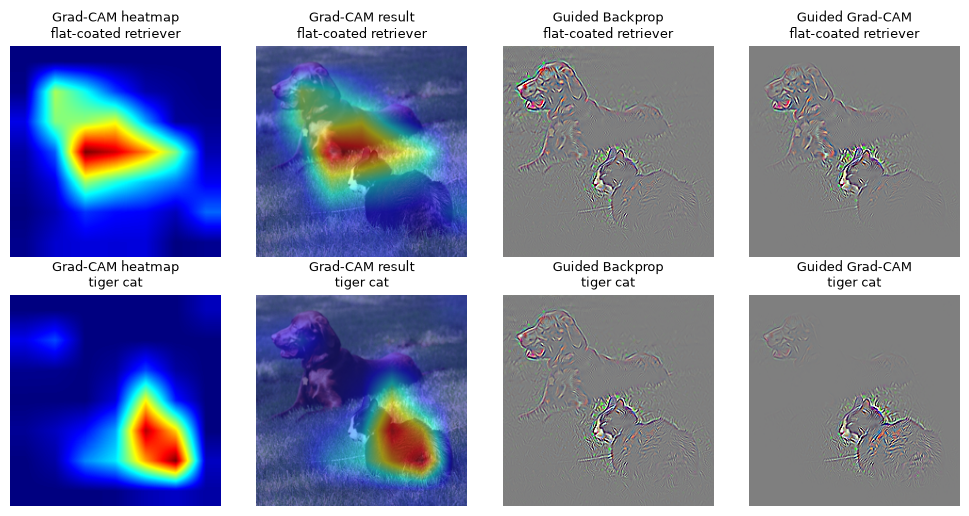

['bull_mastiff_Grad-CAM_heatmap.jpg', 'bull_mastiff_Grad-CAM_result.jpg', 'bull_mastiff_Guided_Backprop.jpg', 'bull_mastiff_Guided_Grad-CAM.jpg']


In [29]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5.2))
for row, class_idx in enumerate([DOG_CLASS, CAT_CLASS]):
    results = guided_grad_cam(class_idx)
    for col, (name, picture) in enumerate(results.items()):
        Image.fromarray(picture).save(saved_loc / f"{CATEGORIES[class_idx].replace(' ', '_')}_{name.replace(' ', '_')}.jpg")
        axes[row, col].imshow(picture)
        axes[row, col].set_title(f"{name}\n{CATEGORIES[class_idx]}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

fwd_handle.remove()
bwd_handle.remove()
print(sorted(p.name for p in saved_loc.iterdir())[:4])

Q. 그림의 Guided Backprop 두 장(위와 아래)을 비교해 보세요. 어떤 차이가 있나요? 무엇을 말해 주나요?

<details><summary>답</summary>

두 장 모두 개와 고양이의 윤곽이 함께 보입니다. 고른 클래스 쪽이 더 진할 뿐, 다른 물체도 사라지지 않습니다. Guided Backprop은 세밀하지만 클래스를 구분하는 힘이 약하다는 뜻입니다. 위치를 구분하는 일은 Grad-CAM이 맡으므로, 곱한 Guided Grad-CAM에는 해당 클래스 영역의 세부가 주로 남습니다.

</details>

### 실습 2. autograd로 Grad-CAM 함수 만들기

ResNet18(`cam_net`)과 `both_tensor`, 클래스 번호를 받아 ReLU까지 적용한 7x7 Grad-CAM을 돌려주는 함수 `simple_grad_cam`을 작성하세요. 훅은 순전파 특징을 잡는 데만 쓰고, 기울기는 `torch.autograd.grad`로 구합니다. 2.2절의 결론대로, 결과가 `F.relu(CAM) / Z`와 같은지 고양이 클래스로 확인하세요.

In [30]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def simple_grad_cam(net: nn.Module, target_layer: nn.Module, x: torch.Tensor, class_idx: int) -> torch.Tensor:
    """autograd.grad로 Grad-CAM을 계산합니다."""
    holder = {}
    handle = target_layer.register_forward_hook(lambda module, inputs, output: holder.update(a=output))
    logit = net(x)
    handle.remove()
    grads = torch.autograd.grad(logit[0, class_idx], holder["a"])[0]
    alpha = grads.mean(dim=(2, 3), keepdim=True)
    return F.relu((alpha * holder["a"]).sum(dim=1))[0].detach()

my_map = simple_grad_cam(cam_net, cam_net.layer4, both_tensor, CAT_CLASS)
with torch.no_grad():
    holder = {}
    handle = cam_net.layer4.register_forward_hook(lambda module, inputs, output: holder.update(a=output))
    cam_net(both_tensor)
    handle.remove()
expected = F.relu((cam_net.fc.weight[CAT_CLASS][:, None, None] * holder["a"][0]).sum(dim=0)) / 49
assert my_map.shape == (7, 7)
assert torch.allclose(my_map, expected, atol=1e-4)
print(my_map.max().item())
```
</details>

---
# 3교시. LayerCAM: 층마다 보는 것이 다르다

## 3.1 왜 층을 나누어 보는가

CNN의 앞쪽 층은 윤곽과 무늬처럼 세밀한 것을, 뒤쪽 층은 물체 전체처럼 뭉툭한 것을 봅니다. Grad-CAM을 앞쪽 층에 그대로 쓰면 잘 동작하지 않습니다. 채널 전체에 **하나의 가중치** $\alpha_k$를 쓰기 때문입니다. 앞쪽 층에서는 같은 채널 안에서도 위치에 따라 기울기가 크게 달라지는데, 평균을 내면 그 차이가 사라집니다.

LayerCAM은 가중치를 **위치별로** 둡니다. ([논문](http://mmcheng.net/mftp/Papers/21TIP_LayerCAM.pdf))

$$\alpha_{ij}^{kc} = \text{ReLU}(g_{ij}^{kc}), \qquad L^c = \text{ReLU}\left(\sum_k \alpha_{ij}^{kc} \cdot A_{ij}^k\right)$$

여기서 $g_{ij}^{kc} = \partial y^c / \partial A_{ij}^k$입니다. 평균 대신 위치별 양수 기울기를 곱합니다. 이렇게 하면 어느 층에서든 쓸 수 있고, 얕은 층의 세밀한 지도와 깊은 층의 안정적인 지도를 합쳐 볼 수 있습니다. 합친 결과가 어떤지는 3.4절에서 실제로 확인합니다.

그림 출처: [층별 특징 맵과 채널 기울기의 분산을 보여 주는 그림(앞 단계일수록 기울기의 변동이 크고 특징이 세밀함)](https://d3i71xaburhd42.cloudfront.net/bfd6684c309dc8d560522017d44da0d6d4ee0359/4-Figure4-1.png), [LayerCAM 구조와 수식 요약](http://iislab.skku.edu/iish/files/attach/images/1210/974/053/99b983892094b5c6d2fc3736e15da7d1.png)

여기서는 [TorchCAM](https://github.com/frgfm/torch-cam) 라이브러리를 씁니다. 맨 앞의 설치 셀에서 `torchcam`을 이미 설치했습니다. GitHub의 최신 소스로 설치하려면 `pip install -e git+https://github.com/frgfm/torch-cam.git#egg=torchcam`을 씁니다.

## 3.2 기본 사용법: 분류기의 판단 그려 보기

사진은 [Border collie sitting on the grass](https://commons.wikimedia.org/wiki/File:Border_collie_sitting_on_the_grass.jpg)(Joselodos, CC0)입니다.

In [31]:
# 이미지를 내려받습니다. 자신의 데이터로 해 보려면 경로만 바꾸면 됩니다.
# 사진: Joselodos, CC0, 위키미디어 공용 (3.2절 위의 안내 참고)
img_path = fetch("https://upload.wikimedia.org/wikipedia/commons/thumb/4/40/Border_collie_sitting_on_the_grass.jpg/960px-Border_collie_sitting_on_the_grass.jpg", "border-collie.jpg")

# 모델을 준비합니다
model = models.resnet18(weights="DEFAULT").eval()

In [32]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

TorchCAM은 추출기를 만들 때 모델에 훅을 겁니다. 대상 층을 지정하지 않으면 마지막 합성곱층을 자동으로 찾습니다. `SmoothGradCAMpp`는 Grad-CAM++(기울기의 단순 평균 대신, 위치별로 가중한 평균으로 채널 중요도를 구하는 변형)에 입력 노이즈를 조금씩 더해 기울기를 여러 번 구해 평균하는 방식을 합친 것입니다. 사용하는 순서는 다음과 같습니다.

1. 추출기를 만듭니다 (`SmoothGradCAMpp(model)`).
2. 모델을 실행합니다. 기울기가 필요하므로 `no_grad`를 쓰면 안 됩니다.
3. 추출기에 클래스 번호와 모델 출력을 넘깁니다.

In [33]:
cam_extractor = SmoothGradCAMpp(model)
# 입력을 준비합니다
img = decode_image(str(img_path))
# 이 모델에 맞게 전처리합니다
input_tensor = tv_normalize(tv_resize(img, (224, 224)) / 255.0, IMAGENET_MEAN, IMAGENET_STD)

# 전처리한 데이터를 모델에 넣습니다
out = model(input_tensor.unsqueeze(0))
# 클래스 번호와 모델 출력을 넘겨 CAM을 얻습니다
idx = out.squeeze(0).argmax().item()
print("id:", idx, CATEGORIES[idx])
cams = cam_extractor(idx, out)

id: 232 Border collie


In [34]:
# 대상 층마다 CAM이 하나씩 나옵니다. 지금은 층이 하나입니다.
for cam in cams:
    print(cam.shape)

torch.Size([1, 7, 7])


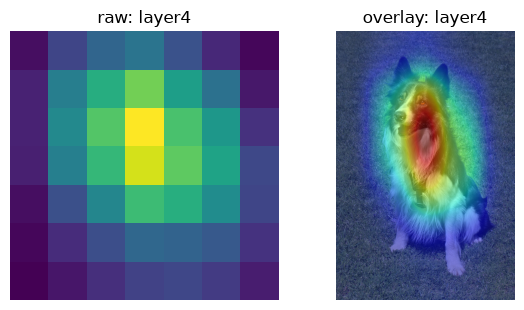

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
for name, cam in zip(cam_extractor.target_names, cams):
    # 있는 그대로의 CAM
    axes[0].imshow(cam.squeeze(0).numpy())
    axes[0].axis("off")
    axes[0].set_title(f"raw: {name}")
    # 이미지에 겹친 모습
    result = overlay_mask(to_pil_image(img), to_pil_image(cam.squeeze(0), mode="F"), alpha=0.5)
    axes[1].imshow(result)
    axes[1].axis("off")
    axes[1].set_title(f"overlay: {name}")
plt.tight_layout()
plt.show()

In [36]:
# 다 쓰면 모델에 걸린 훅을 뗍니다. 그대로 두면 이후의 추출기와 겹쳐서 동작합니다.
cam_extractor.remove_hooks()

## 3.3 위치 단서 뽑기

히트맵을 임계값으로 잘라 내면 물체가 있는 대략의 영역을 얻을 수 있습니다. 위치 라벨 없이 분류 라벨만으로 위치를 찾는 **약지도 위치 찾기**의 기본 아이디어입니다. CAM 논문의 제목도 "Learning Deep Features for Discriminative Localization"입니다.

In [37]:
# 이번에는 LayerCAM을 씁니다
cam_extractor = LayerCAM(model)

out = model(input_tensor.unsqueeze(0))
print(F.softmax(out, dim=1).max())

tensor(0.6719, grad_fn=<MaxBackward1>)


In [38]:
cams = cam_extractor(out.squeeze(0).argmax().item(), out)

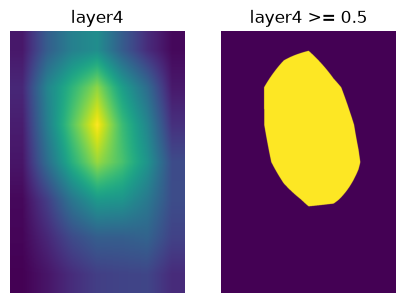

In [39]:
# 입력 사진 크기로 키운다
resized_cams = [tv_resize(to_pil_image(cam.squeeze(0)), img.shape[-2:]) for cam in cams]
segmaps = [to_pil_image((tv_resize(cam, img.shape[-2:]).squeeze(0) >= 0.5).to(dtype=torch.float32)) for cam in cams]

# 그린다
for name, cam, seg in zip(cam_extractor.target_names, resized_cams, segmaps):
    _, axes = plt.subplots(1, 2, figsize=(5, 3.4))
    axes[0].imshow(cam)
    axes[0].axis("off")
    axes[0].set_title(name)
    axes[1].imshow(seg)
    axes[1].axis("off")
    axes[1].set_title(f"{name} >= 0.5")
    plt.show()

In [40]:
cam_extractor.remove_hooks()

## 3.4 여러 층의 CAM 합치기

층이 많은 EfficientNet-B0로 네 층을 함께 봅니다. EfficientNet 자체는 5강을 참고하세요. 층의 이름을 알아야 하므로 `named_modules()`로 찾습니다. 전체 목록은 수백 줄이어서, 여기서는 깊이가 얕은 이름만 출력합니다.

In [41]:
effnet = models.efficientnet_b0(weights="DEFAULT").eval()

for name, module in effnet.named_modules():
    # 모든 층의 이름을 보려면 조건을 빼면 됩니다
    if name.count(".") <= 1 and name.startswith("features"):
        print(name, end="  ")

features  features.0  features.1  features.2  features.3  features.4  features.5  features.6  features.7  features.8  

In [42]:
# 여러 층의 CAM을 동시에 뽑는다
cam_extractor = LayerCAM(effnet, ["features.8", "features.5", "features.3", "features.1"])

out = effnet(input_tensor.unsqueeze(0))
cams = cam_extractor(out.squeeze(0).argmax().item(), out)

In [43]:
# 이번에는 CAM이 여러 개입니다
for cam in cams:
    print(cam.shape)

torch.Size([1, 7, 7])
torch.Size([1, 14, 14])
torch.Size([1, 28, 28])
torch.Size([1, 112, 112])


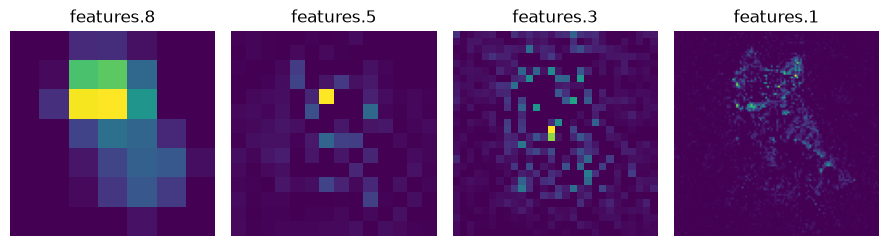

In [44]:
_, axes = plt.subplots(1, len(cam_extractor.target_names), figsize=(9, 2.4))
for idx, name, cam in zip(range(len(cam_extractor.target_names)), cam_extractor.target_names, cams):
    axes[idx].imshow(cam.squeeze(0).numpy())
    axes[idx].axis("off")
    axes[idx].set_title(name)
plt.tight_layout()
plt.show()

뒤쪽 층(`features.8`)은 7x7로 물체 전체를 뭉툭하게 잡고, 앞쪽 층(`features.1`)은 112x112로 세밀한 윤곽에 반응합니다. "층마다 보는 바가 다르다"는 말이 그림으로 보입니다. 이제 이 지도들을 합칩니다.

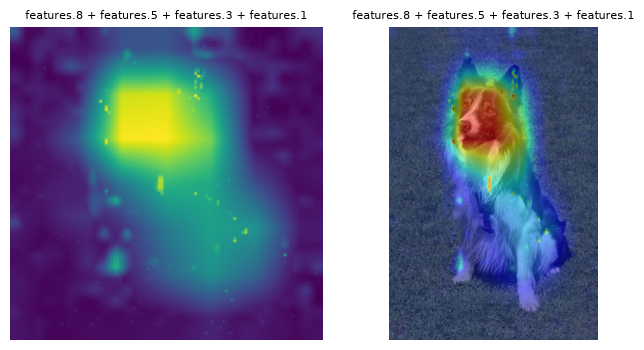

In [45]:
fused_cam = cam_extractor.fuse_cams(cams)
title = " + ".join(cam_extractor.target_names)
_, axes = plt.subplots(1, 2, figsize=(7, 3.6))
# 합친 지도 그대로
axes[0].imshow(fused_cam.squeeze(0).numpy())
axes[0].axis("off")
axes[0].set_title(title, fontsize=8)
# 이미지에 겹친 모습
result = overlay_mask(to_pil_image(img), to_pil_image(fused_cam, mode="F"), alpha=0.5)
axes[1].imshow(result)
axes[1].axis("off")
axes[1].set_title(title, fontsize=8)
plt.tight_layout()
plt.show()

합친 지도를 보면 기대만큼 세밀하지 않습니다. `features.8`의 뭉툭한 덩어리가 대부분을 차지하고, `features.1`의 윤곽은 점 몇 개 정도만 남았습니다. TorchCAM의 `fuse_cams`는 각 지도를 $\tanh(2 \cdot \text{CAM})$으로 키운 뒤 가장 큰 크기로 보간해 **위치별 최댓값**을 취합니다. 그래서 넓게 켜진 깊은 층이 약하고 드문드문한 앞쪽 층의 신호를 덮기 쉽습니다. 층을 합친다고 언제나 세밀해지는 것은 아니니, 결과를 직접 보고 판단하세요. 이 그림은 사진 한 장과 고른 네 층의 결과입니다.

In [46]:
cam_extractor.remove_hooks()

### 실습 3. LayerCAM 직접 구현하기

ResNet18의 `model.layer2`에 대해 수식 그대로 LayerCAM을 계산해 `my_layer_cam`에 담으세요. 순서는 다음과 같습니다.

1. 순전파 훅으로 `A`를 잡고, 예측 1위 클래스의 점수로 `torch.autograd.grad`를 해 `g`를 구합니다.
2. `F.relu((F.relu(g) * A).sum(dim=1))`을 계산하고, 최솟값 0과 최댓값 1로 맞춥니다.
3. TorchCAM의 `LayerCAM(model, ["layer2"])` 결과와 assert로 비교합니다.

In [47]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
holder = {}
handle = model.layer2.register_forward_hook(lambda module, inputs, output: holder.update(a=output))
out = model(input_tensor.unsqueeze(0))
handle.remove()
top_class = out.argmax().item()
g = torch.autograd.grad(out[0, top_class], holder["a"])[0]
my_layer_cam = F.relu((F.relu(g) * holder["a"]).sum(dim=1))[0].detach()
my_layer_cam = (my_layer_cam - my_layer_cam.min()) / (my_layer_cam.max() - my_layer_cam.min())

extractor = LayerCAM(model, ["layer2"])
out = model(input_tensor.unsqueeze(0))
library_cam = extractor(top_class, out)[0].squeeze(0)
extractor.remove_hooks()

assert my_layer_cam.shape == library_cam.shape
assert torch.allclose(my_layer_cam, library_cam, atol=1e-5)
print(my_layer_cam.shape)
```
</details>

---
# 4교시. TorchScript: 파이썬 밖으로 모델 내보내기

> 참고: [PyTorch 한국어 튜토리얼 - TorchScript 소개](https://tutorials.pytorch.kr/beginner/Intro_to_TorchScript_tutorial.html), [TorchScript의 Script Mode 변환 그림](https://i0.wp.com/blog.dramancompany.com/wp-content/uploads/2022/11/%E1%84%80%E1%85%B3%E1%84%85%E1%85%B5%E1%86%B7-1.-TorchScript%E1%84%8B%E1%85%B4-Script-Mode-%E1%84%87%E1%85%A7%E1%86%AB%E1%84%92%E1%85%AA%E1%86%AB.png?resize=2000%2C871&ssl=1)

## 4.1 Eager 모드와 Script 모드

- **Eager 모드**(평소의 파이썬 실행): 프로토타입 작성, 학습, 실험을 위해 파이썬의 유연함을 최대한 활용합니다.
- **Script 모드**: 배포를 위해 모델을 **파이썬에 의존하지 않는 중간 표현(IR)** 으로 바꾼 것입니다.

실제 서비스에 쓰려면 두 가지가 더 필요합니다.

1. 다양한 환경에서 동작해야 합니다 (파이썬이 없는 서버, 모바일 등).
2. 가볍고 빨라야 합니다 (최적화, 병렬 실행).

파이썬 인터프리터 없이 실행되므로 병렬 연산과 그래프 최적화의 여지가 생깁니다. Eager에서 Script로 가는 길은 두 가지입니다.

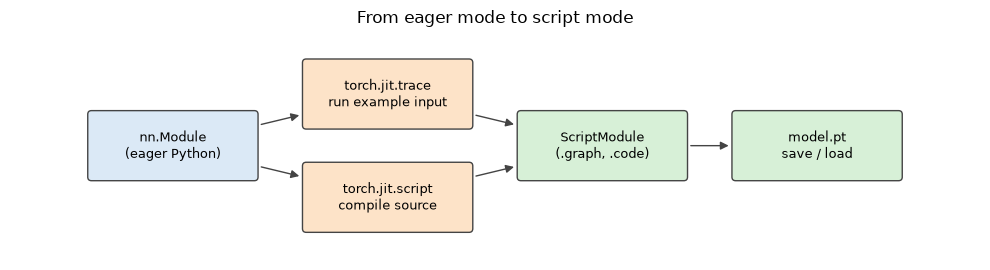

In [48]:
draw_diagram(
    {
        "eager": (0, 0.8, "nn.Module\n(eager Python)", "#dbe9f6"),
        "trace": (2.9, 1.5, "torch.jit.trace\nrun example input", "#fde3c8"),
        "script": (2.9, 0.1, "torch.jit.script\ncompile source", "#fde3c8"),
        "ir": (5.8, 0.8, "ScriptModule\n(.graph, .code)", "#d7f0d7"),
        "file": (8.7, 0.8, "model.pt\nsave / load", "#d7f0d7"),
    },
    [("eager", "trace"), ("eager", "script"), ("trace", "ir"), ("script", "ir"), ("ir", "file")],
    figsize=(10, 2.8), title="From eager mode to script mode", box_size=(2.2, 0.85),
)

## 4.2 먼저 알아 둘 현재 상태

**`torch.jit`은 이제 지원이 끝나 가는 기능입니다.** 지금 쓰는 PyTorch에서 호출하면 어떤 경고가 나오는지 직접 봅시다.

In [49]:
print("PyTorch:", torch.__version__)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    torch.jit.script(nn.Linear(2, 2))
for item in caught:
    print(item.category.__name__, ":", item.message)

# 경고를 확인했으니, 이후 셀에서는 반복되는 같은 경고를 숨깁니다
warnings.filterwarnings("ignore", message=r".*torch\.jit.*deprecated.*", category=FutureWarning)
warnings.filterwarnings("ignore", message=r".*deprecated.*torch\.compile.*", category=FutureWarning)
warnings.filterwarnings("ignore", message=r".*torch\.jit\.save.*")
warnings.filterwarnings("ignore", message=r".*torch\.jit\.load.*")

PyTorch: 2.15.0


새로 시작하는 작업이라면 PyTorch가 권하는 `torch.compile`(파이썬 안에서 빠르게), `torch.export`(그래프로 내보내기), 그리고 5교시의 ONNX를 쓰세요. 4.7절에서 이들을 짧게 봅니다.

그래도 TorchScript를 배우는 이유가 있습니다.

- 이미 배포된 모델과 코드에 `.pt` 스크립트 모델이 많이 남아 있습니다.
- **추적(tracing)** 이라는 개념은 ONNX 등 다른 도구에도 이어집니다. 제어 흐름을 잃는 함정이 어떻게 생기는지 이해하는 것이 중요합니다.

## 4.3 방법 1: `torch.jit.trace`

Tracing은 입력 예시를 모델에 흘려 보내면서 **실제로 실행된 연산을 기록**합니다. 조건문을 많이 쓰지 않는 모델에 적합합니다. 먼저 간단한 모델을 정의합니다. 조건문이 있는 `MyDecisionGate`를 포함합니다.

여기서 쓰는 라이브러리는 파이썬 패키지 `torch` 하나뿐입니다. TorchScript가 PyTorch에 들어 있기 때문입니다.

In [50]:
class MyDecisionGate(nn.Module):
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.sum() > 0:
            return x
        else:
            return -x


class MyCell(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.dg = MyDecisionGate()
        self.linear = nn.Linear(4, 4)

    def forward(self, x: torch.Tensor, h: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        new_h = torch.tanh(self.dg(self.linear(x)) + h)
        return new_h, new_h


set_seed()
my_cell = MyCell()
x, h = torch.rand(3, 4), torch.rand(3, 4)
print(my_cell)
print(my_cell(x, h))

MyCell(
  (dg): MyDecisionGate()
  (linear): Linear(in_features=4, out_features=4, bias=True)
)
(tensor([[ 0.5975,  0.6448, -0.1276,  0.8186],
        [ 0.4454,  0.8370,  0.0320,  0.9252],
        [ 0.6403,  0.7726,  0.2276,  0.7225]], grad_fn=<TanhBackward0>), tensor([[ 0.5975,  0.6448, -0.1276,  0.8186],
        [ 0.4454,  0.8370,  0.0320,  0.9252],
        [ 0.6403,  0.7726,  0.2276,  0.7225]], grad_fn=<TanhBackward0>))


TorchScript는 PyTorch의 유연하고 동적인 특성을 고려해 모델 정의를 잡아내는 **추적(tracing)** 을 제공합니다. 먼저 조건문이 없는 버전으로 `Module`을 추적해 봅시다.

In [51]:
class MyCell(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.linear = nn.Linear(4, 4)

    def forward(self, x: torch.Tensor, h: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        new_h = torch.tanh(self.linear(x) + h)
        return new_h, new_h


my_cell = MyCell()
x, h = torch.rand(3, 4), torch.rand(3, 4)
traced_cell = torch.jit.trace(my_cell, (x, h))   # 모델과 입력 예시를 전달
print(traced_cell)
traced_cell(x, h)

MyCell(
  original_name=MyCell
  (linear): Linear(original_name=Linear)
)


(tensor([[ 0.7439,  0.5655,  0.5910,  0.0339],
         [ 0.3012,  0.8487, -0.2861,  0.0344],
         [ 0.4671,  0.8422, -0.0169,  0.6575]], grad_fn=<TanhBackward0>),
 tensor([[ 0.7439,  0.5655,  0.5910,  0.0339],
         [ 0.3012,  0.8487, -0.2861,  0.0344],
         [ 0.4671,  0.8422, -0.0169,  0.6575]], grad_fn=<TanhBackward0>))

`torch.jit.trace`에 모듈과 **네트워크가 볼 만한 입력 예시**를 넘겼습니다. 이때 PyTorch는 모듈을 호출하면서 일어난 연산을 기록하고 `torch.jit.ScriptModule`의 인스턴스(`TracedModule`)를 만듭니다.

### `.graph`와 `.code`

기록된 내용은 두 가지로 볼 수 있습니다.

1. `.graph`: 저수준 그래프 표현
2. `.code`: 그래프를 파이썬 문법으로 풀어 쓴 해석

In [52]:
print(traced_cell.graph)

graph(%self.1 : __torch__.MyCell,
      %x : Float(3, 4, strides=[4, 1], requires_grad=0, device=cpu),
      %h : Float(3, 4, strides=[4, 1], requires_grad=0, device=cpu)):
  %linear : __torch__.torch.nn.modules.linear.___torch_mangle_0.Linear = prim::GetAttr[name="linear"](%self.1)
  %20 : Tensor = prim::CallMethod[name="forward"](%linear, %x)
  %11 : int = prim::Constant[value=1]() # <cell>:7:0
  %12 : Float(3, 4, strides=[4, 1], requires_grad=1, device=cpu) = aten::add(%20, %h, %11) # <cell>:7:0
  %13 : Float(3, 4, strides=[4, 1], requires_grad=1, device=cpu) = aten::tanh(%12) # <cell>:7:0
  %14 : (Float(3, 4, strides=[4, 1], requires_grad=1, device=cpu), Float(3, 4, strides=[4, 1], requires_grad=1, device=cpu)) = prim::TupleConstruct(%13, %13)
  return (%14)



In [53]:
print(traced_cell.code)

def forward(self,
    x: Tensor,
    h: Tensor) -> Tuple[Tensor, Tensor]:
  linear = self.linear
  _0 = torch.tanh(torch.add((linear).forward(x, ), h))
  return (_0, _0)



**왜** 이런 일을 할까요? 이유는 세 가지입니다.

1. TorchScript 코드는 자체 인터프리터에서 실행됩니다. 이 인터프리터는 파이썬의 GIL(Global Interpreter Lock)을 잡지 않으므로, 같은 모델로 동시에 많은 요청을 처리할 수 있습니다.
2. 모델 전체를 저장해서 파이썬이 아닌 언어로 작성한 서버 같은 다른 환경에서도 실행할 수 있습니다.
3. 컴파일러가 최적화할 수 있는 표현을 제공합니다.

`traced_cell`을 호출하면 파이썬 모듈과 같은 결과가 나옵니다.

In [54]:
print(my_cell(x, h))
print(traced_cell(x, h))
assert torch.equal(my_cell(x, h)[0], traced_cell(x, h)[0])

(tensor([[ 0.7439,  0.5655,  0.5910,  0.0339],
        [ 0.3012,  0.8487, -0.2861,  0.0344],
        [ 0.4671,  0.8422, -0.0169,  0.6575]], grad_fn=<TanhBackward0>), tensor([[ 0.7439,  0.5655,  0.5910,  0.0339],
        [ 0.3012,  0.8487, -0.2861,  0.0344],
        [ 0.4671,  0.8422, -0.0169,  0.6575]], grad_fn=<TanhBackward0>))
(tensor([[ 0.7439,  0.5655,  0.5910,  0.0339],
        [ 0.3012,  0.8487, -0.2861,  0.0344],
        [ 0.4671,  0.8422, -0.0169,  0.6575]], grad_fn=<TanhBackward0>), tensor([[ 0.7439,  0.5655,  0.5910,  0.0339],
        [ 0.3012,  0.8487, -0.2861,  0.0344],
        [ 0.4671,  0.8422, -0.0169,  0.6575]], grad_fn=<TanhBackward0>))


Tracing은 Eager 모델의 코드를 재사용하는 효과적인 방법입니다.

***중요!*** 그러나 이 방법에서는 제어 흐름(control flow)과 자료 구조, 파이썬 구문이 보존되지 않습니다. 따라서 **항상 변환 결과를 검사**해 모델이 올바르게 동작하는지 확인해야 합니다. 아래 예시를 보세요.

In [55]:
class MyDecisionGate(torch.nn.Module):
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.sum() > 0:
            return x
        else:
            return -x


class MyCell(torch.nn.Module):
    def __init__(self, dg: nn.Module) -> None:
        super().__init__()
        self.dg = dg
        self.linear = torch.nn.Linear(4, 4)

    def forward(self, x: torch.Tensor, h: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        new_h = torch.tanh(self.dg(self.linear(x)) + h)
        return new_h, new_h


my_cell = MyCell(MyDecisionGate())
with warnings.catch_warnings():
    warnings.simplefilter("ignore", torch.jit.TracerWarning)     # 다음 설명에서 일부러 이 문제를 다룬다
    traced_cell = torch.jit.trace(my_cell, (x, h))

print(traced_cell.dg.code)
print(traced_cell.code)

def forward(self,
    argument_1: Tensor) -> NoneType:
  return None

def forward(self,
    x: Tensor,
    h: Tensor) -> Tuple[Tensor, Tensor]:
  dg = self.dg
  linear = self.linear
  _0 = (linear).forward(x, )
  _1 = (dg).forward(_0, )
  _2 = torch.tanh(torch.add(_0, h))
  return (_2, _2)



`MyDecisionGate`의 내용물이 **사라졌습니다.** 위 출력의 `return None`이 그것입니다. **추적할 때 실제로 지나간 경로의 연산만 기록**된 결과입니다. 이번 입력에서는 `return x` 쪽을 지나갔고, 이 경로에는 연산이 하나도 없어서 기록할 것이 없습니다. 그래서 `MyCell`의 코드에서도 게이트의 결과(`_1`)는 쓰이지 않고, 선형층의 출력(`_0`)이 곧바로 `torch.add`로 갑니다. 추적 입력이 다른 쪽 분기를 지나갔다면 `torch.neg`만 남았을 것입니다. 어느 쪽이든 `if`는 남지 않습니다.

단순히 코드가 달라 보이는 정도가 아닙니다. 조건이 달라지는 입력을 넣으면 **답이 틀립니다.** 오류도 나지 않습니다. 직접 확인합니다.

In [56]:
gate = MyDecisionGate()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", torch.jit.TracerWarning)
    traced_gate = torch.jit.trace(gate, torch.ones(2))      # 합이 양수인 입력으로 추적

negative = -torch.ones(2)
print("입력           :", negative)
print("파이썬 모델    :", gate(negative))
print("추적한 모델    :", traced_gate(negative), "<- 틀린 답, 오류 없음")
assert not torch.equal(gate(negative), traced_gate(negative))

입력           : tensor([-1., -1.])
파이썬 모델    : tensor([1., 1.])
추적한 모델    : tensor([-1., -1.]) <- 틀린 답, 오류 없음


이런 한계를 해결하기 위해 Annotation 방식, 즉 스크립트 컴파일이 고안되었습니다.

## 4.4 방법 2: `torch.jit.script`

제어 흐름이 있는 모듈은 어떻게 충실하게 나타낼까요? TorchScript는 파이썬 소스 코드를 직접 분석해 변환하는 **스크립트 컴파일러**를 제공합니다.

In [57]:
scripted_gate = torch.jit.script(MyDecisionGate())

my_cell = MyCell(scripted_gate)
scripted_cell = torch.jit.script(my_cell)

print(scripted_gate.code)
print(scripted_cell.code)
assert torch.equal(scripted_gate(negative), gate(negative))
print("스크립트한 게이트:", scripted_gate(negative), "<- 올바른 답")

def forward(self,
    x: Tensor) -> Tensor:
  if bool(torch.gt(torch.sum(x), 0)):
    _0 = x
  else:
    _0 = torch.neg(x)
  return _0

def forward(self,
    x: Tensor,
    h: Tensor) -> Tuple[Tensor, Tensor]:
  dg = self.dg
  linear = self.linear
  _0 = torch.add((dg).forward((linear).forward(x, ), ), h)
  new_h = torch.tanh(_0)
  return (new_h, new_h)

스크립트한 게이트: tensor([1., 1.]) <- 올바른 답


이제 프로그램의 동작을 충실하게 잡아냈습니다. 스크립트한 모델을 실행해 봅시다.

In [58]:
# 새로운 입력
x, h = torch.rand(3, 4), torch.rand(3, 4)
scripted_cell(x, h)

(tensor([[ 0.5658,  0.1631,  0.7141,  0.5958],
         [ 0.4246, -0.1411,  0.8208,  0.7985],
         [ 0.1481,  0.6183,  0.6379,  0.8264]], grad_fn=<TanhBackward0>),
 tensor([[ 0.5658,  0.1631,  0.7141,  0.5958],
         [ 0.4246, -0.1411,  0.8208,  0.7985],
         [ 0.1481,  0.6183,  0.6379,  0.8264]], grad_fn=<TanhBackward0>))

### 스크립팅과 추적 함께 쓰기

어떤 상황에서는 스크립팅보다 추적이 낫습니다. 예를 들어 파이썬 상수 값에 따라 구조가 정해지는 부분이 많아서, 그 결정을 TorchScript에 드러내고 싶지 않은 경우입니다. 이때는 둘을 조합할 수 있습니다. `torch.jit.script`는 추적된 모듈의 코드를 인라인하고, 추적은 스크립트된 모듈의 코드를 인라인합니다.

첫 번째 경우의 예입니다. 스크립트하는 모듈 안에 추적한 모듈이 있습니다.

In [59]:
class MyRNNLoop(torch.nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.cell = torch.jit.trace(MyCell(scripted_gate), (x, h))

    def forward(self, xs: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h, y = torch.zeros(3, 4), torch.zeros(3, 4)
        for i in range(xs.size(0)):
            y, h = self.cell(xs[i], h)
        return y, h


rnn_loop = torch.jit.script(MyRNNLoop())
print(rnn_loop.code)

def forward(self,
    xs: Tensor) -> Tuple[Tensor, Tensor]:
  h = torch.zeros([3, 4])
  y = torch.zeros([3, 4])
  y0 = y
  h0 = h
  for i in range(torch.size(xs, 0)):
    cell = self.cell
    _0 = (cell).forward(torch.select(xs, 0, i), h0, )
    y1, h1, = _0
    y0, h0 = y1, h1
  return (y0, h0)



두 번째 경우의 예입니다. 추적하는 모듈 안에 스크립트한 모듈이 있습니다.

In [60]:
class WrapRNN(torch.nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.loop = torch.jit.script(MyRNNLoop())

    def forward(self, xs: torch.Tensor) -> torch.Tensor:
        y, h = self.loop(xs)
        return torch.relu(y)


traced = torch.jit.trace(WrapRNN(), (torch.rand(10, 3, 4)))
print(traced.code)

def forward(self,
    xs: Tensor) -> Tensor:
  loop = self.loop
  _0, y, = (loop).forward(xs, )
  return torch.relu(y)



이처럼 스크립팅과 추적은 상황에 따라 따로 쓰거나 함께 쓸 수 있습니다.

## 4.5 모델 저장과 불러오기

TorchScript 모듈은 아카이브 형식으로 저장하고 불러올 수 있습니다. 이 형식에는 코드, 파라미터, 속성, 디버그 정보가 들어 있습니다. 즉, 완전히 별개의 프로세스에서 불러올 수 있는 **독립적인 모델 표현**입니다. 위의 RNN 모듈을 저장했다가 불러옵니다.

In [61]:
traced.save("wrapped_rnn.pt")

loaded = torch.jit.load("wrapped_rnn.pt")

print(loaded)
print(loaded.code)

check_input = torch.rand(10, 3, 4)
assert torch.equal(loaded(check_input), traced(check_input))

RecursiveScriptModule(
  original_name=WrapRNN
  (loop): RecursiveScriptModule(
    original_name=MyRNNLoop
    (cell): RecursiveScriptModule(
      original_name=MyCell
      (dg): RecursiveScriptModule(original_name=MyDecisionGate)
      (linear): RecursiveScriptModule(original_name=Linear)
    )
  )
)
def forward(self,
    xs: Tensor) -> Tensor:
  loop = self.loop
  _0, y, = (loop).forward(xs, )
  return torch.relu(y)



사전학습 ResNet18을 통째로 스크립트로 바꾸고, 정말 같은 모델인지 확인합니다.

`eval()`을 빼먹으면 BatchNorm이 학습 때 모은 통계 대신 **입력 배치의 통계**로 정규화하므로(배치 크기 1이면 특히 불안정합니다) 추론과 다른 답이 나오고, 저장된 running 통계도 덮어써집니다. 그래서 `eval()`을 먼저 호출합니다. 상위 5개가 같은지만 보지 않고 값 전체를 비교합니다.

In [62]:
r18 = models.resnet18(weights="DEFAULT").eval()      # 사전학습된 모델의 인스턴스
r18_scripted = torch.jit.script(r18)                 # 여기가 TorchScript로 내보내는 부분입니다
dummy_input = torch.rand(1, 3, 224, 224)             # 빠르게 시험해 봅니다

In [63]:
with torch.no_grad():
    unscripted_output = r18(dummy_input)             # 스크립트하지 않은 모델의 예측
    scripted_output = r18_scripted(dummy_input)      # 스크립트한 모델의 예측

unscripted_top5 = F.softmax(unscripted_output, dim=1).topk(5).indices
scripted_top5 = F.softmax(scripted_output, dim=1).topk(5).indices

print("Python model top 5 results:\n  {}".format(unscripted_top5))
print("TorchScript model top 5 results:\n  {}".format(scripted_top5))
print("출력의 최대 차이:", (unscripted_output - scripted_output).abs().max().item())
assert torch.allclose(unscripted_output, scripted_output, atol=1e-4)

Python model top 5 results:
  tensor([[111, 892, 418, 845, 644]])
TorchScript model top 5 results:
  tensor([[111, 892, 418, 845, 644]])
출력의 최대 차이: 0.0


In [64]:
r18_scripted.save("r18_scripted.pt")
print("저장한 파일 크기(MB):", round(Path("r18_scripted.pt").stat().st_size / 1e6, 1))

저장한 파일 크기(MB): 46.9


## 4.6 정말 빨라질까? 제대로 재 보기

단순히 몇 번 돌려 평균을 내면 스크립트가 훨씬 빨라 보이기도 합니다. 저자가 Colab의 T4 GPU에서 그렇게 쟀을 때의 기록입니다.

```
normal cpu eval mode:  120.2 ms
normal gpu eval mode:  2.77 ms
torch.jit.script cpu:  77.3 ms
torch.jit.script GPU:  1.58 ms
```

그런데 이 측정에는 문제가 있습니다. 흔히 저지르는 실수들입니다.

- GPU는 연산을 비동기로 처리합니다. 완료를 기다리지(`synchronize`) 않으면 **연산을 시작한 시간만** 재게 됩니다.
- CPU 비교는 10번, 마지막 GPU는 100번을 평균했고, 앞쪽 호출의 준비 시간이 평균에 그대로 들어갔습니다.
- 먼저 잰 쪽이 준비 시간을 떠안아 불리해질 수 있습니다.
- `torch.jit.script(model, (x))`의 두 번째 인자는 `optimize`로, 입력 예시를 넣는 자리가 아니며 지금은 효과가 없습니다.

아래처럼 앞쪽 호출을 버리고, 번갈아 재고, 중앙값을 씁니다. 결과는 환경과 그때의 부하에 따라 달라지므로 자신의 런타임에서 직접 확인하세요.

In [65]:
def sync_device(target: torch.device) -> None:
    """GPU 연산이 끝날 때까지 기다립니다. 기다리지 않으면 시작 시간만 재게 됩니다."""
    if target.type == "cuda":
        torch.cuda.synchronize()
    elif target.type == "mps":
        torch.mps.synchronize()


def timer(f: nn.Module, x_input: torch.Tensor) -> float:
    """한 번 호출하는 데 걸린 시간(ms)을 잽니다."""
    start = time.perf_counter()
    with torch.no_grad():
        f(x_input)
    sync_device(x_input.device)
    return 1000 * (time.perf_counter() - start)


def compare_speed(python_model: nn.Module, script_model: nn.Module, x_input: torch.Tensor,
                  warmup: int = 5, repeats: int = 30) -> tuple[float, float]:
    """두 모델을 번갈아 실행해 호출 시간의 중앙값(ms)을 돌려줍니다. 앞쪽 호출은 버립니다."""
    for _ in range(warmup):
        timer(python_model, x_input)
        timer(script_model, x_input)
    python_times, script_times = [], []
    for _ in range(repeats):
        python_times.append(timer(python_model, x_input))
        script_times.append(timer(script_model, x_input))
    return float(np.median(python_times)), float(np.median(script_times))


model_ft = torchvision.models.resnet18(weights="DEFAULT").eval()
script_cell = torch.jit.script(model_ft)
x_ft = torch.rand(1, 3, 224, 224)
python_ms, script_ms = compare_speed(model_ft, script_cell, x_ft)
print(f"CPU   파이썬 {python_ms:.2f} ms / torch.jit.script {script_ms:.2f} ms / 비율 {python_ms / script_ms:.2f}")

if device.type != "cpu":
    model_gpu = copy.deepcopy(model_ft).to(device)
    script_gpu = torch.jit.script(model_gpu)
    python_ms, script_ms = compare_speed(model_gpu, script_gpu, x_ft.to(device))
    print(f"{device.type:5s} 파이썬 {python_ms:.2f} ms / torch.jit.script {script_ms:.2f} ms / 비율 {python_ms / script_ms:.2f}")

CPU   파이썬 8.83 ms / torch.jit.script 8.29 ms / 비율 1.07


mps   파이썬 1.80 ms / torch.jit.script 1.63 ms / 비율 1.10


위 출력에서 파이썬 대비 `torch.jit.script`의 속도 비율은 CPU 1.07, MPS 1.10입니다. 저자의 Mac에서 저장한 한 번의 측정이고, 같은 코드를 다른 때 돌렸을 때는 CPU 1.01, MPS 1.04였습니다. 즉, 빨라져도 소폭이고 부하에 따라 흔들리는 수준입니다. ResNet18처럼 계산 대부분이 합성곱 내부에서 일어나는 모델은 파이썬을 거치는 비용이 작기 때문으로 보입니다. 앞의 "훨씬 빠른" 결과는 이 측정에서 재현되지 않았습니다. T4 GPU에서는 재 보지 못했으니 Colab에서 직접 확인해 보세요. TorchScript의 주된 가치는 속도보다 **파이썬 없는 배포**입니다.

## 4.7 지금의 대안: `torch.export`와 `torch.compile`

- `torch.compile(model)`: 파이썬 안에서 그대로 쓰면서 빠르게 하는 도구입니다. 학습에도 씁니다. 그래프로 바꿀 수 없는 부분은 자동으로 파이썬으로 되돌아갑니다.
- `torch.export.export(model, args)`: 모델을 파이썬에 의존하지 않는 그래프(`ExportedProgram`)로 내보냅니다. 배포용입니다. 5교시의 ONNX 변환도 지금은 내부에서 이 경로를 씁니다.

`torch.export`와 `torch.jit.trace`의 가장 큰 차이는, 값에 따라 달라지는 제어 흐름을 만나면 **조용히 틀리는 대신 오류를 낸다**는 점입니다. `torch.compile`은 그런 부분을 파이썬으로 실행해 올바르게 처리합니다.

In [66]:
class SmallModel(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.fc = nn.Linear(4, 2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.relu(self.fc(x))


small_model = SmallModel().eval()
example = torch.rand(3, 4)

exported = torch.export.export(small_model, (example,))
print(exported.graph)
assert torch.allclose(exported.module()(example), small_model(example))

# 저장하고 불러오기
torch.export.save(exported, "small_model.pt2")
reloaded = torch.export.load("small_model.pt2")
assert torch.allclose(reloaded.module()(example), small_model(example))

# 값에 따라 분기하는 게이트는 어떨까?
logging.disable(logging.WARNING)      # 변환기의 긴 내부 로그를 잠시 끈다. 일부러 실패시키는 셀이다
try:
    torch.export.export(MyDecisionGate(), (torch.ones(2),))
    print("변환 성공")
except Exception as error:      # 오류 종류는 버전에 따라 달라질 수 있어 넓게 잡는다
    print("변환 실패:", type(error).__name__)
    print(str(error).splitlines()[0][:120])
finally:
    logging.disable(logging.NOTSET)

# torch.compile은 파이썬 안에서 그대로 쓴다. 값에 따른 분기도 올바르게 처리한다
compiled_gate = torch.compile(MyDecisionGate())
print("torch.compile:", compiled_gate(negative))
assert torch.equal(compiled_gate(negative), gate(negative))

graph():
    %p_fc_weight : [num_users=1] = placeholder[target=p_fc_weight]
    %p_fc_bias : [num_users=1] = placeholder[target=p_fc_bias]
    %x : [num_users=1] = placeholder[target=x]
    %linear : [num_users=1] = call_function[target=torch.ops.aten.linear.default](args = (%x, %p_fc_weight, %p_fc_bias), kwargs = {})
    %relu : [num_users=1] = call_function[target=torch.ops.aten.relu.default](args = (%linear,), kwargs = {})
    return (relu,)
변환 실패: GuardOnDataDependentSymNode
Could not guard on data-dependent expression Eq(u0, 1) (unhinted: Eq(u0, 1)).  (Size-like symbols: none)


torch.compile: tensor([1., 1.])


### 실습 4. trace와 script의 차이 잡아내기

입력의 합이 **10보다 크면 2배**, 아니면 그대로 돌려주는 모듈 `ScaleGate`를 만드세요. 합이 작은 입력 `torch.ones(3)`으로 `torch.jit.trace`하고, `torch.jit.script`도 하세요. 합이 큰 입력 `torch.full((3,), 5.0)`에서 파이썬 모델, 추적, 스크립트의 출력을 비교해, 추적한 모델만 틀린다는 것을 assert로 확인하세요.

In [67]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
class ScaleGate(nn.Module):
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.sum() > 10:
            return x * 2
        return x

scale_gate = ScaleGate()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", torch.jit.TracerWarning)
    traced_scale = torch.jit.trace(scale_gate, torch.ones(3))
scripted_scale = torch.jit.script(scale_gate)

big_input = torch.full((3,), 5.0)
print(scale_gate(big_input), traced_scale(big_input), scripted_scale(big_input))
assert torch.equal(scale_gate(big_input), scripted_scale(big_input))
assert not torch.equal(scale_gate(big_input), traced_scale(big_input))
```
</details>

---
# 5교시. ONNX: 프레임워크 사이의 공통 형식

## 5.1 ONNX와 ONNX Runtime

학습 프레임워크(PyTorch, TensorFlow, scikit-learn 등)와 실행 환경(클라우드, 윈도우 기기, 모바일 등)의 조합은 아주 많습니다. **ONNX**(Open Neural Network Exchange)는 그 사이에 공통 형식을 하나 두어 조합의 수를 줄입니다. 한마디로 "통일!"입니다. ([그림 출처: Microsoft Learn](https://learn.microsoft.com/ko-kr/azure/machine-learning/media/concept-onnx/onnx.png?view=azureml-api-2))

**ONNX Runtime**은 ONNX 모델을 실행하는 엔진입니다. 성능에 초점을 맞추었고 윈도우, 리눅스, 맥과 CPU, GPU 등 여러 플랫폼과 하드웨어에서 효율적으로 추론합니다.

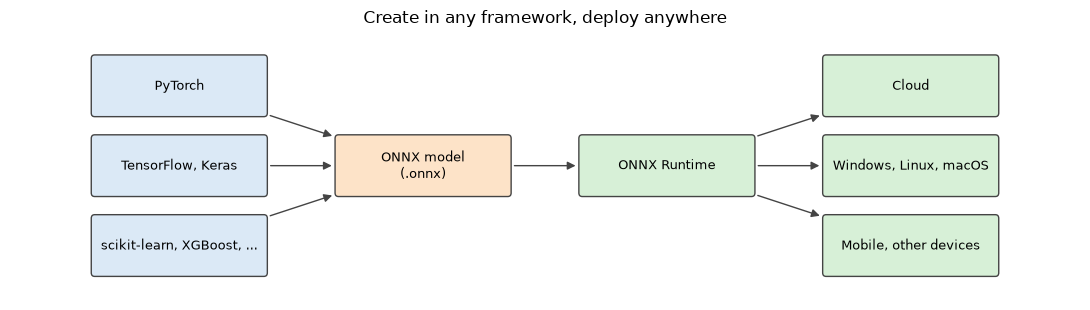

In [68]:
draw_diagram(
    {
        "pt": (0, 2.2, "PyTorch", "#dbe9f6"),
        "tf": (0, 1.1, "TensorFlow, Keras", "#dbe9f6"),
        "sk": (0, 0, "scikit-learn, XGBoost, ...", "#dbe9f6"),
        "onnx": (3.6, 1.1, "ONNX model\n(.onnx)", "#fde3c8"),
        "ort": (7.2, 1.1, "ONNX Runtime", "#d7f0d7"),
        "cloud": (10.8, 2.2, "Cloud", "#d7f0d7"),
        "win": (10.8, 1.1, "Windows, Linux, macOS", "#d7f0d7"),
        "mob": (10.8, 0, "Mobile, other devices", "#d7f0d7"),
    },
    [("pt", "onnx"), ("tf", "onnx"), ("sk", "onnx"), ("onnx", "ort"), ("ort", "cloud"), ("ort", "win"), ("ort", "mob")],
    figsize=(11, 3.2), title="Create in any framework, deploy anywhere", box_size=(2.5, 0.75),
)

## 5.2 예제 모델: 초해상화

예제로 초해상화(super-resolution) 모델을 씁니다. 초해상화는 이미지나 비디오의 해상도를 높이는 방법입니다.

- 논문: "Real-Time Single Image and Video Super-Resolution Using an Efficient Sub-Pixel Convolutional Neural Network" - Shi et al. ([arXiv](https://arxiv.org/abs/1609.05158))
- 모델 코드: [pytorch/examples](https://github.com/pytorch/examples/blob/main/super_resolution/model.py)

효율적인 서브픽셀 합성곱 계층(`PixelShuffle`)으로 해상도를 업스케일 인자만큼 늘립니다. 입력은 이미지의 YCbCr 성분 중 **Y 성분**이고, 출력은 업스케일된 Y 채널입니다.

`PixelShuffle(r)`은 채널 $r^2$개를 공간으로 재배치합니다. 즉, `(N, r², H, W)`가 `(N, 1, rH, rW)`가 됩니다.

In [69]:
class SuperResolutionNet(nn.Module):
    """PyTorch로 구현한 초해상도 모델입니다."""

    def __init__(self, upscale_factor: int, inplace: bool = False) -> None:
        super().__init__()

        self.relu = nn.ReLU(inplace=inplace)
        self.conv1 = nn.Conv2d(1, 64, (5, 5), (1, 1), (2, 2))
        self.conv2 = nn.Conv2d(64, 64, (3, 3), (1, 1), (1, 1))
        self.conv3 = nn.Conv2d(64, 32, (3, 3), (1, 1), (1, 1))
        self.conv4 = nn.Conv2d(32, upscale_factor ** 2, (3, 3), (1, 1), (1, 1))
        self.pixel_shuffle = nn.PixelShuffle(upscale_factor)

        self._initialize_weights()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.pixel_shuffle(self.conv4(x))
        return x

    def _initialize_weights(self) -> None:
        init.orthogonal_(self.conv1.weight, init.calculate_gain("relu"))
        init.orthogonal_(self.conv2.weight, init.calculate_gain("relu"))
        init.orthogonal_(self.conv3.weight, init.calculate_gain("relu"))
        init.orthogonal_(self.conv4.weight)


# 위에서 정의한 모델로 초해상도 모델을 만든다
torch_model = SuperResolutionNet(upscale_factor=3)

변환하기 전에 `torch_model.eval()` 또는 `torch_model.train(False)`로 추론 모드로 바꾸는 것이 중요합니다. dropout이나 batchnorm 같은 연산은 추론과 학습에서 다르게 동작하기 때문입니다.

In [70]:
# 미리 학습한 가중치를 읽어 온다
model_url = "https://s3.amazonaws.com/pytorch/test_data/export/superres_epoch100-44c6958e.pth"
batch_size = 1    # 임의의 수

state_dict = torch.hub.load_state_dict_from_url(model_url, map_location="cpu", progress=False)
torch_model.load_state_dict(state_dict)

# 추론 모드로 전환한다
torch_model.eval()

SuperResolutionNet(
  (relu): ReLU()
  (conv1): Conv2d(1, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(32, 9, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pixel_shuffle): PixelShuffle(upscale_factor=3)
)

## 5.3 ONNX로 내보내기

변환은 `torch.onnx.export()`로 합니다. 이 함수는 모델을 실행해 어떤 연산이 출력을 계산하는 데 쓰였는지 기록합니다. 모델을 실행하므로 입력 텐서를 직접 넘겨야 합니다. 값은 알맞은 자료형과 모양이면 무작위여도 괜찮습니다. 동적 차원으로 지정하지 않은 차원은 변환된 그래프에서 고정됩니다.

여기서는 배치 크기 1로 변환하되 첫 번째 차원을 동적으로 지정합니다. 그래서 변환된 모델은 `[batch_size, 1, 224, 224]` 크기의 입력을 받을 수 있습니다.

PyTorch 2.9부터 `torch.export` 기반 변환기가 기본입니다. (`onnxscript` 패키지가 필요합니다) 쓰는 인자는 다음과 같습니다.

| 인자 | 여기서의 값 | 설명 |
|---|---|---|
| `opset_version` | 지정하지 않음 | 변환기의 기본 opset을 씁니다. 5.3절의 출력에서 확인합니다 |
| `dynamic_shapes` | `[{0: Dim(...)}]` | 길이가 변하는 차원을 지정합니다. 인터넷 예제의 `dynamic_axes`는 이 변환기에서 권장하지 않는다는 경고가 납니다 |
| `export_params` | `True` (기본값) | 모델 안에 가중치를 함께 저장합니다 |
| `optimize` | `True` (기본값) | 상수 접기 등을 변환기의 최적화 단계에서 처리합니다 |
| `dynamo` | `True` | `torch.export` 기반 변환기를 명시합니다 |

추가로 `external_data=False`를 주어 가중치를 `.onnx` 파일 하나에 담습니다. 기본값은 `모델.onnx.data`라는 **파일을 따로** 만듭니다. 이 경우 두 파일을 함께 옮겨야 하므로 주의하세요. (단일 파일은 2GB를 넘을 수 없습니다)

In [71]:
# 모델에 넣을 입력값
set_seed()
x = torch.randn(batch_size, 1, 224, 224)
with torch.no_grad():
    torch_out = torch_model(x)

# 모델 변환
torch.onnx.export(
    torch_model,                 # 실행될 모델
    (x,),                        # 모델 입력값 (튜플)
    "super_resolution.onnx",     # 저장 경로
    export_params=True,          # 모델 파일 안에 학습된 가중치를 저장
    input_names=["input"],       # 입력값의 이름
    output_names=["output"],     # 출력값의 이름
    dynamic_shapes=[{0: torch.export.Dim("batch_size")}],  # 첫 번째 차원은 길이가 변할 수 있다
    external_data=False,         # 가중치를 파일 하나에 담는다
    dynamo=True,                 # torch.export 기반 변환기를 명시한다
    verbose=False,
)
print("파일 크기(KB):", round(Path("super_resolution.onnx").stat().st_size / 1e3, 1))

파일 크기(KB): 249.5


저장된 파일을 검사합니다.

- `onnx.load("super_resolution.onnx")`: 저장된 모델을 읽어 상위 컨테이너인 `onnx.ModelProto`를 돌려줍니다.
- `onnx.checker.check_model(onnx_model)`: 모델 구조와 스키마가 유효한지 확인합니다. 모델의 버전, 그래프 구조, 노드, 입력과 출력을 모두 검사합니다. 문제가 있으면 예외를 냅니다.

In [72]:
onnx_model = onnx.load("super_resolution.onnx")
onnx.checker.check_model(onnx_model)

print("opset:", onnx_model.opset_import[0].version)
print("입력 모양:", [d.dim_param or d.dim_value for d in onnx_model.graph.input[0].type.tensor_type.shape.dim])
print("연산 종류:", sorted({node.op_type for node in onnx_model.graph.node}))

opset: 20
입력 모양: ['batch_size', 1, 224, 224]
연산 종류: ['Conv', 'DepthToSpace', 'Relu']


## 5.4 ONNX Runtime으로 실행하고 수치로 비교하기

이제 ONNX Runtime의 파이썬 API로 결과를 계산합니다. PyTorch와 "같아 보인다"고 끝내지 않고, **차이의 크기**를 숫자로 확인합니다.

In [73]:
def to_numpy(tensor: torch.Tensor) -> np.ndarray:
    """기울기 추적을 끊고 CPU의 NumPy 배열로 바꿉니다."""
    return tensor.detach().cpu().numpy() if tensor.requires_grad else tensor.cpu().numpy()


# 세션 시작
ort_session = onnxruntime.InferenceSession("super_resolution.onnx", providers=["CPUExecutionProvider"])

# ONNX Runtime에서 계산한 결과
ort_inputs = {ort_session.get_inputs()[0].name: to_numpy(x)}
ort_outs = ort_session.run(None, ort_inputs)

# 두 결과를 수치로 비교한다
difference = np.abs(to_numpy(torch_out) - ort_outs[0])
print("출력 모양:", ort_outs[0].shape)
print(f"최대 절대 차이: {difference.max():.3e}, 평균 절대 차이: {difference.mean():.3e}")
print("허용 오차 안에서 같은가:", torch.allclose(torch_out, torch.tensor(ort_outs[0]), rtol=1e-03, atol=1e-05))
np.testing.assert_allclose(to_numpy(torch_out), ort_outs[0], rtol=1e-03, atol=1e-05)

# 동적으로 지정한 배치 차원도 실제로 동작하는지 확인한다
x_batch = torch.randn(3, 1, 224, 224)
with torch.no_grad():
    torch_batch = torch_model(x_batch)
ort_batch = ort_session.run(None, {"input": to_numpy(x_batch)})[0]
print("배치 3의 출력 모양:", ort_batch.shape, "/ 최대 차이:", f"{np.abs(to_numpy(torch_batch) - ort_batch).max():.3e}")
np.testing.assert_allclose(to_numpy(torch_batch), ort_batch, rtol=1e-03, atol=1e-05)

출력 모양: (1, 1, 672, 672)
최대 절대 차이: 4.292e-06, 평균 절대 차이: 2.295e-07
허용 오차 안에서 같은가: True
배치 3의 출력 모양: (3, 1, 672, 672) / 최대 차이: 4.768e-06


결과가 허용 오차 안에서 같습니다. 완전히 0은 아닌데, 32비트 부동소수점 연산의 순서와 구현 차이로 생기는 수준의 오차입니다.

## 5.5 ONNX Runtime에서 이미지를 입력으로 실행하기

지금까지는 가상의 텐서를 입력으로 썼습니다. 이제 실제 이미지로 해 봅니다.

먼저 PIL로 이미지를 읽어 전처리합니다.

1. 이미지를 모델의 입력 크기(224x224)로 바꿉니다.
2. 이미지를 Y, Cb, Cr 성분으로 나눕니다. Y는 밝기(휘도) 성분으로 흑백 이미지에 해당하고, Cb는 파란색에서 밝기를 뺀 색차 성분, Cr은 빨간색에서 밝기를 뺀 색차 성분입니다.
3. 사람의 눈은 Y 성분에 더 민감합니다. 그래서 이 성분만 모델로 변환하고, 색차 성분은 단순한 방법으로 키웁니다.

In [74]:
# 사진: Joselodos, CC0 (3.2절). 얼굴 부분만 잘라 쓴다
source_path = fetch("https://upload.wikimedia.org/wikipedia/commons/thumb/4/40/Border_collie_sitting_on_the_grass.jpg/960px-Border_collie_sitting_on_the_grass.jpg", "border-collie.jpg")
source_img = Image.open(source_path).convert("RGB").crop((250, 100, 760, 610))
img = source_img

resize = transforms.Resize([224, 224])
img = resize(img)

img_ycbcr = img.convert("YCbCr")
img_y, img_cb, img_cr = img_ycbcr.split()

to_tensor = transforms.ToTensor()
img_y = to_tensor(img_y)
img_y.unsqueeze_(0)
print(img_y.shape)

torch.Size([1, 1, 224, 224])


크기를 맞춘 흑백 이미지 텐서를 ONNX Runtime에서 실행합니다. 결과는 NumPy 배열로 나오며, 이것을 후처리해 최종 이미지를 만듭니다. 후처리 코드는 [원래 초해상도 예제](https://github.com/pytorch/examples/blob/main/super_resolution/super_resolve.py)에서 가져왔습니다. `Image.fromarray`에는 `mode`를 주지 않습니다. `uint8` 2차원 배열은 자동으로 흑백(L) 이미지가 되므로 필요 없습니다.

In [75]:
ort_inputs = {ort_session.get_inputs()[0].name: to_numpy(img_y)}
ort_outs = ort_session.run(None, ort_inputs)
img_out_y = ort_outs[0]
print(img_out_y.shape)

(1, 1, 672, 672)


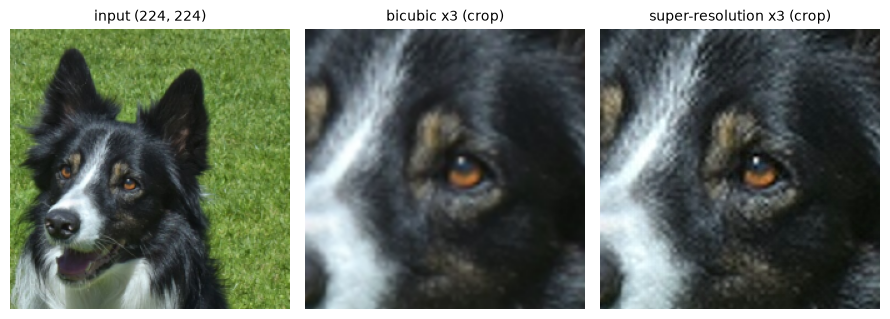

최종 크기: (672, 672)


In [76]:
img_out_y = Image.fromarray(np.uint8((img_out_y[0] * 255.0).clip(0, 255)[0]))

# 색차 성분은 단순히 키워서 Y와 합친다
final_img = Image.merge(
    "YCbCr", [
        img_out_y,
        img_cb.resize(img_out_y.size, Image.BICUBIC),
        img_cr.resize(img_out_y.size, Image.BICUBIC),
    ]).convert("RGB")

# 이미지를 저장한다
final_img.save("cat_superres_with_ort.jpg")

# 같은 부분을 잘라 단순 확대(bicubic)와 비교한다
bicubic_img = img.resize(final_img.size, Image.BICUBIC)
crop_box = (150, 250, 390, 490)
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
axes[0].imshow(img)
axes[0].set_title(f"input {img.size}", fontsize=10)
axes[1].imshow(bicubic_img.crop(crop_box))
axes[1].set_title("bicubic x3 (crop)", fontsize=10)
axes[2].imshow(final_img.crop(crop_box))
axes[2].set_title("super-resolution x3 (crop)", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("최종 크기:", final_img.size)

눈으로만 보지 않고 수치로도 비교합니다. 내려받은 사진의 밝기 성분을 3분의 1로 줄인 뒤 두 방법으로 되살려, 줄이기 전과의 PSNR(높을수록 가까움)을 계산합니다. 이 실험의 입력 크기는 변환 때 고정한 224와 다르므로, 같은 가중치를 가진 PyTorch 모델로 실행합니다.

In [77]:
def psnr(a: np.ndarray, b: np.ndarray) -> float:
    """0~1 범위 이미지 두 장의 PSNR(dB)을 계산합니다."""
    return float(-10 * np.log10(np.mean((a - b) ** 2)))


original_y = source_img.convert("YCbCr").split()[0]
low_size = (original_y.width // 3, original_y.height // 3)
high_size = (low_size[0] * 3, low_size[1] * 3)
target_y = np.asarray(original_y.resize(high_size, Image.BICUBIC), dtype=np.float32) / 255
low_y = original_y.resize(low_size, Image.BICUBIC)

with torch.no_grad():
    restored = torch_model(to_tensor(low_y)[None])[0, 0].clamp(0, 1).numpy()
bicubic_y = np.asarray(low_y.resize(high_size, Image.BICUBIC), dtype=np.float32) / 255
print(f"bicubic PSNR: {psnr(bicubic_y, target_y):.2f} dB")
print(f"모델 PSNR   : {psnr(restored, target_y):.2f} dB")

bicubic PSNR: 25.61 dB
모델 PSNR   : 25.80 dB


결과는 bicubic 25.61 dB, 모델 25.80 dB로 차이가 0.19 dB입니다. 위의 잘라 낸 그림에서는 모델 쪽이 눈 주변과 털 결에서 더 선명해 보이지만, PSNR의 차이는 작습니다. **선명해 보이는 것과 실제 사진에 가까운 것은 다릅니다.** 두 실험도 별개입니다. 그림은 224에서 672로 키운 것이라 정답 영상이 없고, PSNR은 170에서 510으로 되살린 실험입니다. 사진 한 장의 결과이고 이 가중치는 변환 튜토리얼용 예제이므로, 초해상화 일반의 성능을 말해 주지는 않습니다. 이번 교시에서 확인한 것은 화질이 아니라 **변환 전후의 출력이 같다**는 점입니다.

ONNX Runtime은 크로스플랫폼 엔진이어서 CPU와 GPU를 비롯한 여러 플랫폼에서 실행할 수 있습니다. Azure Machine Learning 같은 클라우드에 배포해 추론에 쓸 수도 있습니다.

- [Azure의 ONNX 설명](https://learn.microsoft.com/azure/machine-learning/concept-onnx)
- [ONNX Runtime 저장소](https://github.com/microsoft/onnxruntime)와 [공식 문서](https://onnxruntime.ai/docs/)

Q. 조건문이 있는 모델을 위 방식으로 내보내면 어떻게 될까요? 4교시 내용과 연결해 생각해 보세요.

<details><summary>답</summary>

변환기가 모델을 실행해 기록하는 방식이므로 값에 따라 달라지는 분기는 그대로 옮길 수 없습니다. 4.7절에서 본 것처럼 지금의 `torch.export` 기반 변환기는 값에 의존하는 분기를 만나면 오류를 내며, `torch.cond`로 다시 작성해야 합니다. `dynamo=False`로 부르는 TorchScript 기반 변환기는 추적 방식이어서 조용히 한쪽 경로만 남을 수 있습니다. 어느 쪽이든 변환 후 **출력을 수치로 비교**하는 습관이 안전장치입니다.

</details>

## 5.6 웹 서버로 모델 제공하기

가장 흔한 배포는 모델을 웹 서버 뒤에 두는 것입니다. 파이썬 서버라면 [FastAPI](https://fastapi.tiangolo.com/)와 ONNX Runtime 조합이 간단합니다. ResNet18을 ONNX로 내보내고, 이미지를 받아 예측을 돌려주는 서버를 만듭니다. 포트를 열지 않고 시험할 수 있도록 `TestClient`를 씁니다. 실제로 띄울 때는 `uvicorn 파일명:app`을 실행합니다.

먼저 PyTorch와 ONNX Runtime의 CPU 추론 시간도 재 봅니다. 4.6절의 방법을 씁니다.

In [78]:
deploy_model = models.resnet18(weights="DEFAULT").eval()
deploy_x = torch.rand(1, 3, 224, 224)
torch.onnx.export(deploy_model, (deploy_x,), "resnet18.onnx", input_names=["input"], output_names=["output"],
                  dynamic_shapes=[{0: torch.export.Dim("batch")}], external_data=False, dynamo=True, verbose=False)
deploy_session = onnxruntime.InferenceSession("resnet18.onnx", providers=["CPUExecutionProvider"])

with torch.no_grad():
    deploy_diff = np.abs(deploy_model(deploy_x).numpy() - deploy_session.run(None, {"input": deploy_x.numpy()})[0]).max()
print(f"출력의 최대 차이: {deploy_diff:.2e}")


def torch_ms(x_input: torch.Tensor) -> float:
    """PyTorch 호출 한 번의 시간(ms)을 잽니다."""
    start = time.perf_counter()
    with torch.no_grad():
        deploy_model(x_input)
    return 1000 * (time.perf_counter() - start)


def ort_ms(x_input: np.ndarray) -> float:
    """ONNX Runtime 호출 한 번의 시간(ms)을 잽니다."""
    start = time.perf_counter()
    deploy_session.run(None, {"input": x_input})
    return 1000 * (time.perf_counter() - start)


for _ in range(5):        # 앞쪽 호출은 버린다
    torch_ms(deploy_x)
    ort_ms(deploy_x.numpy())
torch_times, ort_times = [], []
for _ in range(30):       # 번갈아 재서 부하의 영향을 줄인다
    torch_times.append(torch_ms(deploy_x))
    ort_times.append(ort_ms(deploy_x.numpy()))
print(f"CPU PyTorch {np.median(torch_times):.2f} ms / ONNX Runtime {np.median(ort_times):.2f} ms")

출력의 최대 차이: 5.48e-06
CPU PyTorch 13.33 ms / ONNX Runtime 5.44 ms


In [79]:
app = FastAPI()


@app.post("/predict")
async def predict_image(request: Request) -> dict[str, float | str]:
    """요청 본문의 이미지 바이트를 받아 1위 클래스와 확률을 돌려줍니다."""
    with tempfile.NamedTemporaryFile(suffix=".img") as image_file:
        image_file.write(await request.body())
        image_file.flush()
        tensor = preprocess(Image.open(image_file.name).convert("RGB"))[None].numpy()
    logits = deploy_session.run(None, {"input": tensor})[0][0]
    probs = np.exp(logits) / np.exp(logits).sum()
    top = int(probs.argmax())
    return {"label": CATEGORIES[top], "probability": round(float(probs[top]), 3)}


client = TestClient(app)
response = client.post("/predict", content=Path(source_path).read_bytes())
print(response.status_code, response.json())
assert response.status_code == 200

200 {'label': 'Border collie', 'probability': 0.674}


위 출력에서 저자의 Mac CPU로 잰 ResNet18 추론은 PyTorch 13.33 ms, ONNX Runtime 5.44 ms였습니다. 한 번의 측정이며, CPU 스레드 설정과 모델에 따라 달라지므로 자신의 환경에서 재 보고 고르세요. 웹 서버의 응답은 3교시와 같은 사진을 Border collie로 분류했습니다.

서비스로 내보낼 때는 입력 크기 제한, 인증, 오류 처리, 동시 요청 수 제어를 더해야 합니다. 위 코드는 구조를 보여 주는 최소 예제입니다.

## 5.7 상황별 배포 경로

| 상황 | 현재의 기본 선택 | 비고 |
|---|---|---|
| 파이썬 서버에서 빠르게 | `torch.compile` + FastAPI 같은 웹 프레임워크 | 코드를 거의 안 바꿉니다 |
| 파이썬이 없는 서버, 다른 언어, 여러 하드웨어 | ONNX + [ONNX Runtime](https://onnxruntime.ai/docs/) | CUDA 등은 실행 제공자(provider)로 고릅니다 |
| 브라우저 | [ONNX Runtime Web](https://onnxruntime.ai/docs/tutorials/web/) | 3강의 웹 배포와 비교해 보세요 |
| 모바일, 임베디드 | `torch.export` + [ExecuTorch](https://github.com/pytorch/executorch) | `.pte` 파일로 기기에서 실행합니다 |
| 이미 있는 TorchScript 모델 유지 | `torch.jit.load` | 새 작업에는 권하지 않습니다(4.2절) |

서빙 전용 도구였던 [TorchServe](https://github.com/pytorch/serve)는 더는 유지보수되지 않습니다. 저장소가 보관(archive) 상태이고 보안 패치도 없으므로 새 프로젝트에 쓰지 마세요.

ExecuTorch의 내보내기는 다음과 같습니다. 패키지가 크므로 이 노트북의 필수 흐름에는 넣지 않았습니다. 아래 코드는 `pip install executorch`(v1.5 계열) 후 저자의 Mac에서 실행해 PyTorch 출력과의 차이가 약 3e-08인 것을 확인했습니다. Colab에서는 확인하지 못했습니다.

```python
from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner
from executorch.exir import to_edge_transform_and_lower
from executorch.runtime import Runtime

exported = torch.export.export(model, (example_input,))
program = to_edge_transform_and_lower(exported, partitioner=[XnnpackPartitioner()]).to_executorch()
Path("model.pte").write_bytes(program.buffer)

# 파이썬에서 시험 실행. 기기에서는 ExecuTorch 런타임이 같은 파일을 읽는다
method = Runtime.get().load_program("model.pte").load_method("forward")
output = method.execute([example_input])[0]
```

### 실습 5. 작은 CNN 내보내고 비교하기

`nn.Sequential(nn.Conv2d(3, 4, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(4, 2))`를 ONNX로 내보내세요. 첫 번째 차원을 동적으로 지정하고, 파일 이름은 `tiny.onnx`, 입력 이름은 `input`으로 합니다. **배치 크기 5**의 입력으로 ONNX Runtime과 PyTorch의 출력을 비교해 assert로 확인하세요.

In [80]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
set_seed()
tiny = nn.Sequential(nn.Conv2d(3, 4, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(4, 2)).eval()
torch.onnx.export(tiny, (torch.randn(1, 3, 32, 32),), "tiny.onnx", input_names=["input"], output_names=["output"],
                  dynamic_shapes=[{0: torch.export.Dim("batch")}], external_data=False, dynamo=True, verbose=False)
tiny_session = onnxruntime.InferenceSession("tiny.onnx", providers=["CPUExecutionProvider"])
tiny_x = torch.randn(5, 3, 32, 32)
tiny_ort = tiny_session.run(None, {"input": tiny_x.numpy()})[0]
with torch.no_grad():
    tiny_torch = tiny(tiny_x).numpy()
assert tiny_ort.shape == (5, 2)
np.testing.assert_allclose(tiny_torch, tiny_ort, rtol=1e-3, atol=1e-5)
print(np.abs(tiny_torch - tiny_ort).max())
```
</details>

---
# 6교시. JAX: 함수 변환으로 만드는 신경망

## 6.1 JAX의 세 가지 도구

JAX는 **NumPy와 비슷한 API에 함수 변환을 더한** 라이브러리입니다. PyTorch처럼 텐서에 기울기를 저장하는 대신, 함수를 받아 새 함수를 돌려주는 변환을 씁니다.

| 변환 | 하는 일 | PyTorch에서 비슷한 것 |
|---|---|---|
| `grad(f)` | $f$의 기울기를 계산하는 **함수**를 돌려줌 | `loss.backward()`, `torch.func.grad` |
| `jit(f)` | $f$를 XLA(선형대수 연산용 컴파일러)로 컴파일해 빠르게 실행하는 함수를 돌려줌 | `torch.compile` |
| `vmap(f)` | 샘플 하나용 $f$를 배치용으로 바꿈 | `torch.vmap` |

PyTorch와의 가장 큰 차이는 두 가지입니다.

- **상태가 없습니다.** 파라미터는 객체 안에 숨지 않고 함수의 인자로 드나듭니다.
- **난수에 상태가 없습니다.** 키(key)를 명시적으로 넘기고 나눕니다.

이번 교시의 코드는 JAX 공식 튜토리얼(Training a Simple Neural Network, with PyTorch Data Loading)을 바탕으로 합니다. Copyright 2018 The JAX Authors, [Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0)입니다. JAX로 계산을 하고, 데이터 읽기는 잘 만들어진 PyTorch 데이터 로더를 빌립니다. 신경망 라이브러리 없이 처음부터 만듭니다. ([JAX quickstart](https://docs.jax.dev/en/latest/quickstart.html))

먼저 세 도구를 작게 시험합니다.

In [81]:
print("JAX:", jax.__version__, "/ 장치:", jax.devices())


def square_sum(w: jnp.ndarray) -> jnp.ndarray:
    return jnp.sum(w ** 2)


# grad: 함수를 받아 기울기 함수를 돌려준다. x^2의 미분은 2x
grad_fn = grad(square_sum)
print("grad:", grad_fn(jnp.array([1.0, 2.0, 3.0])))
assert jnp.allclose(grad_fn(jnp.array([1.0, 2.0, 3.0])), jnp.array([2.0, 4.0, 6.0]))

# vmap: 샘플 하나용 함수를 배치용으로 바꾼다
print("vmap:", vmap(square_sum)(jnp.array([[1.0, 2.0], [3.0, 4.0]])))

# jit: 처음 호출할 때 컴파일하고, 이후에는 컴파일된 코드를 재사용한다
jit_fn = jit(square_sum)
print("jit:", jit_fn(jnp.array([1.0, 2.0, 3.0])))

# 난수: 같은 키는 항상 같은 값을 준다. 새 값이 필요하면 키를 나눈다
key = jrandom.PRNGKey(0)
print("같은 키:", jrandom.normal(key, (2,)), jrandom.normal(key, (2,)))
key_a, key_b = jrandom.split(key)
print("나눈 키:", jrandom.normal(key_a, (2,)), jrandom.normal(key_b, (2,)))

JAX: 0.12.0.1 / 장치: [CpuDevice(id=0)]


grad: [2. 4. 6.]
vmap: [ 5. 25.]
jit: 14.0
같은 키: [1.6226422 2.0252647] [1.6226422 2.0252647]
나눈 키: [ 1.0040143 -0.9063372] [-2.4424558 -2.0356805]


## 6.2 하이퍼파라미터와 파라미터 초기화

파라미터는 층마다 `(w, b)` 튜플을 담은 파이썬 리스트입니다. 다른 객체 없이 이것만으로 모델의 상태 전부입니다.

In [82]:
def random_layer_params(m: int, n: int, key: jnp.ndarray, scale: float = 1e-2) -> tuple[jnp.ndarray, jnp.ndarray]:
    """완전연결층 하나의 가중치와 편향을 무작위로 초기화합니다."""
    w_key, b_key = jrandom.split(key)
    return scale * jrandom.normal(w_key, (n, m)), scale * jrandom.normal(b_key, (n,))


def init_network_params(sizes: list[int], key: jnp.ndarray) -> list[tuple[jnp.ndarray, jnp.ndarray]]:
    """크기 목록 sizes를 따라 완전연결 신경망의 모든 층을 초기화합니다."""
    keys = jrandom.split(key, len(sizes))
    return [random_layer_params(m, n, k) for m, n, k in zip(sizes[:-1], sizes[1:], keys)]


layer_sizes = [784, 512, 512, 10]
step_size = 0.01
num_epochs = 8
batch_size = 128
n_targets = 10
params = init_network_params(layer_sizes, jrandom.PRNGKey(0))
print([(w.shape, b.shape) for w, b in params])

[((512, 784), (512,)), ((512, 512), (512,)), ((10, 512), (10,))]


## 6.3 자동 배치 예측

먼저 예측 함수를 **이미지 한 장**에 대해서 정의합니다. 배치는 `vmap`이 처리합니다. 튜토리얼은 이때 성능 손해가 없다(no performance penalty)고 설명합니다. 배치 차원을 신경 쓰지 않고 샘플 하나의 수식만 쓰면 되므로 코드가 단순해집니다.

`logits - logsumexp(logits)`는 log softmax를 뜻합니다. 로그 공간에서 합으로 나누는 것이므로 $\log \frac{e^{z_i}}{\sum_j e^{z_j}} = z_i - \log\sum_j e^{z_j}$입니다.

In [83]:
def relu(x: jnp.ndarray) -> jnp.ndarray:
    return jnp.maximum(0, x)


def predict(params: list, image: jnp.ndarray) -> jnp.ndarray:
    """이미지 한 장의 log softmax를 계산합니다."""
    activations = image
    for w, b in params[:-1]:
        outputs = jnp.dot(w, activations) + b
        activations = relu(outputs)

    final_w, final_b = params[-1]
    logits = jnp.dot(final_w, activations) + final_b
    return logits - logsumexp(logits)

이 함수가 정말로 이미지 한 장에서만 동작하는지 확인합니다.

In [84]:
# 한 장은 동작한다
random_flattened_image = jrandom.normal(jrandom.PRNGKey(1), (28 * 28,))
preds = predict(params, random_flattened_image)
print(preds.shape)

(10,)


In [85]:
# 배치는 동작하지 않는다. 일부러 보여 주는 오류이므로 try로 감쌉니다.
random_flattened_images = jrandom.normal(jrandom.PRNGKey(1), (10, 28 * 28))
try:
    preds = predict(params, random_flattened_images)
except TypeError:
    print("Invalid shapes!")

Invalid shapes!


In [86]:
# vmap으로 배치를 처리하게 고친다
# in_axes=(None, 0): params는 그대로 두고, image는 0번 축으로 나누어 반복한다
batched_predict = vmap(predict, in_axes=(None, 0))

# batched_predict의 호출 방식은 predict와 같다
batched_preds = batched_predict(params, random_flattened_images)
print(batched_preds.shape)

(10, 10)


이제 신경망을 정의하고 학습하는 데 필요한 재료가 모두 있습니다. 자동으로 배치를 처리하는 `predict`를 손실 함수에 쓰고, `grad`로 파라미터에 대한 기울기를 구하고, `jit`으로 전체를 빠르게 합니다.

## 6.4 유틸리티와 손실 함수

In [87]:
def one_hot(x: np.ndarray, k: int, dtype: type = jnp.float32) -> jnp.ndarray:
    """정수 라벨 x를 크기 k의 원-핫 벡터로 바꿉니다."""
    return jnp.array(x[:, None] == jnp.arange(k), dtype)


def accuracy(params: list, images: jnp.ndarray, targets: jnp.ndarray) -> jnp.ndarray:
    target_class = jnp.argmax(targets, axis=1)
    predicted_class = jnp.argmax(batched_predict(params, images), axis=1)
    return jnp.mean(predicted_class == target_class)


def loss(params: list, images: jnp.ndarray, targets: jnp.ndarray) -> jnp.ndarray:
    preds = batched_predict(params, images)
    return -jnp.mean(preds * targets)


@jit
def update(params: list, x: jnp.ndarray, y: jnp.ndarray) -> list:
    """한 배치의 경사 하강 한 걸음입니다. 파라미터를 바꾸지 않고 새 파라미터를 돌려줍니다."""
    grads = grad(loss)(params, x, y)
    return [(w - step_size * dw, b - step_size * db)
            for (w, b), (dw, db) in zip(params, grads)]

`loss`를 비판적으로 읽어 봅시다. `-jnp.mean(preds * targets)`는 배치 $N$과 클래스 $K$ 양쪽에 대해 평균을 냅니다. 원-핫이라 $K$개 중 하나만 0이 아니므로, 이 값은 교차 엔트로피가 아니라 **교차 엔트로피를 $K$로 나눈 값**입니다. 튜토리얼의 코드를 그대로 두었지만 이 차이를 알아 두어야 합니다. 기울기도 $1/K$로 줄어들므로, 교차 엔트로피 기준으로 보면 학습률이 `step_size / 10 = 0.001`인 셈입니다. 수치로 확인합니다.

In [88]:
check_targets = one_hot(np.array([3, 7, 1, 0, 9, 2, 2, 4, 5, 6]), n_targets)
true_cross_entropy = -jnp.mean(jnp.sum(batched_preds * check_targets, axis=1))
tutorial_loss = loss(params, random_flattened_images, check_targets)
print("교차 엔트로피:", true_cross_entropy)
print("튜토리얼 loss:", tutorial_loss, " x 10 =", tutorial_loss * n_targets)
assert jnp.isclose(true_cross_entropy, tutorial_loss * n_targets)

교차 엔트로피: 2.3040068
튜토리얼 loss: 0.23040067  x 10 = 2.3040066


## 6.5 PyTorch로 데이터 읽기

JAX는 프로그램 변환과 가속기용 NumPy에 집중하므로, 데이터 읽기 기능은 넣지 않았습니다. 이미 좋은 데이터 로더가 많기 때문입니다. PyTorch의 데이터 로더에 NumPy 배열을 돌려주는 얇은 층을 덧댑니다.

PyTorch와 torchvision은 맨 앞 셀에서 이미 준비했습니다.

In [89]:
def numpy_collate(batch: list) -> list | np.ndarray:
    """샘플 목록을 텐서가 아닌 NumPy 배열로 묶습니다."""
    if isinstance(batch[0], np.ndarray):
        return np.stack(batch)
    elif isinstance(batch[0], (tuple, list)):
        transposed = zip(*batch)
        return [numpy_collate(samples) for samples in transposed]
    else:
        return np.array(batch)


class NumpyLoader(DataLoader):
    """collate_fn만 바꾼 DataLoader입니다."""

    def __init__(self, dataset: Dataset, batch_size: int = 1, shuffle: bool = False, sampler: object = None,
                 batch_sampler: object = None, num_workers: int = 0, pin_memory: bool = False,
                 drop_last: bool = False, timeout: float = 0, worker_init_fn: object = None) -> None:
        super().__init__(dataset, batch_size=batch_size, shuffle=shuffle, sampler=sampler,
                         batch_sampler=batch_sampler, num_workers=num_workers, collate_fn=numpy_collate,
                         pin_memory=pin_memory, drop_last=drop_last, timeout=timeout,
                         worker_init_fn=worker_init_fn)


class FlattenAndCast:
    """이미지를 1차원 float 배열로 폅니다. 값은 0~255 그대로입니다."""

    def __call__(self, pic: Image.Image) -> np.ndarray:
        return np.ravel(np.array(pic, dtype=np.float32))

데이터셋을 정의합니다. 전체 이미지와 라벨은 `data`, `targets` 속성에 있습니다.

아래 로더에는 `shuffle`이 없어서 에폭마다 같은 순서로 학습합니다. 튜토리얼 그대로 두지만, 보통은 `shuffle=True`를 씁니다. 숙제에서 비교해 보세요.

In [90]:
# torch 데이터셋을 정의한다
mnist_dataset = MNIST("./data", download=True, transform=FlattenAndCast())
training_generator = NumpyLoader(mnist_dataset, batch_size=batch_size, num_workers=0)

In [91]:
# 학습 중 정확도 확인용 전체 학습 데이터
train_images = mnist_dataset.data.numpy().reshape(len(mnist_dataset.data), -1)
train_labels = one_hot(mnist_dataset.targets.numpy(), n_targets)

# 전체 테스트 데이터
mnist_dataset_test = MNIST("./data", download=True, train=False)
test_images = jnp.array(mnist_dataset_test.data.numpy().reshape(len(mnist_dataset_test.data), -1), dtype=jnp.float32)
test_labels = one_hot(mnist_dataset_test.targets.numpy(), n_targets)
print(train_images.shape, train_labels.shape, test_images.shape, test_labels.shape)

(60000, 784) (60000, 10) (10000, 784) (10000, 10)


## 6.6 학습 루프

In [92]:
for epoch in range(num_epochs):
    start_time = time.time()
    for x, y in training_generator:
        y = one_hot(y, n_targets)
        params = update(params, x, y)
    epoch_time = time.time() - start_time

    train_acc = accuracy(params, train_images, train_labels)
    test_acc = accuracy(params, test_images, test_labels)
    print(f"Epoch {epoch} in {epoch_time:0.2f} sec")
    print(f"Training set accuracy {train_acc:.4f}")
    print(f"Test set accuracy {test_acc:.4f}")

Epoch 0 in 0.78 sec
Training set accuracy 0.9134
Test set accuracy 0.9167


Epoch 1 in 0.58 sec
Training set accuracy 0.9359
Test set accuracy 0.9354


Epoch 2 in 0.59 sec
Training set accuracy 0.9476
Test set accuracy 0.9461


Epoch 3 in 0.59 sec
Training set accuracy 0.9559
Test set accuracy 0.9524


Epoch 4 in 0.59 sec
Training set accuracy 0.9621
Test set accuracy 0.9577


Epoch 5 in 0.59 sec
Training set accuracy 0.9663
Test set accuracy 0.9606


Epoch 6 in 0.59 sec
Training set accuracy 0.9702
Test set accuracy 0.9637


Epoch 7 in 0.59 sec
Training set accuracy 0.9733
Test set accuracy 0.9664


테스트 정확도는 8에폭 후 0.9664입니다.

이것으로 JAX의 핵심 API를 모두 썼습니다. 미분은 `grad`, 속도는 `jit`, 자동 벡터화는 `vmap`입니다. 계산은 NumPy처럼 작성했고, 데이터 로더는 PyTorch에서 빌렸습니다. GPU 런타임이라면 코드 변경 없이 GPU에서 돕니다. 위에서 출력한 `jax.devices()`를 확인해 보세요.

### 실습 6. 샘플별 기울기

선형 모델 $\hat{y} = w \cdot x$의 샘플 하나에 대한 제곱 오차 $(w \cdot x - y)^2$을 함수 `sample_loss(w, x, y)`로 작성하세요. `vmap`과 `grad`를 조합해 **샘플별 기울기**를 구하는 `per_sample_grads`를 만드세요. PyTorch도 `torch.func`에서 같은 조합을 씁니다. 입력 `xs`가 4개, 특징이 3개이면 결과 모양은 `(4, 3)`입니다. 손으로 유도한 $2(w \cdot x - y)x$와 비교해 assert로 확인하세요.

In [93]:
w_demo = jnp.array([1.0, -2.0, 0.5])
xs_demo = jrandom.normal(jrandom.PRNGKey(3), (4, 3))
ys_demo = jnp.array([1.0, 0.0, -1.0, 2.0])
# 여기에 작성하세요

<details><summary>정답</summary>

```python
w_demo = jnp.array([1.0, -2.0, 0.5])
xs_demo = jrandom.normal(jrandom.PRNGKey(3), (4, 3))
ys_demo = jnp.array([1.0, 0.0, -1.0, 2.0])

def sample_loss(w: jnp.ndarray, x: jnp.ndarray, y: jnp.ndarray) -> jnp.ndarray:
    return (jnp.dot(w, x) - y) ** 2

# w는 고정하고 x, y만 샘플 축으로 반복한다
per_sample_grads = vmap(grad(sample_loss), in_axes=(None, 0, 0))
result = per_sample_grads(w_demo, xs_demo, ys_demo)
expected = 2 * (xs_demo @ w_demo - ys_demo)[:, None] * xs_demo
assert result.shape == (4, 3)
assert jnp.allclose(result, expected)
print(result.shape)
```
</details>

---
# 7교시. 하이퍼파라미터 탐색: Ray Tune

> 참고: [PyTorch 한국어 튜토리얼 - Ray Tune을 이용한 하이퍼파라미터 튜닝](https://tutorials.pytorch.kr/beginner/hyperparameter_tuning_tutorial.html)

## 7.1 준비

[Ray Tune](https://docs.ray.io/en/latest/tune/index.html)은 분산 하이퍼파라미터 탐색 도구입니다. 여러 탐색 알고리즘을 갖추었고, TensorBoard 등 분석 도구와 연동되며, [Ray](https://ray.io/)의 분산 실행 엔진 위에서 돕니다. 여기서는 CIFAR-10 분류기를 다룬 [PyTorch 튜토리얼](https://tutorials.pytorch.kr/beginner/blitz/cifar10_tutorial.html)을 확장합니다.

필요한 수정은 많지 않습니다.

1. 데이터 읽기와 학습 부분을 함수로 감쌉니다.
2. 신경망의 일부 파라미터를 설정 가능하게 합니다.
3. 체크포인트를 추가합니다 (선택).
4. 탐색 공간을 정의합니다.

검색하면 `tune.run(...)`, `tune.checkpoint_dir(...)`를 쓰는 예제가 많이 나옵니다. 현재 버전에서는 다음 표의 오른쪽 API를 씁니다.

| 검색에서 자주 보는 코드 | 현재 API |
|---|---|
| `tune.run(...)` | `tune.Tuner(...).fit()` |
| `tune.report(loss=..., accuracy=...)` | `tune.report({"loss": ..., "accuracy": ...}, checkpoint=...)` |
| `tune.checkpoint_dir(epoch)`, 인자 `checkpoint_dir` | `tune.Checkpoint.from_directory(...)`, `tune.get_checkpoint()` |
| `resources_per_trial=` | `tune.with_resources(함수, {...})` |
| `result.get_best_trial(...)`, `best_trial.checkpoint.value` | `results.get_best_result(...)`, `result.checkpoint` |

맨 앞 셀의 import 중 `ray`, `tune`, `ASHAScheduler`만 Ray Tune용이고, 나머지는 평범한 PyTorch입니다.

진행 상황 표의 열은 `CLIReporter`로 정해 `RunConfig`에 넘깁니다. 여기서는 출력이 길어지지 않게 끄고(`verbose=0`) 결과만 표로 봅니다.

```python
reporter = CLIReporter(metric_columns=["loss", "accuracy", "training_iteration"])
run_config = tune.RunConfig(progress_reporter=reporter)
```

## 7.2 데이터 로더

데이터 읽기를 함수로 감싸고 데이터 폴더를 인자로 받습니다. 시도(trial)마다 실행 폴더가 달라지므로 **절대 경로**를 넘겨 같은 데이터를 공유합니다.

In [94]:
def load_data(data_dir: str = "./data") -> tuple[Dataset, Dataset]:
    """CIFAR-10 학습 집합과 테스트 집합을 읽습니다."""
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])

    trainset = torchvision.datasets.CIFAR10(root=data_dir, train=True, download=True, transform=transform)
    testset = torchvision.datasets.CIFAR10(root=data_dir, train=False, download=True, transform=transform)
    return trainset, testset

## 7.3 설정 가능한 신경망

설정 가능한 파라미터만 탐색할 수 있습니다. 이 예시에서는 완전연결층의 크기를 지정합니다.

In [95]:
class Net(nn.Module):
    def __init__(self, l1: int = 120, l2: int = 84) -> None:
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, l1)
        self.fc2 = nn.Linear(l1, l2)
        self.fc3 = nn.Linear(l2, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

## 7.4 학습 함수

학습 코드를 `train_cifar(config, data_dir=None, subset_size=None)` 함수로 감쌉니다. `config`로 탐색할 하이퍼파라미터가 들어옵니다.

```python
net = Net(config["l1"], config["l2"])
optimizer = optim.SGD(net.parameters(), lr=config["lr"], momentum=0.9)
```

학습 데이터를 학습과 검증으로 나눕니다. 80%로 학습하고 나머지 20%로 검증합니다. 배치 크기도 설정할 수 있습니다.

**테스트 집합은 탐색에 쓰지 않습니다.** 탐색은 검증 손실로 하고, 다 끝난 뒤 가장 좋은 모델을 테스트 집합에서 한 번만 평가합니다.

### GPU와 DataParallel

여러 GPU가 있으면 모델을 `nn.DataParallel`로 감쌀 수 있습니다. (8교시에서 자세히 다룹니다)

```python
device = "cpu"
if torch.cuda.is_available():
    device = "cuda:0"
    if torch.cuda.device_count() > 1:
        net = nn.DataParallel(net)
net.to(device)
```

`device` 변수를 쓰면 GPU가 없어도 학습할 수 있습니다. 데이터는 명시적으로 장치에 보냅니다.

```python
for i, data in enumerate(trainloader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)
```

Ray는 [GPU의 일부만 할당(fractional GPU)](https://docs.ray.io/en/latest/ray-core/scheduling/accelerators.html)하는 것도 지원합니다. 모델이 GPU 메모리에 들어가기만 하면 `{"gpu": 0.5}`처럼 한 GPU를 여러 시도가 나누어 쓸 수 있습니다. 시도는 요청하지 않은 GPU에 접근할 수 없으므로, 같은 자원을 쓰는 시도끼리 충돌할 걱정은 없습니다.

### Ray Tune과 소통하기

가장 중요한 부분입니다. 에폭이 끝날 때마다 체크포인트를 저장하고 지표를 Ray Tune에 보고합니다.

```python
with tempfile.TemporaryDirectory() as checkpoint_dir:
    torch.save((net.state_dict(), optimizer.state_dict(), epoch + 1), Path(checkpoint_dir) / "checkpoint.pt")
    tune.report({"loss": val_loss / val_steps, "accuracy": correct / total},
                checkpoint=tune.Checkpoint.from_directory(checkpoint_dir))
```

Ray Tune은 이 지표로 가장 좋은 설정을 고르고, 성능이 나쁜 시도를 일찍 멈춥니다. 체크포인트는 선택이지만 [Population Based Training](https://docs.ray.io/en/latest/tune/examples/pbt_guide.html) 같은 고급 스케줄러에 필요하고, 나중에 학습된 모델을 불러와 테스트할 때도 씁니다. 복원은 시작할 때 `tune.get_checkpoint()`로 합니다.

### 전체 학습 함수

구현에서 볼 점이 있습니다. 시도에 CPU 2개만 할당하면서 `num_workers=8`처럼 많이 쓰면 자원이 넘치므로 `num_workers=0`으로 둡니다. 데이터가 작아 이 편이 안정적입니다. 또 `subset_size`를 받아 작은 탐색을 할 수 있게 합니다. 검증 로더는 섞을 이유가 없어 `shuffle=False`입니다. 학습 중 손실은 찍지 않습니다. 작업 프로세스의 출력을 끄기 때문이며, 지표는 `tune.report`로 받습니다. 테스트 평가는 큰 배치(256)로 해도 정확도가 같고 더 빠릅니다.

In [96]:
def train_cifar(config: dict, data_dir: str | None = None, subset_size: int | None = None, max_epochs: int = 10) -> None:
    """Ray Tune이 시도마다 호출하는 학습 함수입니다."""
    net = Net(config["l1"], config["l2"])

    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda:0"
        if torch.cuda.device_count() > 1:
            net = nn.DataParallel(net)
    net.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=config["lr"], momentum=0.9)

    # 체크포인트가 있으면 이어서 학습한다
    start_epoch = 0
    checkpoint = tune.get_checkpoint()
    if checkpoint:
        with checkpoint.as_directory() as checkpoint_dir:
            model_state, optimizer_state, start_epoch = torch.load(Path(checkpoint_dir) / "checkpoint.pt", map_location=device)
        net.load_state_dict(model_state)
        optimizer.load_state_dict(optimizer_state)

    trainset, _ = load_data(data_dir)
    if subset_size is not None:
        trainset = Subset(trainset, range(subset_size))

    train_size = int(len(trainset) * 0.8)
    train_subset, val_subset = random_split(trainset, [train_size, len(trainset) - train_size])

    trainloader = DataLoader(train_subset, batch_size=int(config["batch_size"]), shuffle=True, num_workers=0)
    valloader = DataLoader(val_subset, batch_size=int(config["batch_size"]), shuffle=False, num_workers=0)

    for epoch in range(start_epoch, max_epochs):
        net.train()
        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(net(inputs), labels)
            loss.backward()
            optimizer.step()

        # 검증 손실과 정확도
        net.eval()
        val_loss, val_steps, total, correct = 0.0, 0, 0, 0
        with torch.no_grad():
            for inputs, labels in valloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = net(inputs)
                correct += (outputs.argmax(dim=1) == labels).sum().item()
                total += labels.size(0)
                val_loss += criterion(outputs, labels).item()
                val_steps += 1

        # 체크포인트를 저장하고 지표를 보고한다. 이 지표로 Ray Tune이 시도를 멈출지 결정한다
        with tempfile.TemporaryDirectory() as checkpoint_dir:
            torch.save((net.state_dict(), optimizer.state_dict(), epoch + 1), Path(checkpoint_dir) / "checkpoint.pt")
            tune.report({"loss": val_loss / val_steps, "accuracy": correct / total},
                        checkpoint=tune.Checkpoint.from_directory(checkpoint_dir))

대부분의 코드는 원래 예제 그대로입니다.

## 7.5 테스트 집합 정확도

머신러닝 모델의 성능은 학습에 쓰지 않은 데이터로 평가합니다. 테스트 평가도 함수로 감쌉니다. `device` 인자가 있어 GPU에서도 평가할 수 있습니다.

In [97]:
def test_accuracy(net: nn.Module, device: str = "cpu", data_dir: str = "./data") -> float:
    """테스트 집합의 정확도를 계산합니다."""
    _, testset = load_data(data_dir)
    testloader = DataLoader(testset, batch_size=256, shuffle=False, num_workers=0)

    correct = 0
    total = 0
    net.eval()
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

## 7.6 탐색 공간과 실행

탐색 공간은 다음과 같이 정의합니다.

```python
config = {
    "l1": tune.sample_from(lambda _: 2 ** np.random.randint(2, 9)),
    "l2": tune.sample_from(lambda _: 2 ** np.random.randint(2, 9)),
    "lr": tune.loguniform(1e-4, 1e-1),
    "batch_size": tune.choice([2, 4, 8, 16]),
}
```

- `tune.sample_from()`은 원하는 샘플링 방법을 직접 정의합니다. `l1`, `l2`는 4, 8, 16, 32, 64, 128, 256 중 하나입니다.
- `lr`은 0.0001과 0.1 사이에서 **로그 스케일로 균일하게** 뽑습니다. 로그 균일은 0.0001~0.001 구간과 0.01~0.1 구간이 같은 확률을 갖습니다. 학습률처럼 자릿수 단위로 영향을 주는 값에 적합합니다.
- `batch_size`는 주어진 후보 중 하나입니다.

시도마다 Ray Tune이 이 공간에서 조합을 무작위로 뽑아 여러 모델을 학습합니다. 성능이 좋지 않은 시도를 일찍 끝내기 위해 **ASHA**(Asynchronous Successive Halving) 스케줄러를 씁니다. `grace_period=1`과 `reduction_factor=2`이면 에폭 1, 2, 4...의 지점마다 지금까지의 시도 중 성적이 **상위 절반**에 들지 못한 시도를 멈춥니다.

시도에 쓸 자원은 `tune.with_resources`로 알려 줍니다. 상수 인자 `data_dir`는 `functools.partial`로 묶습니다.

```python
trainable = tune.with_resources(partial(train_cifar, data_dir=data_dir), {"cpu": 2, "gpu": gpus_per_trial})
```

체크포인트는 학습 함수 안에서 `tune.report`로 직접 저장합니다. `tune.run` 예제의 `checkpoint_at_end=True`는 학습 끝에 체크포인트를 남기는 옵션입니다. `gpus_per_trial=0.5`처럼 일부만 줄 수도 있습니다. GPU가 없는 환경에서 `gpu`를 1 이상 요청하면 시도가 영원히 대기하므로, 아래 코드는 GPU가 있을 때만 요청합니다.

학습이 끝나면 가장 좋은 시도를 찾아 체크포인트를 불러오고, 테스트 정확도를 구합니다. 스크립트라면 `if __name__ == "__main__":` 아래에서 호출합니다. 노트북에서는 그 조건이 필요 없습니다.

In [98]:
def run_search(num_samples: int = 10, max_num_epochs: int = 10, gpus_per_trial: float = 0, subset_size: int | None = None,
               batch_sizes: tuple[int, ...] = (2, 4, 8, 16)) -> tune.ResultGrid:
    """탐색을 실행하고, 가장 좋은 시도의 설정과 테스트 정확도를 출력합니다."""
    data_dir = os.path.abspath("./data")
    load_data(data_dir)      # 시도가 동시에 내려받지 않도록 미리 내려받는다
    config = {
        "l1": tune.sample_from(lambda _: 2 ** np.random.randint(2, 9)),
        "l2": tune.sample_from(lambda _: 2 ** np.random.randint(2, 9)),
        "lr": tune.loguniform(1e-4, 1e-1),
        "batch_size": tune.choice(list(batch_sizes)),
    }
    scheduler = ASHAScheduler(max_t=max_num_epochs, grace_period=1, reduction_factor=2)

    trainable = partial(train_cifar, data_dir=data_dir, subset_size=subset_size, max_epochs=max_num_epochs)
    tuner = tune.Tuner(
        tune.with_resources(trainable, {"cpu": 2, "gpu": gpus_per_trial}),
        param_space=config,
        tune_config=tune.TuneConfig(metric="loss", mode="min", scheduler=scheduler, num_samples=num_samples,
                                    max_concurrent_trials=2),
        run_config=tune.RunConfig(storage_path=os.path.abspath("./ray_results"), verbose=0),
    )
    results = tuner.fit()

    best_result = results.get_best_result("loss", "min")
    print("Best trial config:", best_result.config)
    print("Best trial final validation loss:", round(best_result.metrics["loss"], 4))
    print("Best trial final validation accuracy:", round(best_result.metrics["accuracy"], 4))

    best_trained_model = Net(best_result.config["l1"], best_result.config["l2"])
    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda:0"
        if torch.cuda.device_count() > 1:
            best_trained_model = nn.DataParallel(best_trained_model)
    best_trained_model.to(device)

    with best_result.checkpoint.as_directory() as checkpoint_dir:
        model_state, _, _ = torch.load(Path(checkpoint_dir) / "checkpoint.pt", map_location=device)
    best_trained_model.load_state_dict(model_state)

    print("Best trial test set accuracy:", test_accuracy(best_trained_model, device, data_dir))
    return results

### 실행하기: 오래 걸리는 이유와 작은 탐색

저자가 `num_samples=10, max_num_epochs=10, gpus_per_trial=0`으로 Colab에서 돌렸을 때는 너무 오래 걸려 손으로 중단했습니다(`KeyboardInterrupt`). **코드의 오류가 아니라 비용 문제**였습니다. 원인은 CPU 학습에 배치 크기 2였습니다. 출력의 `Logical resource usage: 2.0/2 CPUs, 0/1 GPUs`를 보면, CPU 2개에 시도당 2개를 요청해 시도가 **한 번에 하나씩** 돌았고, GPU가 있었는데도 요청하지 않았습니다. 5만 장의 80%를 배치 2로 돌면 에폭당 2만 번 갱신해야 합니다. 아래 표를 보면 배치 2짜리 시도는 한 에폭에 약 2분 걸렸습니다.

중단 전 기록은 다음과 같습니다. 이 노트북을 실행한 결과가 아닌 저자의 기록입니다. 가장 좋은 시도의 정확도가 약 57.7%이고, 나쁜 시도는 ASHA가 1에폭 만에 끝냈습니다(`iter`가 1).

```
+----------------------------------------------------------------------------------------------------------------------+
| Trial name                status                lr     batch_size     iter     total time (s)      loss     accuracy |
+----------------------------------------------------------------------------------------------------------------------+
| train_cifar_770d1_00004   RUNNING      0.000264698              2        1            120.791   1.53111       0.4463 |
| train_cifar_770d1_00000   TERMINATED   0.000934255              4       10            707.464   1.23026       0.5774 |
| train_cifar_770d1_00001   TERMINATED   0.0129459                8        1             43.506   1.91538       0.2476 |
| train_cifar_770d1_00002   TERMINATED   0.00589926               2        1            114.89    2.11121       0.2128 |
| train_cifar_770d1_00003   TERMINATED   0.0588695                2        1            130.468   2.3919        0.0966 |
| train_cifar_770d1_00005   PENDING      0.000108719              4                                                    |
| train_cifar_770d1_00006   PENDING      0.000132984             16                                                    |
| train_cifar_770d1_00007   PENDING      0.0572719                4                                                    |
| train_cifar_770d1_00008   PENDING      0.00592024               2                                                    |
| train_cifar_770d1_00009   PENDING      0.000164173              8                                                    |
+----------------------------------------------------------------------------------------------------------------------+
```

여기서는 몇 분 안에 끝나도록 **작은 탐색**을 합니다. 학습 데이터 1만 장, 시도 6개, 최대 3에폭, 그리고 16 이상의 배치입니다. 데이터도 에폭도 줄였으므로, 아래 정확도는 탐색 과정을 보여 주는 값일 뿐 이 모델의 성능이 아닙니다. 전체 탐색은 맨 아래 주석처럼 실행합니다.

노트북의 전역 함수는 Ray가 직렬화해 작업 프로세스로 보냅니다. 탐색이 끝나면 `ray.shutdown()`으로 프로세스를 정리합니다.

In [99]:
ray.init(ignore_reinit_error=True, include_dashboard=False, log_to_driver=False, logging_level="ERROR")

set_seed()
search_gpus = 0.5 if torch.cuda.is_available() else 0
results = run_search(num_samples=6, max_num_epochs=3, gpus_per_trial=search_gpus, subset_size=10000, batch_sizes=(16, 32, 64))

# 시도별 결과를 표로 본다
frame = results.get_dataframe()
columns = ["config/lr", "config/batch_size", "config/l1", "config/l2", "training_iteration", "loss", "accuracy"]
print(frame[columns].sort_values("loss").round(4).to_string(index=False))

# 전체 탐색. GPU가 있을 때만 gpus_per_trial=1을 쓰세요. 없는 GPU를 요청하면 시도가 계속 대기합니다.
# results = run_search(num_samples=10, max_num_epochs=10, gpus_per_trial=1)

Best trial config: {'l1': 32, 'l2': 64, 'lr': 0.011933086173118213, 'batch_size': 32}
Best trial final validation loss: 1.5684
Best trial final validation accuracy: 0.436


Best trial test set accuracy: 0.4228
 config/lr  config/batch_size  config/l1  config/l2  training_iteration   loss  accuracy
    0.0119                 32         32         64                   3 1.5684    0.4360
    0.0763                 64         64         32                   2 1.7621    0.3455
    0.0762                 32        256          8                   2 1.9981    0.2415
    0.0004                 32        128        256                   1 2.3033    0.1095
    0.0001                 16         16        128                   1 2.3034    0.1040
    0.0009                 16          4         32                   1 2.3059    0.0980


`training_iteration`이 1이나 2에서 끝난 시도는 ASHA가 일찍 멈춘 것입니다. 표의 시도 수와 반복 횟수를 곱해 보면 전부 끝까지 돌렸을 때(6 x 3 = 18 에폭)보다 얼마나 아꼈는지 알 수 있습니다.

저장된 표에서 학습률이 0.001 안팎 이하인 세 시도는 1에폭 뒤에도 손실이 무작위 수준이었습니다. 2.30은 10개 클래스를 무작위로 찍을 때의 교차 엔트로피($\ln 10 \approx 2.303$)입니다. 그래서 ASHA가 멈췄습니다. 더 돌렸을 때 나아졌을지는 이 표로 알 수 없습니다. ASHA의 조기 종료에는 늦게 좋아지는 시도를 놓칠 위험이 따릅니다. 시도 수가 작고 시드를 고정하지 않은 부분도 있어, 다시 실행하면 표가 달라집니다.

In [100]:
total_epochs = int(frame["training_iteration"].sum())
print(f"실제 학습한 에폭: {total_epochs} / 조기 종료가 없었다면: {6 * 3}")
assert len(frame) == 6
assert frame["training_iteration"].max() <= 3

실제 학습한 에폭: 10 / 조기 종료가 없었다면: 18


여러분의 모델도 같은 방식으로 바꿀 수 있습니다. 숙제에서 해 보세요.

### 실습 7. 가장 작은 Tune 예제

학습 없이 Ray Tune의 구조만 익혀 봅시다. `def objective(config)`를 작성하세요. 안에서 `tune.report({"score": (config["x"] - 3) ** 2})`를 호출합니다. 탐색 공간은 `{"x": tune.grid_search([0.0, 1.0, 2.0, 3.0, 4.0])}`이고, `metric="score"`, `mode="min"`입니다. 가장 좋은 결과의 `x`가 3.0인지 assert로 확인하세요.

In [101]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def objective(config: dict) -> None:
    tune.report({"score": (config["x"] - 3) ** 2})

tuner = tune.Tuner(
    objective,
    param_space={"x": tune.grid_search([0.0, 1.0, 2.0, 3.0, 4.0])},
    tune_config=tune.TuneConfig(metric="score", mode="min"),
    run_config=tune.RunConfig(storage_path=os.path.abspath("./ray_results"), verbose=0),
)
best = tuner.fit().get_best_result()
assert best.config["x"] == 3.0
assert best.metrics["score"] == 0.0
print(best.config)
```
</details>

In [102]:
# 다음 교시로 가기 전에 Ray 프로세스를 정리합니다
ray.shutdown()

---
# 8교시. 데이터 병렬과 모델 병렬

## 8.1 두 가지 병렬화

GPU가 여러 개일 때 나누어 쓰는 방법은 크게 두 가지입니다.

- **데이터 병렬**: 모델을 GPU마다 **복제**하고, 배치를 잘라서 나누어 줍니다. 모델이 GPU 하나에 들어갈 때, 학습을 빠르게 하는 방법입니다.
- **모델 병렬**: 모델을 **나누어** GPU마다 일부를 올립니다. 모델이 GPU 하나에 들어가지 않을 때 쓰는 방법입니다. 층 단위로 나누는 방식(inter-layer, layer-wise)과 층 안의 텐서를 나누는 방식(intra-layer, tensor parallelism)이 있습니다. ([그림 출처: 네이버 블로그](https://mblogthumb-phinf.pstatic.net/MjAyMjA0MDdfMTIx/MDAxNjQ5MzMxNTAxMDYy.gGWjDl7J9L7_2aHO9_tht6wcxrS7xHwHorOdbO_mbGwg.qr64qGweXwy6A1e1e__U2seiVU8GSOoaXGwoBydNWFAg.PNG.dh0985/image.png?type=w800), 원 출처 표기: LG AI Talk Concert)

이 교시의 많은 코드는 GPU가 2개 이상이어야 의미가 있습니다. Colab의 기본 런타임은 GPU가 1개입니다. GPU가 1개인 Colab에서 `cuda:1`을 요청하면 `RuntimeError: CUDA error: invalid device ordinal`이 납니다. 그래서 아래의 코드는 **GPU 수를 확인해 실행 여부를 정합니다.** 여기 나오는 멀티 GPU 수치는 공식 튜토리얼에 기록된 예시입니다.

CUDA 사용 가능: False
GPU 수: 0
nvidia-smi가 없습니다: 이 환경에는 NVIDIA GPU가 없습니다.


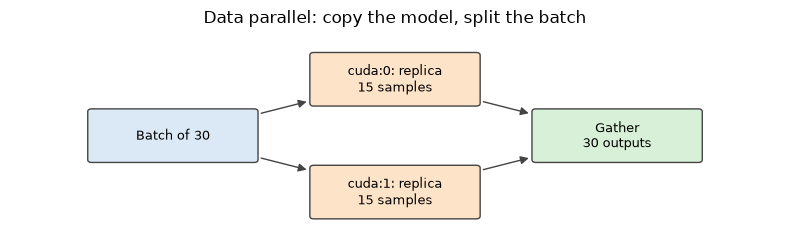

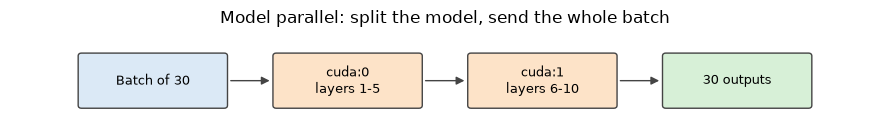

In [103]:
NUM_GPUS = torch.cuda.device_count()
print("CUDA 사용 가능:", torch.cuda.is_available())
print("GPU 수:", NUM_GPUS)
if shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True, timeout=30).stdout)
else:
    print("nvidia-smi가 없습니다: 이 환경에는 NVIDIA GPU가 없습니다.")

# 두 방식을 그림으로 나란히 봅니다
draw_diagram(
    {
        "batch": (0, 1.5, "Batch of 30", "#dbe9f6"),
        "g0": (3, 2.5, "cuda:0: replica\n15 samples", "#fde3c8"),
        "g1": (3, 0.5, "cuda:1: replica\n15 samples", "#fde3c8"),
        "out": (6, 1.5, "Gather\n30 outputs", "#d7f0d7"),
    },
    [("batch", "g0"), ("batch", "g1"), ("g0", "out"), ("g1", "out")],
    figsize=(8, 2.6), title="Data parallel: copy the model, split the batch", box_size=(2.2, 0.85),
)
draw_diagram(
    {
        "batch": (0, 0, "Batch of 30", "#dbe9f6"),
        "g0": (3, 0, "cuda:0\nlayers 1-5", "#fde3c8"),
        "g1": (6, 0, "cuda:1\nlayers 6-10", "#fde3c8"),
        "out": (9, 0, "30 outputs", "#d7f0d7"),
    },
    [("batch", "g0"), ("g0", "g1"), ("g1", "out")],
    figsize=(9, 1.5), title="Model parallel: split the model, send the whole batch", box_size=(2.2, 0.85),
)

## 8.2 데이터 병렬: `DataParallel`

PyTorch에서 GPU를 쓰는 것은 간단합니다. 먼저 모델을 GPU에 넣습니다.

```python
device = torch.device("cuda:0")
model.to(device)
```

그다음 텐서를 GPU로 옮깁니다.

```python
mytensor = my_tensor.to(device)
```

`my_tensor.to(device)`는 `my_tensor`를 바꾸지 않고 **새 텐서를 돌려줍니다**. 그래서 결과를 변수에 받아 써야 합니다. 반면 `nn.Module`의 `.to(device)`는 모델 자체를 옮깁니다.

PyTorch는 기본적으로 GPU 하나만 씁니다. `DataParallel`로 감싸면 여러 GPU에서 실행합니다.

```python
model = nn.DataParallel(model)
```

> **주의**: 지금은 공식 문서가 `DataParallel` 대신 `DistributedDataParallel`(DDP)을 권합니다. `DataParallel`은 한 프로세스의 파이썬 스레드로 동작해 GIL의 제약을 받고, 첫 번째 GPU에 부담이 쏠립니다. 원리를 이해하기에는 좋으므로 먼저 보고, 8.4절에서 DDP를 봅니다. ([공식 문서](https://pytorch.org/docs/stable/generated/torch.nn.DataParallel.html))

### 불러오기와 매개변수

In [104]:
# 매개변수와 DataLoader 설정 (필요한 모듈은 맨 앞 셀에서 불러왔습니다)
input_size = 5
output_size = 2

batch_size = 30
data_size = 100

### 장치

In [105]:
# 앞에서 쓴 device(MPS 포함)와 구분합니다. DataParallel은 CUDA 전용입니다
dp_device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(dp_device)

cpu


### 더미 데이터셋

무작위 데이터셋을 만듭니다. `__getitem__`과 `__len__`만 구현하면 됩니다.

In [106]:
class RandomDataset(Dataset):
    def __init__(self, size: int, length: int) -> None:
        self.len = length
        self.data = torch.randn(length, size)

    def __getitem__(self, index: int) -> torch.Tensor:
        return self.data[index]

    def __len__(self) -> int:
        return self.len


set_seed()
rand_loader = DataLoader(dataset=RandomDataset(input_size, data_size), batch_size=batch_size, shuffle=True)

### 간단한 모델

입력을 받아 선형 연산을 하고 출력을 내는 모델입니다. `DataParallel`은 CNN, RNN 등 어떤 모델에든 쓸 수 있습니다. 입력과 출력의 크기를 보기 위해 모델 안에 `print`를 넣었습니다. 모델 안에서 찍히는 크기(`In Model`)를 주의해서 보세요.

In [107]:
class Model(nn.Module):
    def __init__(self, input_size: int, output_size: int) -> None:
        super().__init__()
        self.fc = nn.Linear(input_size, output_size)

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        output = self.fc(input)
        print("\tIn Model: input size", input.size(), "output size", output.size())
        return output

### 모델과 데이터 병렬 구현

핵심 부분입니다. 모델을 만들고 GPU가 여러 개인지 확인합니다. 여러 개이면 `nn.DataParallel`로 감쌉니다. 그런 다음 `model.to(device)`로 GPU에 넣습니다.

In [108]:
dp_model = Model(input_size, output_size)
if NUM_GPUS > 1:
    print("Let's use", NUM_GPUS, "GPUs!")
    # dim = 0 [30, xxx] -> [10, ...], [10, ...], [10, ...] on 3 GPUs
    dp_model = nn.DataParallel(dp_model)

dp_model.to(dp_device)

Model(
  (fc): Linear(in_features=5, out_features=2, bias=True)
)

### 모델 실행

입력과 출력 텐서의 크기를 봅니다.

In [109]:
for data in rand_loader:
    input = data.to(dp_device)
    output = dp_model(input)
    print("Outside: input size", input.size(), "output_size", output.size())

	In Model: input size torch.Size([30, 5]) output size torch.Size([30, 2])
Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
	In Model: input size torch.Size([30, 5]) output size torch.Size([30, 2])
Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
	In Model: input size torch.Size([30, 5]) output size torch.Size([30, 2])
Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
	In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
Outside: input size torch.Size([10, 5]) output_size torch.Size([10, 2])


### 결과

GPU가 없거나 하나이면 위의 출력처럼 모델이 30개를 받아 30개를 냅니다. 마지막 배치만 100 - 30 x 3 = 10개입니다. GPU가 여러 개이면 `In Model`의 크기가 나뉩니다. 아래는 **공식 튜토리얼에 기록된 예시**입니다. 이 노트북을 실행한 결과가 아닙니다.

**GPU 2개**
```
Let's use 2 GPUs!
    In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
    In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
    In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
    In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
    In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
    In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
    In Model: input size torch.Size([5, 5]) output size torch.Size([5, 2])
    In Model: input size torch.Size([5, 5]) output size torch.Size([5, 2])
Outside: input size torch.Size([10, 5]) output_size torch.Size([10, 2])
```

**GPU 3개** (첫 배치와 마지막 배치만 표시, 앞의 세 배치는 모두 10, 10, 10으로 나뉩니다)
```
Let's use 3 GPUs!
    In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
    In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
    In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
    ...
    In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
    In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
    In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
Outside: input size torch.Size([10, 5]) output_size torch.Size([10, 2])
```

**GPU 8개** (앞의 세 배치는 모두 아래의 첫 묶음처럼 나뉩니다. 호출 순서는 스레드에 따라 뒤섞입니다)
```
Let's use 8 GPUs!
    In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])   (7개 GPU)
    In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])   (1개 GPU)
Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
    ...
    In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])   (5개 GPU만 사용)
Outside: input size torch.Size([10, 5]) output_size torch.Size([10, 2])
```

이 숫자들은 GPU 없이도 검산할 수 있습니다. 내부의 `scatter`는 `torch.chunk`처럼 나눕니다. 조각 크기는 `ceil(배치 / GPU 수)`이고, 샘플이 모자라면 조각 수가 줄어듭니다. 그래서 10개를 8개 GPU에 나누면 2개씩 5조각이 되어 3개 GPU는 놉니다.

In [110]:
for num_devices in [2, 3, 8]:
    full = [len(chunk) for chunk in torch.zeros(30, 5).chunk(num_devices)]
    last = [len(chunk) for chunk in torch.zeros(10, 5).chunk(num_devices)]
    print(f"GPU {num_devices}개: 30 -> {full}, 10 -> {last}")

GPU 2개: 30 -> [15, 15], 10 -> [5, 5]
GPU 3개: 30 -> [10, 10, 10], 10 -> [4, 4, 2]
GPU 8개: 30 -> [4, 4, 4, 4, 4, 4, 4, 2], 10 -> [2, 2, 2, 2, 2]


## 8.3 `DataParallel`의 내부

데이터 병렬 처리는 미니배치를 더 작은 미니배치로 잘라 각각을 병렬로 계산하는 것입니다. `DataParallel`로 감싼 모듈은 배치 차원에서 여러 GPU로 병렬 처리합니다. 모델의 일부만 감쌀 수도 있습니다.

In [111]:
class DataParallelModel(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.block1 = nn.Linear(10, 20)

        # block2만 DataParallel로 감싼다
        self.block2 = nn.Linear(20, 20)
        self.block2 = nn.DataParallel(self.block2)

        self.block3 = nn.Linear(20, 20)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return x


# GPU가 없으면 DataParallel은 감싼 모듈을 그대로 호출하므로 CPU에서도 동작한다
print(DataParallelModel().to(dp_device)(torch.rand(4, 10).to(dp_device)).shape)

torch.Size([4, 20])


CPU에서 쓰던 코드를 바꿀 필요가 없습니다. ([DataParallel 문서](https://pytorch.org/docs/stable/nn.html#dataparallel-layers-multi-gpu-distributed))

**감싼 모듈의 속성**

모듈을 `DataParallel`로 감싸면 모듈의 속성(예: 사용자 정의 메서드)에 바로 접근할 수 없습니다. `DataParallel`이 정의한 멤버와 충돌할 수 있기 때문입니다. 접근하려면 `dp.module.속성`으로 쓰거나 서브클래스를 만듭니다.

`__getattr__`만 단순하게 넘기는 서브클래스는 **무한 재귀**에 빠집니다. 흔한 함정입니다. `self.module`을 찾는 일 자체가 다시 `__getattr__`을 부르기 때문입니다. 확인하고 고칩니다.

In [112]:
class BrokenDataParallel(nn.DataParallel):
    def __getattr__(self, name: str) -> object:
        return getattr(self.module, name)


try:
    print(BrokenDataParallel(nn.Linear(2, 3)).in_features)
except RecursionError as error:
    print("RecursionError:", str(error)[:40])


class MyDataParallel(nn.DataParallel):
    def __getattr__(self, name: str) -> object:
        # 먼저 nn.Module의 방식으로 찾고(여기서 module이 찾아진다), 없으면 감싼 모듈에서 찾는다
        try:
            return super().__getattr__(name)
        except AttributeError:
            return getattr(self.module, name)


wrapped = MyDataParallel(nn.Linear(2, 3))
print("in_features:", wrapped.in_features, "/ out_features:", wrapped.out_features)
assert wrapped.in_features == 2

RecursionError: maximum recursion depth exceeded
in_features: 2 / out_features: 3


**DataParallel을 구성하는 기본 요소**

`nn.parallel`의 기본 요소는 따로 쓸 수 있습니다. MPI(프로세스 간 통신 표준)의 연산과 비슷한 네 요소입니다.

- 복제(`replicate`): 여러 장치에 모듈을 복제합니다.
- 분산(`scatter`): 첫 번째 차원을 따라 입력을 나누어 줍니다.
- 수집(`gather`): 첫 번째 차원을 따라 입력을 모아 합칩니다.
- 병렬 적용(`parallel_apply`): 나뉜 입력들을 나뉜 모델들에 적용합니다.

이 요소들로 `data_parallel` 함수를 직접 구성하면 다음과 같습니다.

In [113]:
def data_parallel(module: nn.Module, input: torch.Tensor, device_ids: list[int],
                  output_device: int | None = None) -> torch.Tensor:
    """replicate, scatter, parallel_apply, gather로 DataParallel의 동작을 재현합니다."""
    if not device_ids:
        return module(input)

    if output_device is None:
        output_device = device_ids[0]

    replicas = nn.parallel.replicate(module, device_ids)
    inputs = nn.parallel.scatter(input, device_ids)
    replicas = replicas[:len(inputs)]
    outputs = nn.parallel.parallel_apply(replicas, inputs)
    return nn.parallel.gather(outputs, output_device)


if NUM_GPUS >= 2:
    plain = nn.Linear(5, 2).to("cuda:0")
    print(data_parallel(plain, torch.rand(8, 5).to("cuda:0"), list(range(NUM_GPUS))).shape)
else:
    print(f"GPU가 {NUM_GPUS}개라서 복제와 분산은 건너뜁니다. device_ids가 비면 모듈을 그대로 호출합니다.")
    print(data_parallel(nn.Linear(5, 2), torch.rand(8, 5), []).shape)

GPU가 0개라서 복제와 분산은 건너뜁니다. device_ids가 비면 모듈을 그대로 호출합니다.
torch.Size([8, 2])


### 모델의 일부는 CPU, 일부는 GPU에서

일부는 CPU에서, 일부는 GPU에서 계산하는 짧은 예제입니다. 임베딩처럼 큰 층을 CPU에 두는 경우입니다.

하위 모듈은 `super().__init__()` 뒤에 속성으로 지정합니다. `super().__init__(embedding=..., rnn=...)`처럼 넘기면 `TypeError`가 납니다. 또 `torch.device("cuda:0")`을 GPU 없이 그대로 쓰면 실패하므로 장치를 인자로 받습니다.

In [114]:
class DistributedModel(nn.Module):
    def __init__(self, target_device: torch.device) -> None:
        super().__init__()
        self.target_device = target_device
        self.embedding = nn.Embedding(1000, 10)              # CPU에 둔다
        self.rnn = nn.Linear(10, 10).to(target_device)       # GPU에 둔다

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # CPU에서 계산한다
        x = self.embedding(x)

        # GPU로 보낸다
        x = x.to(self.target_device)

        # GPU에서 계산한다
        return self.rnn(x)


split_model = DistributedModel(dp_device)
split_out = split_model(torch.randint(0, 1000, (4, 7)))
print(split_model.embedding.weight.device, split_model.rnn.weight.device, split_out.shape)

cpu cpu torch.Size([4, 7, 10])


여기까지가 공식 튜토리얼 "기존 Torch 사용자를 위한 PyTorch 개요"에서 온 내용입니다. 더 볼 만한 자료는 [PyTorch 튜토리얼 모음](https://tutorials.pytorch.kr/)(60분 입문 튜토리얼 포함), [PyTorch 예제 저장소](https://github.com/pytorch/examples), [PyTorch 포럼](https://discuss.pytorch.org/)에 있습니다. 강화학습, ImageNet 학습, GAN, 언어 모델 등이 있습니다.

## 8.4 지금의 표준: DDP를 GPU 없이 체험하기

`DistributedDataParallel`은 **GPU마다 프로세스 하나**를 띄웁니다. 시작할 때 파라미터를 동기화하고, 각자 다른 샘플로 기울기를 구한 뒤 `backward` 안에서 기울기의 평균을 맞춥니다. 그래서 모든 프로세스의 파라미터가 계속 같습니다.

실무에서는 DDP를 직접 쓰기보다 [Accelerate](https://huggingface.co/docs/accelerate/index)나 [Lightning](https://lightning.ai/docs/pytorch/stable/) 같은 도구로 감싸는 경우도 많습니다. 안에서 도는 것은 같은 원리입니다.

프로세스를 여러 개 띄워야 하므로 노트북 셀이 아니라 스크립트로 실행합니다. `gloo` 백엔드를 쓰면 **GPU 없이 CPU 프로세스 2개로** 동작을 확인할 수 있습니다. 아래 셀은 스크립트 파일을 쓰고 `torch.distributed.run`(`torchrun`)으로 실행합니다. GPU 서버라면 백엔드를 `nccl`로, 모델과 데이터를 해당 프로세스의 GPU로 옮기면 됩니다.

In [115]:
ddp_script = '''
import os
import torch
import torch.distributed as dist
import torch.nn as nn
from torch.nn.parallel import DistributedDataParallel
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.data.distributed import DistributedSampler

# torchrun이 프로세스마다 RANK, WORLD_SIZE 등을 환경변수로 넣어 준다
dist.init_process_group(backend="gloo")
rank = dist.get_rank()

torch.manual_seed(rank)                     # 일부러 프로세스마다 다른 초기값을 준다
model = DistributedDataParallel(nn.Linear(2, 1))   # 감쌀 때 0번 프로세스의 값으로 맞춰진다

data = TensorDataset(torch.arange(16.0).view(8, 2), torch.ones(8, 1))
sampler = DistributedSampler(data, shuffle=False)  # 샘플을 프로세스끼리 겹치지 않게 나눈다
loader = DataLoader(data, batch_size=2, sampler=sampler)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

seen = []
for x, y in loader:
    seen += x[:, 0].int().tolist()
    optimizer.zero_grad()
    nn.functional.mse_loss(model(x), y).backward()   # backward 안에서 기울기 평균을 맞춘다
    optimizer.step()

weight = model.module.weight.detach()
gathered = [torch.zeros_like(weight) for _ in range(dist.get_world_size())]
dist.all_gather(gathered, weight)
same = all(torch.equal(gathered[0], other) for other in gathered)
print(f"rank {rank}: 본 샘플 {seen}, 모든 프로세스의 가중치가 같은가: {same}", flush=True)
dist.destroy_process_group()
'''
Path("ddp_demo.py").write_text(ddp_script)
ddp_env = {**os.environ, "OMP_NUM_THREADS": "1", "GLOO_SOCKET_IFNAME": "lo0" if sys.platform == "darwin" else "lo"}
# 같은 컴퓨터 안의 프로세스끼리 통신하므로 주소를 127.0.0.1로 지정한다.
# --standalone은 컴퓨터 이름으로 주소를 찾는데, 환경에 따라 이 단계에서 멈출 수 있다.
ddp_command = [sys.executable, "-m", "torch.distributed.run", "--master_addr=127.0.0.1", "--master_port=29511",
               "--nproc_per_node=2", "ddp_demo.py"]
try:
    ddp_run = subprocess.run(ddp_command, capture_output=True, text=True, timeout=180, env=ddp_env)
    print("\n".join(sorted(line for line in ddp_run.stdout.splitlines() if line.startswith("rank"))))
    if ddp_run.returncode != 0:
        print("DDP 시연 실패(환경 문제일 수 있음):", ddp_run.stderr[-400:])
except subprocess.TimeoutExpired:
    print("DDP 시연이 제한 시간을 넘었습니다. 네트워크 설정 문제일 수 있으며, 뒤의 내용과는 관계없습니다.")

rank 0: 본 샘플 [0, 4, 8, 12], 모든 프로세스의 가중치가 같은가: True
rank 1: 본 샘플 [2, 6, 10, 14], 모든 프로세스의 가중치가 같은가: True


두 프로세스가 **겹치지 않는 샘플**을 보았는데도 가중치는 같습니다. 일부러 초기값을 다르게 주었지만, `DistributedDataParallel`로 감쌀 때 0번 프로세스의 값으로 맞춰지고, 이후에는 기울기의 평균으로 똑같이 갱신되기 때문입니다.

## 8.5 모델 병렬: 큰 모델을 나누어 올리기

> 참고: [단일 머신을 사용한 모델 병렬화 모범 사례](https://tutorials.pytorch.kr/intermediate/model_parallel_tutorial.html), 저자 [Shen Li](https://mrshenli.github.io/), 번역 [안상준](https://github.com/Justin-A)

데이터 병렬은 GPU마다 입력을 일부 나누고 **같은 모델을 복제**합니다. 학습을 상당히 빠르게 할 수 있지만, 모델이 너무 커서 GPU 하나에 올라가지 않으면 동작하지 않습니다.

모델 병렬은 모델을 복제하지 않고 **나누어** 할당합니다. 예를 들어 10개 층의 모델을 GPU 2개에 나눌 때, 데이터 병렬은 10개 층을 모두 GPU마다 올리지만 모델 병렬은 GPU마다 5개 층씩 올립니다. 서브 네트워크를 GPU마다 두고 출력을 다음 장치로 넘기므로, 더 큰 모델을 학습할 수 있습니다. 이 절의 예제는 아이디어를 이해하기 위한 것으로, 실제로 거대한 모델을 나누지는 않습니다. 사전학습된 큰 모델을 실제로 나눌 때는 Hugging Face의 `device_map="auto"`([문서](https://huggingface.co/docs/accelerate/usage_guides/big_modeling))가 층을 GPU에 자동으로 배치해 줍니다. 원리는 아래와 같습니다.

여러 서버를 쓰는 병렬 학습은 [RPC 프레임워크 튜토리얼](https://tutorials.pytorch.kr/intermediate/rpc_tutorial.html)을 참고하세요.

### 기본 사용법

두 층으로 이루어진 간단한 모델로 시작합니다. 층을 각각 다른 GPU에 할당하고, 입력과 중간 결과를 그에 맞게 옮깁니다.

`cuda:0`, `cuda:1`을 코드에 고정하면 GPU가 부족한 환경에서 실패합니다. **장치를 인자로** 받으면, GPU가 없을 때도 같은 코드 경로를 CPU로 시험할 수 있습니다. 물론 이때 병렬로 도는 것은 아닙니다.

In [116]:
# GPU가 2개 이상이면 실제로 나누고, 아니면 같은 장치에서 코드의 동작만 확인한다
if NUM_GPUS >= 2:
    device_0, device_1 = torch.device("cuda:0"), torch.device("cuda:1")
else:
    device_0, device_1 = torch.device("cpu"), torch.device("cpu")
    print(f"GPU가 {NUM_GPUS}개입니다. 아래의 모델 병렬 코드는 CPU 한 곳에서 동작만 확인합니다.")


class ToyModel(nn.Module):
    def __init__(self, dev0: torch.device, dev1: torch.device) -> None:
        super().__init__()
        self.dev0, self.dev1 = dev0, dev1
        self.net1 = nn.Linear(10, 10).to(dev0)      # 첫 번째 층을 첫 번째 장치에 할당
        self.relu = nn.ReLU()
        self.net2 = nn.Linear(10, 5).to(dev1)       # 두 번째 층을 두 번째 장치에 할당

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.net1(x.to(self.dev0)))
        return self.net2(x.to(self.dev1))           # 첫 번째 층의 출력을 두 번째 장치로 옮긴다

GPU가 0개입니다. 아래의 모델 병렬 코드는 CPU 한 곳에서 동작만 확인합니다.


위의 `ToyModel`은 `to(device)` 호출 네 개로 층과 텐서를 알맞은 장치에 두는 것을 빼면, 단일 GPU 모델과 매우 비슷합니다. `backward()`와 `torch.optim`은 단일 GPU일 때처럼 알아서 기울기를 처리합니다. 라벨과 모델의 최종 출력을 **같은 장치에 두는 것**만 주의하면 됩니다.

In [117]:
set_seed()
toy_model = ToyModel(device_0, device_1)
loss_fn = nn.MSELoss()
optimizer = optim.SGD(toy_model.parameters(), lr=0.001)

optimizer.zero_grad()
outputs = toy_model(torch.randn(20, 10))
labels = torch.randn(20, 5).to(device_1)    # 모델의 최종 출력과 같은 장치에 둔다
toy_loss = loss_fn(outputs, labels)
toy_loss.backward()
optimizer.step()
print("손실:", toy_loss.item(), "/ 출력 장치:", outputs.device)

손실: 1.2789549827575684 / 출력 장치: cpu


### 기존 모듈에 모델 병렬 적용하기

단일 GPU의 기존 모듈을 여러 GPU에 나누는 일은 몇 줄의 수정으로 가능합니다. 아래는 `torchvision.models.resnet50()`을 GPU 2개로 나누는 코드입니다. ResNet을 상속하면서 층을 두 GPU에 나누고, 중간 결과를 옮기도록 순전파 메서드를 고칩니다.

In [118]:
num_classes = 1000


class ModelParallelResNet50(ResNet):
    def __init__(self, dev0: torch.device = device_0, dev1: torch.device = device_1, *args: object, **kwargs: object) -> None:
        super().__init__(Bottleneck, [3, 4, 6, 3], num_classes=num_classes, *args, **kwargs)
        self.dev0, self.dev1 = dev0, dev1

        self.seq1 = nn.Sequential(
            self.conv1,
            self.bn1,
            self.relu,
            self.maxpool,

            self.layer1,
            self.layer2,
        ).to(dev0)           # 앞부분을 첫 번째 장치에 할당

        self.seq2 = nn.Sequential(
            self.layer3,
            self.layer4,
            self.avgpool,
        ).to(dev1)           # 뒷부분을 두 번째 장치에 할당

        self.fc.to(dev1)     # 마지막 선형층도 두 번째 장치에 할당

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.seq2(self.seq1(x).to(self.dev1))     # seq1의 출력을 두 번째 장치로 옮겨 연결한다
        return self.fc(x.view(x.size(0), -1))


# 분할한 모델의 계산이 원래 모델과 같은지 작은 입력으로 확인한다. 층을 옮겼을 뿐이므로 같아야 한다
set_seed()
mp_check = ModelParallelResNet50(torch.device("cpu"), torch.device("cpu")).eval()
reference = models.resnet50(num_classes=num_classes).eval()
reference.load_state_dict({k: v for k, v in mp_check.state_dict().items() if not k.startswith(("seq1", "seq2"))})
check_x = torch.randn(2, 3, 64, 64)
with torch.no_grad():
    assert torch.allclose(mp_check(check_x), reference(check_x))
print("분할 모델과 원래 모델의 출력이 같습니다.")

분할 모델과 원래 모델의 출력이 같습니다.


위의 코드는 모델이 너무 커서 GPU 하나에 들어가지 않을 때의 해결책입니다. 하지만 학습은 단일 GPU보다 **오래 걸립니다**. 두 GPU가 동시에 계산하는 것이 아니라 언제나 한쪽은 놀고 있고, `layer2`와 `layer3` 사이에 텐서를 복사하는 시간까지 더해지기 때문입니다.

정량적으로 살펴보는 실험을 합니다. 무작위 입력과 라벨로 `torchvision.models.resnet50()`과 `ModelParallelResNet50`을 학습합니다. 의미 있는 예측을 하는 모델은 아니지만, 실행 시간을 비교할 수는 있습니다.

In [119]:
num_batches = 3
batch_size = 120
image_w = 128
image_h = 128


def train(model: nn.Module, input_device: str = "cuda:0") -> None:
    """무작위 데이터로 학습 스텝을 num_batches번 실행합니다."""
    model.train(True)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001)

    one_hot_indices = torch.LongTensor(batch_size).random_(0, num_classes).view(batch_size, 1)

    for _ in range(num_batches):
        # 입력과 라벨을 무작위로 만든다
        inputs = torch.randn(batch_size, 3, image_w, image_h)
        labels = torch.zeros(batch_size, num_classes).scatter_(1, one_hot_indices, 1)

        # 순전파
        optimizer.zero_grad()
        outputs = model(inputs.to(input_device))

        # 역전파로 가중치를 갱신한다
        labels = labels.to(outputs.device)
        loss_fn(outputs, labels).backward()
        optimizer.step()

`train(model)`은 `nn.MSELoss`를 손실 함수로, `optim.SGD`를 최적화 방법으로 씁니다. 128x128 이미지 120장으로 된 배치 3개를 흉내 내는 무작위 데이터입니다. 이제 `timeit`으로 10회 실행해 평균과 표준편차를 구합니다.

노트북에서 런타임을 다시 시작한 뒤 클래스 정의 셀을 건너뛰고 이 셀만 실행하면 `NameError: name 'ModelParallelResNet50' is not defined`가 납니다. 또 `plt.switch_backend("Agg")`를 쓰면 이후의 그림이 화면에 나오지 않으니 노트북에서는 쓰지 마세요.

GPU가 2개 이상일 때만 실제로 잽니다. 없으면 건너뛰고, 뒤에서 공식 튜토리얼에 기록된 수치로 대신 그래프를 그립니다.

In [120]:
num_repeat = 10
stmt = "train(model)"


def plot(means: list[float], stds: list[float], labels: list[str], fig_name: str) -> None:
    """실행 시간 막대그래프를 그리고 저장합니다."""
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(np.arange(len(means)), means, yerr=stds, align="center", alpha=0.5, ecolor="red", capsize=10, width=0.6)
    ax.set_ylabel("ResNet50 Execution Time (Second)", fontsize=9)
    ax.set_xticks(np.arange(len(means)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.yaxis.grid(True)
    plt.tight_layout()
    plt.savefig(fig_name)
    plt.show()
    plt.close(fig)


if NUM_GPUS >= 2:
    setup = "model = ModelParallelResNet50()"
    mp_run_times = timeit.repeat(stmt, setup, number=1, repeat=num_repeat, globals=globals())
    mp_mean, mp_std = np.mean(mp_run_times), np.std(mp_run_times)

    setup = "model = models.resnet50(num_classes=num_classes).to('cuda:0')"
    rn_run_times = timeit.repeat(stmt, setup, number=1, repeat=num_repeat, globals=globals())
    rn_mean, rn_std = np.mean(rn_run_times), np.std(rn_run_times)

    plot([mp_mean, rn_mean], [mp_std, rn_std], ["Model Parallel", "Single GPU"], "mp_vs_rn.png")
else:
    print(f"GPU가 {NUM_GPUS}개라서 실행 시간 측정을 건너뜁니다. 작은 입력으로 학습 함수의 동작만 확인합니다.")
    smoke_model = ModelParallelResNet50(torch.device("cpu"), torch.device("cpu"))
    batch_size, image_w, image_h, num_batches = 4, 64, 64, 1
    train(smoke_model, "cpu")
    batch_size, image_w, image_h, num_batches = 120, 128, 128, 3
    print("학습 함수가 오류 없이 실행되었습니다.")

GPU가 0개라서 실행 시간 측정을 건너뜁니다. 작은 입력으로 학습 함수의 동작만 확인합니다.


학습 함수가 오류 없이 실행되었습니다.


**공식 튜토리얼에 기록된 결과**입니다. 이 노트북에서 잰 값이 아니고, 튜토리얼에 적힌 하드웨어의 수치입니다. 모델 병렬이 약 4.02초, 단일 GPU가 약 3.75초로, 모델 병렬이 약 7%(`4.02 / 3.75 - 1`) 더 오래 걸렸습니다. 튜토리얼은 이 차이를 GPU 사이의 복사 시간으로 설명합니다.

학습하는 동안 GPU 하나는 언제나 놀고 있으므로, 개선의 여지가 있습니다. 미니배치를 나누어 **파이프라인**을 만들면 됩니다. 첫 번째 조각이 두 번째 GPU로 넘어갈 때 두 번째 조각이 첫 번째 GPU에 들어갑니다. 공장의 조립 라인처럼 두 GPU가 동시에 일합니다.

### 입력을 나누는 파이프라인으로 학습 시간 줄이기

120장 배치를 20장씩 나누어 진행합니다. PyTorch는 CUDA 연산을 비동기로 실행하므로, 파이썬 스레드를 따로 만들 필요가 없습니다.

In [121]:
class PipelineParallelResNet50(ModelParallelResNet50):
    def __init__(self, split_size: int = 20, *args: object, **kwargs: object) -> None:
        super().__init__(*args, **kwargs)
        self.split_size = split_size

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        splits = iter(x.split(self.split_size, dim=0))
        s_next = next(splits)
        s_prev = self.seq1(s_next).to(self.dev1)
        ret = []

        for s_next in splits:
            # A. s_prev는 두 번째 장치에서 실행된다
            s_prev = self.seq2(s_prev)
            ret.append(self.fc(s_prev.view(s_prev.size(0), -1)))

            # B. s_next는 A와 동시에 첫 번째 장치에서 실행된다
            s_prev = self.seq1(s_next).to(self.dev1)

        s_prev = self.seq2(s_prev)
        ret.append(self.fc(s_prev.view(s_prev.size(0), -1)))

        return torch.cat(ret)


# 나누어 처리해도 순서가 유지되고 결과가 같은지 확인한다. eval 모드여야 BatchNorm이 배치 구성의 영향을 받지 않는다
set_seed()
pipe_check = PipelineParallelResNet50(3, torch.device("cpu"), torch.device("cpu")).eval()
mp_same = ModelParallelResNet50(torch.device("cpu"), torch.device("cpu")).eval()
mp_same.load_state_dict(pipe_check.state_dict())
check_x = torch.randn(8, 3, 64, 64)
with torch.no_grad():
    assert torch.allclose(pipe_check(check_x), mp_same(check_x), atol=1e-4)
print("파이프라인 모델의 출력이 분할 모델과 같습니다.")

if NUM_GPUS >= 2:
    setup = "model = PipelineParallelResNet50()"
    pp_run_times = timeit.repeat(stmt, setup, number=1, repeat=num_repeat, globals=globals())
    pp_mean, pp_std = np.mean(pp_run_times), np.std(pp_run_times)

    plot([mp_mean, rn_mean, pp_mean], [mp_std, rn_std, pp_std],
         ["Model Parallel", "Single GPU", "Pipelining Model Parallel"], "mp_vs_rn_vs_pp.png")
else:
    print(f"GPU가 {NUM_GPUS}개라서 실행 시간 측정을 건너뜁니다.")

파이프라인 모델의 출력이 분할 모델과 같습니다.
GPU가 0개라서 실행 시간 측정을 건너뜁니다.


GPU 사이의 텐서 복사는 보내는 장치와 받는 장치의 현재 계산 스트림과 동기화된다는 점에 주의하세요. 여러 스트림을 직접 만들어 쓴다면 복사가 제대로 동기화되는지 꼭 확인해야 합니다. 복사 중에 보내는 쪽 텐서를 쓰거나, 대상 텐서를 읽거나 쓰면 결과가 올바르지 않을 수 있습니다. 위의 예제는 기본 스트림만 쓰므로 추가 동기화가 필요 없습니다.

아래 그래프는 **공식 튜토리얼에 기록된 세 수치**를 그린 것입니다. 튜토리얼의 그림은 [mp_vs_rn_vs_pp.png](https://tutorials.pytorch.kr/_static/img/model-parallel-images/mp_vs_rn_vs_pp.png)입니다.

비율을 말할 때는 기준을 구분해야 합니다. `3.75 / 2.51 - 1 = 49%`는 **처리 속도가 49% 빨라졌다**는 뜻이고, 시간으로 환산하면 `1 - 2.51 / 3.75 = 33%` 단축입니다. 다음 셀에서 계산합니다.

이상적으로는 시간이 2배 빨라져야 하지만 그에 못 미칩니다. 또 `split_size`가 결과에 큰 영향을 줍니다.

- `split_size`가 **작으면** 아주 작은 CUDA 연산이 많이 생겨 부담이 큽니다.
- `split_size`가 **크면** 첫 번째와 마지막 조각을 처리할 때 한쪽 GPU가 오래 놉니다.

둘 다 최적이 아니므로 값을 바꾸어 실험해 찾습니다.

모델 병렬은 단일 GPU보다 7% 느림
파이프라인은 단일 GPU보다 처리 속도가 49% 빠름
파이프라인은 단일 GPU보다 시간이 33% 짧음


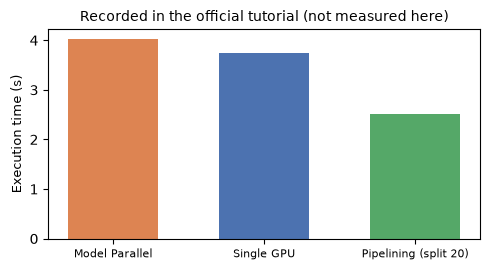

In [122]:
# 공식 튜토리얼에 기록된 값이며 이 노트북에서 잰 값이 아닙니다
recorded = {"Model Parallel": 4.02, "Single GPU": 3.75, "Pipelining (split 20)": 2.51}
print(f"모델 병렬은 단일 GPU보다 {recorded['Model Parallel'] / recorded['Single GPU'] - 1:.0%} 느림")
print(f"파이프라인은 단일 GPU보다 처리 속도가 {recorded['Single GPU'] / recorded['Pipelining (split 20)'] - 1:.0%} 빠름")
print(f"파이프라인은 단일 GPU보다 시간이 {1 - recorded['Pipelining (split 20)'] / recorded['Single GPU']:.0%} 짧음")

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(list(recorded), list(recorded.values()), color=["#dd8452", "#4c72b0", "#55a868"], width=0.6)
ax.set_ylabel("Execution time (s)", fontsize=9)
ax.set_title("Recorded in the official tutorial (not measured here)", fontsize=10)
ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

In [123]:
split_sizes = [1, 3, 5, 8, 10, 12, 20, 40, 60]

if NUM_GPUS >= 2:
    means = []
    stds = []
    for split_size in split_sizes:
        setup = "model = PipelineParallelResNet50(split_size=%d)" % split_size
        pp_run_times = timeit.repeat(stmt, setup, number=1, repeat=num_repeat, globals=globals())
        means.append(np.mean(pp_run_times))
        stds.append(np.std(pp_run_times))

    fig, ax = plt.subplots()
    ax.plot(split_sizes, means)
    ax.errorbar(split_sizes, means, yerr=stds, ecolor="red", fmt="ro")
    ax.set_ylabel("ResNet50 Execution Time (Second)")
    ax.set_xlabel("Pipeline Split Size")
    ax.set_xticks(split_sizes)
    ax.yaxis.grid(True)
    plt.tight_layout()
    plt.savefig("split_size_tradeoff.png")
    plt.show()
    plt.close(fig)
else:
    print(f"GPU가 {NUM_GPUS}개라서 split_size 실험을 건너뜁니다. 후보: {split_sizes}")

GPU가 0개라서 split_size 실험을 건너뜁니다. 후보: [1, 3, 5, 8, 10, 12, 20, 40, 60]


공식 튜토리얼의 실험에서는 `split_size`가 12일 때 **처리 속도가 54% 빨라져** 가장 좋았습니다(그래프: [split_size_tradeoff.png](https://tutorials.pytorch.kr/_static/img/model-parallel-images/split_size_tradeoff.png)). 곡선은 U자 모양으로, 너무 작아도 너무 커도 느려집니다.

더 빠르게 할 방법도 있습니다. 지금은 첫 번째 GPU의 모든 연산이 기본 스트림에서 이루어지므로, 다음 조각의 계산이 현재 조각의 복사와 겹칠 수 없습니다. 두 조각은 서로 다른 텐서를 쓰므로 겹쳐도 문제가 없습니다. 이렇게 하려면 GPU마다 스트림을 여러 개 쓰고, 서브 네트워크마다 스트림 전략을 달리해야 합니다. 모델 병렬에서 여러 스트림을 쓰는 일반적인 방법은 없으므로 여기서는 다루지 않습니다.

> **참고**: 이 수치들은 예시입니다. 실행할 때마다, 소프트웨어와 하드웨어에 따라 결과가 달라집니다. 자신의 환경에서 가장 좋은 성능을 얻으려면 곡선을 직접 그려 최적의 `split_size`를 찾으세요.

Q. 다음 상황에서 각각 어떤 방법을 쓰겠습니까? (가) 모델은 GPU 하나에 들어가는데 데이터가 많아 학습이 느리다. (나) 모델이 GPU 하나의 메모리보다 크다.

<details><summary>답</summary>

(가) 데이터 병렬, 지금은 `DistributedDataParallel`입니다. (나) 모델 병렬입니다. 필요하면 파이프라인을 더해 노는 시간을 줄입니다. 둘을 함께 쓸 수도 있습니다.

</details>

### 실습 8. `scatter`의 분배 규칙

배치 크기 `batch`, GPU 수 `gpus`를 받아 GPU마다 받을 샘플 수의 리스트를 돌려주는 `split_sizes_of(batch, gpus)`를 `torch.chunk`를 **쓰지 않고** 작성하세요. 조각 크기는 올림한 `ceil(batch / gpus)`이고, 남은 샘플이 없으면 끝납니다. 8.2절의 기록과 맞는지 assert로 확인하세요. 예를 들어 `split_sizes_of(10, 3)`은 `[4, 4, 2]`, `split_sizes_of(10, 8)`은 `[2, 2, 2, 2, 2]`입니다.

In [124]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def split_sizes_of(batch: int, gpus: int) -> list[int]:
    """torch.chunk와 같은 규칙으로 샘플 수를 나눕니다."""
    size = -(-batch // gpus)     # 올림 나눗셈
    result = []
    while batch > 0:
        result.append(min(size, batch))
        batch -= result[-1]
    return result

assert split_sizes_of(30, 2) == [15, 15]
assert split_sizes_of(10, 3) == [4, 4, 2]
assert split_sizes_of(30, 8) == [4, 4, 4, 4, 4, 4, 4, 2]
assert split_sizes_of(10, 8) == [2, 2, 2, 2, 2]
for b, g in [(30, 2), (30, 3), (10, 3), (30, 8), (10, 8), (7, 4)]:
    assert split_sizes_of(b, g) == [len(c) for c in torch.zeros(b).chunk(g)]
print(split_sizes_of(10, 3))
```
</details>

---
# 부록. 학습 패러다임 정리

다음에 공부할 분야를 고를 때 쓸 수 있도록 학습 패러다임을 표로 정리합니다.

| 패러다임 | 라벨 상황 | 대표 예 |
|---|---|---|
| Supervised (지도) | 모든 입력에 정답 라벨이 있다 | 지금까지의 분류 학습 |
| Unsupervised (비지도) | 입력만 있고 라벨이 없다 | 군집화, 7강의 차원 축소 |
| Semi-supervised (준지도) | 일부 데이터에만 라벨이 있다 | pseudo label, meta pseudo labels |
| Weakly supervised (약지도) | 라벨은 있지만, 풀려는 과제보다 **거친 정보**만 있다. 예: 검출과 인식에 모두 라벨이 필요한데 이미지 단위의 인식 라벨만 있다 | **오늘의 CAM**: 분류 라벨만으로 위치를 찾는다 |
| Self-supervised (자기지도) | 사람의 라벨 없이 입력에서 과제를 만든다. 입력 $X$에 변형 $z$를 적용해 $X_z$를 만들고, $X_z$로부터 $X$나 $z$를 예측한다 | 회전 예측, 대조 학습 |
| Reinforcement (강화) | 정답 대신 행동에 대한 보상이 주어진다 | 게임, 로봇 제어 |

**Self-training**은 준지도 방법의 하나입니다. 라벨이 있는 $X$로 모델을 학습한 뒤, 라벨 없는 $X'$을 예측합니다. 그중 신뢰도가 높은 예측을 라벨로 삼아(pseudo label) 다시 학습합니다.

---
# 오늘의 요약

- **CAM**: GAP 모델에서 클래스 점수는 위치별 기여의 평균입니다. 선형층 가중치를 특징 맵에 곱하면 히트맵이 됩니다. `logit = mean(CAM) + bias`를 수치로 확인했습니다.
- **Grad-CAM**: 가중치를 기울기 평균으로 바꾸어 어떤 모델, 어떤 층에도 쓸 수 있습니다. GAP 구조에서는 $\alpha_k = w_k / Z$로 CAM과 일치합니다.
- **Guided Grad-CAM**: 세밀하지만 클래스 구분이 약한 Guided Backprop에 Grad-CAM을 곱합니다.
- **LayerCAM**: 위치별 가중치를 써서 앞쪽 층에서도 동작합니다. 층마다 해상도와 보는 범위가 다릅니다. 층을 합칠 수도 있지만, 오늘의 그림에서는 깊은 층의 모양이 대부분을 차지했습니다.
- **TorchScript**: trace는 실행된 경로만 기록하므로 분기가 있으면 **조용히 틀립니다**. script는 소스를 컴파일합니다. `torch.jit`은 지금 지원 중단 경고가 나오며, 새 작업에는 `torch.compile`, `torch.export`, ONNX를 씁니다.
- **ONNX**: 프레임워크와 실행 환경 사이의 공통 형식입니다. 내보낸 뒤 **PyTorch 출력과 수치로 비교**합니다.
- **배포 경로**: 파이썬 서버는 웹 프레임워크와 `torch.compile` 또는 ONNX Runtime, 모바일은 `torch.export`와 ExecuTorch를 기본으로 고려합니다. TorchServe는 유지보수되지 않습니다.
- **JAX**: `grad`, `jit`, `vmap`이라는 함수 변환으로 상태 없는 신경망을 만듭니다.
- **Ray Tune**: 탐색 공간, 학습 함수, 스케줄러로 구성합니다. ASHA가 나쁜 시도를 일찍 멈춥니다.
- **병렬**: 데이터 병렬은 복제와 분할(지금은 DDP), 모델 병렬은 층 나누기입니다. 모델 병렬은 그 자체로 빨라지지 않고, 파이프라인을 더해야 노는 시간이 줄어듭니다.

# 숙제

1. **Ray Tune을 자신의 모델에 적용**하세요. 2교시의 CIFAR ResNet18에 학습률과 weight decay를 탐색 공간으로 두고 작은 탐색을 실행합니다. `train_cifar_model`을 그대로 넘기지 말고 7.4절의 형식으로 새로 쓰세요. 전역 변수 `cifar_x_train`을 참조하면 수백 MB의 데이터가 함수와 함께 직렬화됩니다. 데이터는 **학습 함수 안에서 절대 경로로** 읽으세요. 시도마다 실행 폴더가 달라 `./data`는 다른 곳을 가리킵니다.
2. 2.3절의 `layer_k`를 5, 6, 8로 바꾸어 Grad-CAM의 해상도와 위치가 어떻게 달라지는지 비교하세요. 이어서 `CIFAR_EPOCHS`를 늘려 기본 모델과 MixUp, FMix의 차이가 달라지는지 보세요. 시드를 여러 개 써야 결론을 낼 수 있습니다.
3. 모델의 틀린 예측을 골라 Grad-CAM을 그려 보세요. 정답 클래스와 예측 클래스의 히트맵을 나란히 보면 왜 틀렸는지 단서를 얻을 수 있습니다.
4. 6교시의 로더를 `shuffle=True`로 바꾸고, 픽셀을 255로 나누고, `loss`를 진짜 교차 엔트로피로 바꾸어 보세요. 학습률은 어떻게 조정해야 할까요?
5. 5교시의 초해상도 모델을 가로와 세로까지 동적인 ONNX로 내보내 다양한 크기의 이미지를 처리해 보세요.
6. GPU가 2개 이상인 환경을 쓸 수 있다면 8교시를 다시 실행해 `split_size` 곡선을 직접 그려 보세요.

# 더 읽을거리

- CAM 논문: [Learning Deep Features for Discriminative Localization](https://openaccess.thecvf.com/content_cvpr_2016/html/Zhou_Learning_Deep_Features_CVPR_2016_paper.html)
- Grad-CAM 논문: [arXiv:1610.02391](https://arxiv.org/abs/1610.02391)
- 다양한 CAM 구현: [pytorch-grad-cam](https://github.com/jacobgil/pytorch-grad-cam), [TorchCAM](https://github.com/frgfm/torch-cam)
- 배포: [ExecuTorch](https://docs.pytorch.org/executorch/stable/index.html), [FastAPI](https://fastapi.tiangolo.com/)
- 내보내기: [torch.export 문서](https://pytorch.org/docs/stable/export.html), [torch.onnx 문서](https://pytorch.org/docs/stable/onnx.html), [torch.compile 튜토리얼](https://pytorch.org/tutorials/intermediate/torch_compile_tutorial.html)
- JAX: [공식 문서](https://docs.jax.dev/en/latest/), [신경망 라이브러리 Flax](https://flax.readthedocs.io/)
- 탐색: [Ray Tune 문서](https://docs.ray.io/en/latest/tune/index.html), [Optuna](https://optuna.org/)
- 병렬: [DDP 튜토리얼](https://pytorch.org/tutorials/intermediate/ddp_tutorial.html), [torchrun 문서](https://pytorch.org/docs/stable/elastic/run.html)